# โทรหาใครก่อน? ใช้ข้อมูลจัดลำดับการโทรเสนอเงินฝากประจำ

> **คำถามธุรกิจ:** ธนาคารควรโทรหาลูกค้าคนไหนก่อน โทรกี่ครั้ง และผ่านช่องทางไหน จึงได้ผู้ฝากเงินประจำมากที่สุดต่อบาทที่ใช้?

- **มุมการเงิน:** เงินฝากประจำเป็นเงินทุนต้นทุนต่ำของธนาคาร ทุกสายที่โทรคือต้นทุนการหาลูกค้า (CPA) ซึ่งต้องคุ้มกับส่วนต่างดอกเบี้ยที่ได้กลับมา
- **มุม operations:** คอลเซ็นเตอร์มีจำนวนสายจำกัด ต้องเลือกให้ได้ว่าจะโทรหาใคร กี่ครั้ง ผ่านช่องทางไหน

### ข้อสรุปใน 30 วินาที

1. **อัตราสมัครเปลี่ยนตามช่วงเวลามาก** (5% → 11% → 31%) มากกว่าความต่างระหว่างกลุ่มลูกค้าเสียอีก
2. **โมเดลเรียงรายชื่อได้ดีกว่าการสุ่มชัดเจน** (ได้ ~449 เทียบกับ 308 ผู้สมัครต่อ 1,000 สาย) แต่ **ชนะกฎง่าย ๆ "เคยตอบรับก่อน" เพียงเล็กน้อย** (432 ราย) และเมื่อเปลี่ยนวิธีแบ่งข้อมูล บางแบบแพ้กฎด้วย (3.8) สัญญาณหลักมาจากประวัติแคมเปญ
3. **ไม่ควรตั้งเป็นเปอร์เซ็นต์คงที่** ว่าจะโทรกี่ราย ให้โทรเมื่อโอกาสสมัครที่คาด > ค่าโทร ÷ มูลค่า แล้วปรับตามอัตราสมัครของรอบล่าสุด
4. **ข้อเสนอเชิงปฏิบัติ:** โทรเบอร์มือถือก่อน (ได้ผล ~1.5 เท่า), ให้ความสำคัญกับวัย <25 และ 60+, หยุดโทรซ้ำเมื่ออัตราต่อสายต่ำกว่าจุดคุ้มทุน, และพิสูจน์ด้วย A/B test ก่อนขยายผล

### ฉบับนี้: เรียงแบบเล่าเรื่อง (storytelling)

ไฟล์นี้มีเนื้อหาและโค้ดชุดเดียวกับ `Bank_Model_and_Business_Scenarios.ipynb` (ซึ่งเรียงหัวข้อตามต้นฉบับของเพื่อน) แต่จัดลำดับใหม่ให้อ่านเป็นเรื่องเดียว และเติม EDA จาก `Bank_EDA/Bank_Marketing_EDA.ipynb` เข้าไปในบทที่ 2

| บท | คำถาม | วิชาที่ใช้ |
|---|---|---|
| 1 ข้อมูล | ใช้ข้อมูลอะไร เชื่อได้แค่ไหน เงินคิดจากอะไร | W1 data collection, secondary data |
| 2 รู้จักลูกค้า | ลูกค้าหน้าตาเป็นอย่างไร มีกลุ่มแบบไหน | W1 EDA/missing/outlier, W4 K-means |
| 3 โมเดล | ข้อมูลก่อนโทรเรียงรายชื่อได้ดีแค่ไหน | classification, validation, AP/AUC |
| 4 เงิน | ควรโทรกี่ราย | W1 KPI/CPA, break-even, calibration |
| 5 Insight | มีอะไรที่ทำได้ทันที | W12 data storytelling |
| 6 ข้อเสนอ | เสนออะไร ให้ใคร ผ่านช่องทางไหน พิสูจน์อย่างไร | W4 STP/4Ps, W1 A/B test |
| ภาคผนวก | การทดลองเสริมและเตรียมตอบคำถาม | — |

**ข้อควรรู้ก่อนอ่าน:** ข้อมูลเป็นของธนาคารในโปรตุเกส ปี 2008–2010 ทุกผลลัพธ์เป็นความสัมพันธ์ย้อนหลัง ยังไม่ใช่ผลเชิงเหตุ และตัวเลขเงินมาจากแหล่งภายนอก (ดู 1.4)

### เตรียมเครื่องมือและค่าตั้งต้น

ติดตั้งแพ็กเกจ กำหนด seed ขนาดรอบ 500 รายชื่อ ชุดสีที่ผ่านการตรวจตาบอดสี และค่าคงที่ของเงิน (ที่มาใน 1.4)

In [1]:
import importlib.util, subprocess, sys
packages = {'numpy':'numpy', 'pandas':'pandas', 'matplotlib':'matplotlib',
            'sklearn':'scikit-learn', 'IPython':'ipython'}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Packages ready')


Packages ready


In [2]:
from pathlib import Path
import io, zipfile, urllib.request, hashlib, json, platform
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 42
BATCH_SIZE = 500
FRACTIONS = np.round(np.linspace(0, 1, 101), 2)
ROOT = Path.cwd()
OUT = ROOT / 'results_model_and_business'
OUT.mkdir(exist_ok=True)

MODEL_OUT=OUT/'model'
BUSINESS_OUT=OUT/'business_simulation'
MODEL_OUT.mkdir(exist_ok=True)
BUSINESS_OUT.mkdir(exist_ok=True)


In [3]:
# Shared style for the storytelling charts (W12: highlight one thing, grey the rest)
# Categorical slots 1-3 of a CVD-validated palette (validate_palette.js: all checks pass, aqua needs direct labels)
HL, HL2 = '#2a78d6', '#1baf7a'            # focus series / second focus
GREY, LIGHT = '#8f8e89', '#dcdbd6'        # context marks
WARN = '#52514e'                          # reference lines (break-even, fences): ink, not a series colour
INK, INK2 = '#0b0b0b', '#52514e'
PERIOD_COLORS = {'Train': '#2a78d6', 'Validation': '#eb6834', 'Test': '#1baf7a'}   # fixed per entity, never by rank
CHANNEL_COLORS = {'cellular': '#2a78d6', 'telephone': '#eb6834'}
from matplotlib.colors import LinearSegmentedColormap
DIVERGING = LinearSegmentedColormap.from_list('blue_grey_red', ['#2a78d6', '#f0efec', '#e34948'])
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
                     'text.color': INK, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.edgecolor': '#b9b8b3', 'lines.linewidth': 2})

In [4]:
# Money assumptions used in chapters 4-6 (sources in 1.4)
CALL_COST = 50.                                   # THB per call attempt
VALUE_LOW, VALUE_BASE, VALUE_HIGH = 500., 1500., 3000.   # THB value per subscriber

# บทที่ 1 ข้อมูล: ใช้อะไร เชื่อได้แค่ไหน

**คำถามของบท:** ข้อมูลมาจากไหน ใช้ตัวแปรไหน แบ่งอย่างไร และเงินคิดจากอะไร

## 1.1 ที่มาของข้อมูล และทำไมเลือกชุดนี้

> 🔧 **เทคนิค:** โหลดข้อมูลแบบมี assert ตรวจขนาด + SHA256  
> 🎯 **ทำไม:** ยืนยันว่าทุกคนใช้ไฟล์ชุดเดียวกัน ถ้าไฟล์เปลี่ยน โค้ดจะหยุดทันที  
> 🗣️ **พูดว่า:** “ข้อมูลมี 41,188 รายการ สมัคร 4,640 ราย หรือราว 11% และเราตรวจรหัสไฟล์ไว้ว่าทุกคนใช้ข้อมูลชุดเดียวกัน”

โหลด `bank-additional-full.csv` จาก UCI ตรวจขนาด และบันทึกรหัส SHA256 หนึ่งแถวไม่จำเป็นต้องเท่ากับลูกค้าหนึ่งคน (ไม่มีรหัสลูกค้า) จึงไม่ลบแถวที่ซ้ำกัน

In [5]:
SOURCE_URL = 'https://archive.ics.uci.edu/static/public/222/bank+marketing.zip'
DATA = ROOT / 'bank-additional-full.csv'
if not DATA.exists():
    with urllib.request.urlopen(SOURCE_URL, timeout=90) as response:
        outer = zipfile.ZipFile(io.BytesIO(response.read()))
    inner = zipfile.ZipFile(io.BytesIO(outer.read('bank-additional.zip')))
    DATA.write_bytes(inner.read('bank-additional/bank-additional-full.csv'))
raw = pd.read_csv(DATA, sep=';')
assert raw.shape == (41188, 21), raw.shape
assert set(raw.y.unique()) == {'yes','no'}
y = raw.y.eq('yes').astype(int)
print(f'Records={len(raw):,}; subscribers={y.sum():,}; rate={y.mean():.2%}')
print('Identical full rows retained:', raw.duplicated().sum())
print('SHA256:', hashlib.sha256(DATA.read_bytes()).hexdigest())


Records=41,188; subscribers=4,640; rate=11.27%
Identical full rows retained: 12
SHA256: 74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8


#### ทำไมเลือกชุดนี้

> 🔧 **เทคนิค:** ประเมินแหล่งข้อมูลแบบ secondary data (W1)  
> 🎯 **ทำไม:** ตอบ rubric ว่าทำไมข้อมูลนี้ตอบคำถามได้ และมีข้อจำกัดอะไร  
> 🗣️ **พูดว่า:** “เราเลือกข้อมูลทุติยภูมิจาก UCI เพราะเป็นแคมเปญจริงที่มีผลลัพธ์ ซึ่งหาได้ยาก แต่ต้องยอมรับว่าเป็นข้อมูลโปรตุเกสช่วงปี 2008–2010”

| ประเด็น | คำอธิบาย |
|---|---|
| แหล่งข้อมูล | [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing) (Moro, Cortez & Rita, 2014) แคมเปญโทรขายเงินฝากประจำของธนาคารในโปรตุเกส 41,188 รายการ, CC BY 4.0 |
| ประเภท (W1) | **ข้อมูลทุติยภูมิ** ที่เปิดสาธารณะ และเป็นข้อมูลแคมเปญจริงที่มีผลลัพธ์ (สมัคร / ไม่สมัคร) ซึ่งหาได้ยาก |
| ตรงกับคำถามไหม | มีทั้งข้อมูลลูกค้า ประวัติแคมเปญ ช่องทาง จำนวนครั้งที่โทร และผลลัพธ์ ใช้ตอบได้ทั้งเรื่องใคร กี่ครั้ง ช่องทางไหน และคุ้มไหม |
| ข้อจำกัด | ช่วง พ.ค. 2008 – พ.ย. 2010 (วิกฤตการเงิน) จากประเทศเดียว ไม่มีรายได้ ยอดเงินฝาก หรือรหัสลูกค้า |

## 1.2 ใช้เฉพาะข้อมูลที่รู้ก่อนโทร และแบ่งตามเวลา

> 🔧 **เทคนิค:** เลือก feature ที่รู้ก่อนโทร, แปลง `pdays` เป็นกลุ่ม, แบ่ง Train/Val/Test ตามลำดับเวลา  
> 🎯 **ทำไม:** กัน data leakage และจำลองการใช้งานจริงที่ต้องใช้อดีตทำนายอนาคต  
> 🗣️ **พูดว่า:** “เราใช้เฉพาะข้อมูลที่รู้ก่อนโทร และแบ่งตามเวลา จะเห็นว่าอัตราสมัครขยับจาก 5% เป็น 11% และ 31% ในแต่ละชุด”

- **ใช้ในโมเดล:** อายุ อาชีพ สถานภาพ การศึกษา สถานะสินเชื่อ ประวัติแคมเปญก่อนหน้า
- **ตัดออก:** `duration` (รู้หลังวางสาย ดู 5.4), `campaign` (นับรวมการโทรครั้งนี้), ช่องทางและวันเดือน (ยังไม่แน่ใจว่ารู้ก่อนเลือกรายชื่อ), ตัวแปรเศรษฐกิจ (ทดลองแยกใน ภาคผนวก ก)
- `pdays = 999` แปลว่า **ไม่เคยติดต่อ** จึงแปลงเป็นกลุ่ม `never / 0-3d / 4-7d / 8d+` แทนการเติม 0 ซึ่งจะไปปนกับคนที่เพิ่งติดต่อ ส่วน `unknown` เก็บเป็นกลุ่มหนึ่ง
- **แบ่งตามลำดับเวลา** Train 60% / Validation 20% / Test 20% ให้เหมือนตอนใช้งานจริงที่ต้องใช้อดีตทำนายอนาคต (ดู 3.8 ว่าทำไมไม่สุ่ม)

,split,records,positive,rate
0,Train,24712,1188,0.048074
1,Validation,8238,912,0.110706
2,Test,8238,2540,0.308327


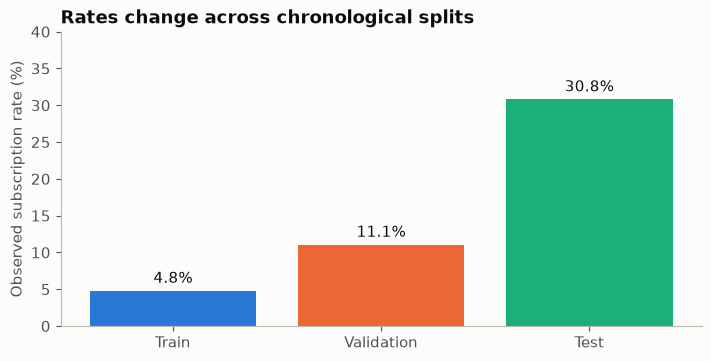

In [6]:
KEEP = ['age','job','marital','education','default','housing','loan',
        'pdays','previous','poutcome']
X = raw[KEEP].copy()
# pdays=999 means "never contacted"; bin real gaps so never != 0 days ago
X['pdays_band'] = (pd.cut(X.pdays.where(X.pdays.ne(999)), [-1, 3, 7, 30], labels=['0-3d', '4-7d', '8d+'])
                   .astype(str).replace('nan', 'never'))
assert X.pdays_band.eq('never').sum() == raw.pdays.eq(999).sum()
X = X.drop(columns='pdays')
CAT = list(X.select_dtypes(include=['object','string']).columns)
NUM = [c for c in X if c not in CAT]
n = len(y)
cut1, cut2 = int(n*.6), int(n*.8)
train, valid, test = slice(0,cut1), slice(cut1,cut2), slice(cut2,n)
splits = pd.DataFrame([dict(split=name,records=len(y.iloc[s]),
    positive=int(y.iloc[s].sum()),rate=float(y.iloc[s].mean()))
    for name,s in [('Train',train),('Validation',valid),('Test',test)]])
display(splits)
splits.to_csv(MODEL_OUT/'split_summary.csv',index=False)
fig,ax=plt.subplots(figsize=(7,3.5),layout='constrained')
b=ax.bar(splits.split,splits.rate*100,color=list(PERIOD_COLORS.values()))
ax.bar_label(b,fmt='%.1f%%',padding=3)
ax.set(ylabel='Observed subscription rate (%)',title='Rates change across chronological splits',ylim=(0,40))
fig.savefig(MODEL_OUT/'01_split_rates.png',dpi=160);plt.show()


บทบาทของตัวแปรแต่ละกลุ่ม (จาก EDA เดิม):

In [7]:
# Variable roles (from the separate EDA notebook)
EDA_OUT = MODEL_OUT / 'eda'; EDA_OUT.mkdir(exist_ok=True)
roles = pd.DataFrame([
    {'variables': 'age, job, marital, education, default, housing, loan, pdays, previous, poutcome', 'role': 'Used: pre-contact', 'reason': 'Customer profile and previous-campaign history'},
    {'variables': 'duration', 'role': 'Excluded: post-call', 'reason': 'Only known after the call ends (see 5.4)'},
    {'variables': 'campaign', 'role': 'Excluded from model', 'reason': 'Includes the current contact (used descriptively in 5.1)'},
    {'variables': 'contact, month, day_of_week', 'role': 'Context only', 'reason': 'Channel/schedule may not be set at selection (see 5.2, 5.6)'},
    {'variables': 'emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed', 'role': 'Tested as Model B', 'reason': 'Previous-month values (appendix A)'},
    {'variables': 'y', 'role': 'Outcome', 'reason': 'Historical subscription, never a predictor'}])
display(roles); roles.to_csv(EDA_OUT/'feature_roles.csv', index=False)

,variables,role,reason
0,"age, job, marital, education, default, housing...",Used: pre-contact,Customer profile and previous-campaign history
1,duration,Excluded: post-call,Only known after the call ends (see 5.4)
2,campaign,Excluded from model,Includes the current contact (used descriptive...
3,"contact, month, day_of_week",Context only,Channel/schedule may not be set at selection (...
4,"emp.var.rate, cons.price.idx, cons.conf.idx, e...",Tested as Model B,Previous-month values (appendix A)
5,y,Outcome,"Historical subscription, never a predictor"


## 1.3 ข้อมูลครอบคลุมช่วงไหน

> 🔧 **เทคนิค:** สร้างปี-เดือนจากลำดับแถว + กราฟ small multiples (เส้นเวลา)  
> 🎯 **ทำไม:** ให้เห็นว่าแต่ละชุดข้อมูลอยู่คนละสภาวะตลาด ซึ่งอธิบายผลที่เปลี่ยนไปทั้งเล่ม  
> 🗣️ **พูดว่า:** “หลังกลางปี 2009 ธนาคารโทรน้อยลงจากหลักพันเหลือหลักร้อยต่อเดือน แต่อัตราสมัครพุ่งไปถึง 34–58% ช่วงเดียวกับที่ดอกเบี้ยดิ่งลงในวิกฤต”

ไฟล์ไม่มีคอลัมน์ปี แต่เอกสารระบุว่าแถวเรียงตามวันที่ จึงไล่เดือนทีละแถวและนับปีเพิ่มเมื่อเดือนวนกลับ ผลจบที่ พ.ย. 2010 พอดี ตรงกับเอกสาร

**ภาพนี้คือจุดเริ่มของเรื่อง:** หลังกลางปี 2009 ธนาคารโทรน้อยลงมาก แต่อัตราสมัครพุ่งขึ้น ขณะที่ดอกเบี้ย Euribor ดิ่งลงช่วงวิกฤต Train, Validation และ Test จึงอยู่คนละสภาวะตลาด

,first,last,records,rate
Train,2008-05,2008-11,24712,0.048074
Validation,2008-11,2009-05,8238,0.110706
Test,2009-05,2010-11,8238,0.308327


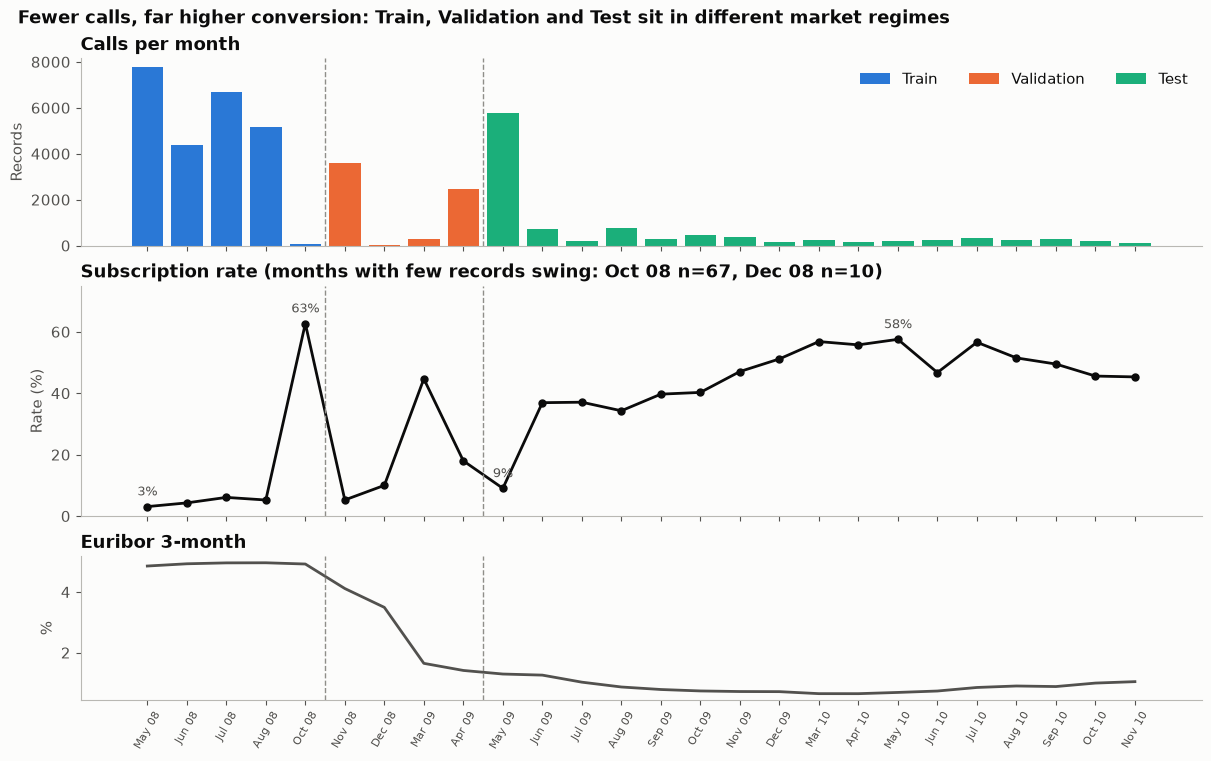

In [8]:
# Rebuild calendar month from file order (documented as date-ordered, May 2008 - Nov 2010)
MONTH_NO = {m: i for i, m in enumerate(['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec'], 1)}
month_no = raw.month.map(MONTH_NO).to_numpy()
year_no = 2008 + np.r_[0, np.cumsum(np.diff(month_no) < 0)]
year_month = pd.Series(pd.PeriodIndex.from_fields(year=year_no, month=month_no, freq='M'), index=raw.index)
assert str(year_month.iloc[0]) == '2008-05' and str(year_month.iloc[-1]) == '2010-11'

n_rows = len(raw); c1, c2 = int(n_rows*.6), int(n_rows*.8)
split_name = pd.Series(np.select([np.arange(n_rows) < c1, np.arange(n_rows) < c2], ['Train', 'Validation'], 'Test'))
split_months = pd.DataFrame({s: dict(first=str(year_month[split_name.eq(s)].min()), last=str(year_month[split_name.eq(s)].max()),
                                     records=int(split_name.eq(s).sum()), rate=float(raw.y.eq('yes')[split_name.eq(s)].mean()))
                             for s in ['Train', 'Validation', 'Test']}).T
display(split_months)
split_months.to_csv(MODEL_OUT/'split_calendar.csv')

monthly = (raw.assign(ym=year_month, yes=raw.y.eq('yes'))
           .groupby('ym').agg(records=('yes', 'size'), rate=('yes', 'mean'), euribor=('euribor3m', 'mean')))
monthly.to_csv(MODEL_OUT/'monthly_timeline.csv')
tl_pos = np.arange(len(monthly)); tl_labels = [p.strftime('%b %y') for p in monthly.index]
month_split = (pd.DataFrame({'ym': year_month, 'split': split_name.to_numpy()})
               .groupby('ym').split.agg(lambda v: v.value_counts().index[0])).reindex(monthly.index)
cut_pos = [list(monthly.index).index(year_month.iloc[c]) - .5 for c in (c1, c2)]
fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True, layout='constrained', height_ratios=[1.3, 1.6, 1])
for sp, col in PERIOD_COLORS.items():
    m = month_split.eq(sp).to_numpy()
    a1.bar(tl_pos[m], monthly.records[m], color=col, width=.8, label=sp)
a1.set_ylabel('Records'); a1.legend(frameon=False, ncol=3, loc='upper right'); a1.set_title('Calls per month')
a2.plot(tl_pos, monthly.rate*100, color=INK, marker='o', ms=5)
for i in [0, 4, 9, 19]:
    a2.annotate(f'{monthly.rate.iloc[i]:.0%}', (tl_pos[i], monthly.rate.iloc[i]*100), textcoords='offset points',
                xytext=(0, 8), ha='center', fontsize=9, color=INK2)
a2.set_ylabel('Rate (%)'); a2.set_ylim(0, 75); a2.set_title('Subscription rate (months with few records swing: Oct 08 n=67, Dec 08 n=10)')
a3.plot(tl_pos, monthly.euribor, color=INK2); a3.set_ylabel('%'); a3.set_title('Euribor 3-month')
for a in (a1, a2, a3):
    for x in cut_pos: a.axvline(x, color=GREY, ls='--', lw=1)
a3.set_xticks(tl_pos, tl_labels, rotation=60, fontsize=8)
fig.suptitle('Fewer calls, far higher conversion: Train, Validation and Test sit in different market regimes',
             fontweight='bold', x=.01, ha='left')
fig.savefig(MODEL_OUT/'00_timeline.png', dpi=160); plt.show()


## 1.4 เงินคิดจากอะไร: สมมติฐานชุดเดียวทั้งเล่ม

> 🔧 **เทคนิค:** Unit economics + ตารางแหล่งอ้างอิง (แยกสิ่งที่อ้างอิงกับสิ่งที่สมมติเอง)  
> 🎯 **ทำไม:** ทำให้ตัวเลขเงินตรวจสอบได้และตอบ Q&A ได้  
> 🗣️ **พูดว่า:** “ตัวเลขเงินมาจากแหล่งอ้างอิง ค่าโทรราว 50 บาทต่อสาย และเงินฝากหนึ่งรายให้มูลค่าราว 1,500 บาท เราแยกไว้ชัดว่าส่วนไหนอ้างอิง ส่วนไหนสมมติเอง”

ข้อมูลไม่มีต้นทุนหรือมูลค่า จึงใช้ตัวเลขจากแหล่งภายนอก **ชุดเดียวกันทั้งเล่ม** แล้วทดลองช่วงต่ำ-สูงรวม 27 สถานการณ์ใน ภาคผนวก ง

| สมมติฐาน | ค่าที่ใช้ | ได้มาอย่างไร |
|---|---|---|
| ค่าโทรต่อสาย | **50 บาท** (ทดลอง 25–100) | ค่า outsource คอลเซ็นเตอร์ไทย $8–15 ต่อชั่วโมง ÷ 8–15 สายต่อชั่วโมง ≈ 18–62 บาท แล้วเลือกค่ากลาง |
| จำนวนสายต่อราย | **ค่าเฉลี่ย `campaign` ใน Train** (ทดลอง 1–4) | คำนวณจากข้อมูล |
| มูลค่าต่อผู้สมัคร | **1,500 บาท** (ทดลอง 500–3,000) | เงินฝาก 100,000 บาท × ส่วนต่างดอกเบี้ย 1.5% × 1 ปี (NIM ธนาคารไทยปี 2025 = 2.54%) |

**แหล่งอ้างอิง** (เข้าถึง 10 พ.ย. 2026)

| ตัวเลข | ค่า | แหล่ง |
|---|---|---|
| ค่า outsource คอลเซ็นเตอร์ไทย | $8–15 ต่อชั่วโมง | [callin.io](https://callin.io/outsource-call-center-thailand/) (blog ผู้ให้บริการ) |
| ค่า outsource nearshore / ยุโรปตะวันตก | $13–23 / $35–45 ต่อชั่วโมง | [CloudTalk](https://www.cloudtalk.io/blog/outsourced-call-center-pricing/), [Time Doctor](https://www.timedoctor.com/blog/outsourced-call-center-pricing/) |
| เงินเดือน telemarketer ไทย | ช่วง 80% อยู่ที่ 5,283–23,416 บาทต่อเดือน | [Paylab](https://paylab.com/th/salaryinfo/commerce/telemarketer) |
| ค่าแรงขั้นต่ำกรุงเทพฯ / โปรตุเกส | 400 บาทต่อวัน (2025) / €450–475 (2009–10) | [Khaosod](https://www.khaosodenglish.com/news/business/2025/07/01/bangkok-minimum-wage-rises-to-400-baht-benefiting-700000-workers/), [Eurofound](https://www.eurofound.europa.eu/en/publications/all/employers-dispute-statutory-minimum-wage-increase) |
| จำนวนสายต่อชั่วโมง | ~15.6 (benchmark งาน B2C) | [Vida](https://vida.io/blog/how-many-outbound-calls-per-day) |
| NIM ธนาคารไทย / โปรตุเกส | 2.54% (2025) / 1.86% (2009) | [Nation Thailand](https://www.nationthailand.com/business/banking-finance/40062641), [FRED](https://fred.stlouisfed.org/data/DDEI01PTA156NWDB) |
| ดอกเบี้ยเงินฝากไทย | เฉลี่ย 1.15%; ฝากประจำ 12 เดือน 1.65–1.75% | [Trading Economics](https://tradingeconomics.com/thailand/deposit-interest-rate), [Phuket Expat Guide](https://phuketexpatguide.com/blog/thai-savings-accounts-interest-rates-expats/) |
| CPA ลูกค้าเงินฝาก (สหรัฐฯ) | $150–780 | [eMarketer](https://www.emarketer.com/content/how-banks-optimize-cost-per-acquisition), [Curinos](https://www.curinos.com/insights/according-to-the-data-acquisition-trap-is-real) |

**สมมติฐานที่เราตั้งเอง:** 8–15 สายต่อชั่วโมง (จากเวลาคุยเฉลี่ย 258 วินาทีในข้อมูล), overhead ×1.5–2, 1 USD ≈ 33 บาท, เงินฝาก 100,000 บาท และส่วนต่าง 1.5% ตัวเลขต้นทุนส่วนใหญ่มาจาก blog ของผู้ให้บริการ จึงเป็นช่วงคร่าว ๆ ไม่ใช่ใบเสนอราคา

In [9]:
# Cost per customer = cost per call (1.4) x average calls in Train
CALLS_OBS = round(float(raw.campaign.iloc[train].mean()), 1)  # average attempts per customer in Train
COST_PER_CUSTOMER = CALL_COST * CALLS_OBS
print(f'Cost per customer = {CALL_COST:.0f} THB x {CALLS_OBS} calls = {COST_PER_CUSTOMER:.0f} THB; '
      f'value per subscriber = {VALUE_BASE:,.0f} THB -> break-even rate {COST_PER_CUSTOMER/VALUE_BASE:.1%}')

Cost per customer = 50 THB x 2.9 calls = 145 THB; value per subscriber = 1,500 THB -> break-even rate 9.7%


# บทที่ 2 รู้จักลูกค้า: มีกลุ่มแบบไหน

**คำถามของบท:** ลูกค้าใน Train หน้าตาเป็นอย่างไร กลุ่มไหนสมัครมากกว่า และแบ่งกลุ่มตามธรรมชาติได้ไหม ทั้งบทใช้เฉพาะ **Train** เพื่อไม่ให้ผลของช่วงหลังเข้ามามีผลกับการตัดสินใจ

## 2.1 ผู้สมัครมีน้อยแค่ไหน (class imbalance)

> 🔧 **เทคนิค:** นับสัดส่วนผลลัพธ์ (class balance) จาก EDA เดิม
> 🎯 **ทำไม:** อธิบายว่าทำไมใช้ Accuracy ไม่ได้ ต้องใช้ AP / Precision / Lift
> 🗣️ **พูดว่า:** “ใน Train มีคนสมัครแค่ราว 5% ถ้าทายว่าไม่สมัครทุกคน จะแม่น 95% แต่ไม่ช่วยอะไรเลย เราจึงวัดด้วยการจัดอันดับแทน”

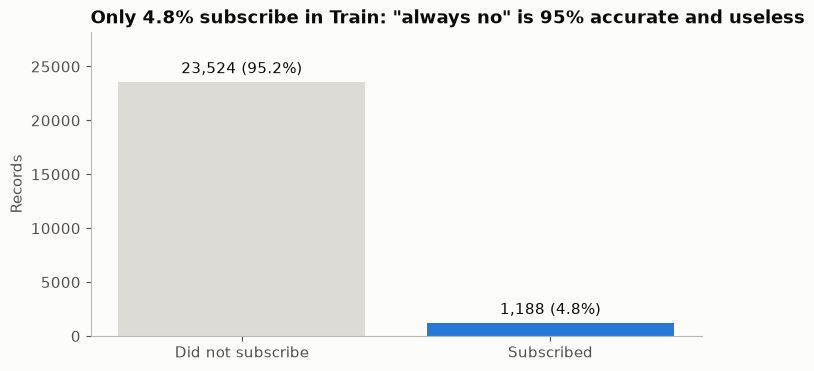

In [10]:
# EDA helpers on Train only (adapted from Bank_EDA/Bank_Marketing_EDA.ipynb)
from matplotlib.ticker import PercentFormatter
eda_df = raw.iloc[train].copy()
eda_df['subscribed'] = eda_df.y.eq('yes').astype(int)
eda_base = eda_df.subscribed.mean()
def save_eda(name):
    plt.savefig(EDA_OUT/(name + '.png'), dpi=160, bbox_inches='tight'); plt.show()
def group_stats(col):
    g = eda_df.groupby(col, observed=True).subscribed.agg(n='size', yes='sum')
    p = g.yes/g.n; z = 1.96; den = 1 + z*z/g.n
    center = (p + z*z/(2*g.n))/den; half = z*np.sqrt(p*(1-p)/g.n + z*z/(4*g.n*g.n))/den
    g['rate'] = p; g['lo'] = center - half; g['hi'] = center + half
    g.to_csv(EDA_OUT/(col + '_rates.csv')); return g
def plot_groups(col, name, sort=True, title=None):
    g = group_stats(col)
    if sort: g = g.sort_values('rate')
    fig, axs = plt.subplots(1, 2, figsize=(11, max(3.2, .38*len(g) + 1)), layout='constrained', sharey=True)
    pos_ = np.arange(len(g))
    axs[0].barh(pos_, g.n, color=GREY); axs[0].set_yticks(pos_, g.index.astype(str)); axs[0].set(xlabel='Records', title='Group size')
    axs[1].errorbar(g.rate, pos_, xerr=[g.rate - g.lo, g.hi - g.rate], fmt='o', color=HL, capsize=3)
    axs[1].axvline(eda_base, color=WARN, ls='--', lw=1, label='Train average'); axs[1].legend(frameon=False, fontsize=9)
    axs[1].xaxis.set_major_formatter(PercentFormatter(1)); axs[1].set(xlabel='Subscription rate (Wilson 95%)', title=col)
    if title: fig.suptitle(title, fontweight='bold', x=.01, ha='left')
    save_eda(name); return g

counts = eda_df.y.value_counts().reindex(['no', 'yes'])
fig, ax = plt.subplots(figsize=(7, 3.6), layout='constrained')
b = ax.bar(['Did not subscribe', 'Subscribed'], counts, color=[LIGHT, HL])
ax.bar_label(b, labels=[f'{v:,} ({v/len(eda_df):.1%})' for v in counts], padding=4)
ax.set(ylabel='Records', ylim=(0, counts.max()*1.2),
       title=f'Only {eda_base:.1%} subscribe in Train: "always no" is {1-eda_base:.0%} accurate and useless')
save_eda('e01_target_balance')

## 2.2 การกระจายของตัวแปรตัวเลข

> 🔧 **เทคนิค:** Histogram + ตารางเปอร์เซ็นไทล์ (W1 descriptive statistics)
> 🎯 **ทำไม:** รู้ขอบเขตของข้อมูลก่อนสร้างโมเดล โดยเฉพาะประวัติการติดต่อที่แทบไม่มีใน Train
> 🗣️ **พูดว่า:** “ใน Train แทบไม่มีใครเคยถูกติดต่อมาก่อน สัญญาณที่แรงที่สุดในภายหลังจึงยังไม่ปรากฏในช่วงนี้”

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
age,24712.0,40.181572,9.262716,18.0,24.0,33.0,39.0,47.0,57.0,59.0,61.0
previous,24712.0,0.005261,0.072340,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


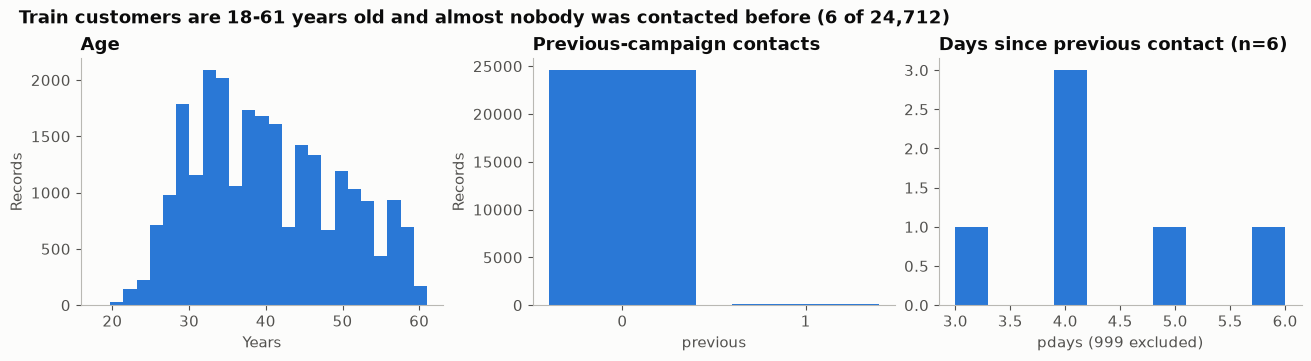

In [11]:
# Distributions of the pre-contact numeric variables (Train)
display(eda_df[['age', 'previous']].describe(percentiles=[.01, .25, .5, .75, .95, .99]).T)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.5), layout='constrained')
axs[0].hist(eda_df.age, bins=25, color=HL); axs[0].set(title='Age', xlabel='Years', ylabel='Records')
v = eda_df.previous.value_counts().sort_index(); axs[1].bar(v.index.astype(str), v, color=HL)
axs[1].set(title='Previous-campaign contacts', xlabel='previous', ylabel='Records')
v = eda_df.loc[eda_df.pdays.ne(999), 'pdays']
axs[2].hist(v, bins=10, color=HL); axs[2].set(title=f'Days since previous contact (n={len(v):,})', xlabel='pdays (999 excluded)')
fig.suptitle(f'Train customers are 18-{eda_df.age.max()} years old and almost nobody was contacted before ({len(v)} of {len(eda_df):,})',
             fontweight='bold', x=.01, ha='left')
save_eda('e02_numeric_distributions')

## 2.3 กลุ่มไหนสมัครมากกว่า

> 🔧 **เทคนิค:** EDA แบบกลุ่ม: ขนาดกลุ่ม + อัตราสมัคร + ช่วง Wilson 95% (ดูเฉพาะ Train)  
> 🎯 **ทำไม:** ไม่ให้กลุ่มเล็กหลอกตา และไม่ให้ผลของ Val/Test มีผลต่อการตัดสินใจ  
> 🗣️ **พูดว่า:** “ใน Train อาชีพต่าง ๆ สมัครราว 3–7% และคนที่เคยตอบรับแคมเปญก่อนมีแค่ 6 คน ต้องอ่านจำนวนคนคู่กับเปอร์เซ็นต์เสมอ”

ส่วนสำรวจข้อมูล (2.1–2.4) ดูเฉพาะ **Train** เพื่อไม่ให้ผลของช่วงหลังเข้ามามีผลกับการตัดสินใจ

อ่านจำนวนคนคู่กับเปอร์เซ็นต์เสมอ กลุ่มเล็กแกว่งง่าย เส้นช่วงคือ Wilson 95% และทั้งหมดเป็นความสัมพันธ์ ไม่ใช่สาเหตุ

,nulls,unique,unknown,unknown_pct
age,0,44,0,0.000000
job,0,12,247,0.999514
marital,0,4,40,0.161865
education,0,8,1075,4.350113
default,0,3,6845,27.699094
housing,0,3,617,2.496763
loan,0,3,617,2.496763
contact,0,2,0,0.000000
month,0,6,0,0.000000
day_of_week,0,5,0,0.000000


Previously contacted in Train: 6


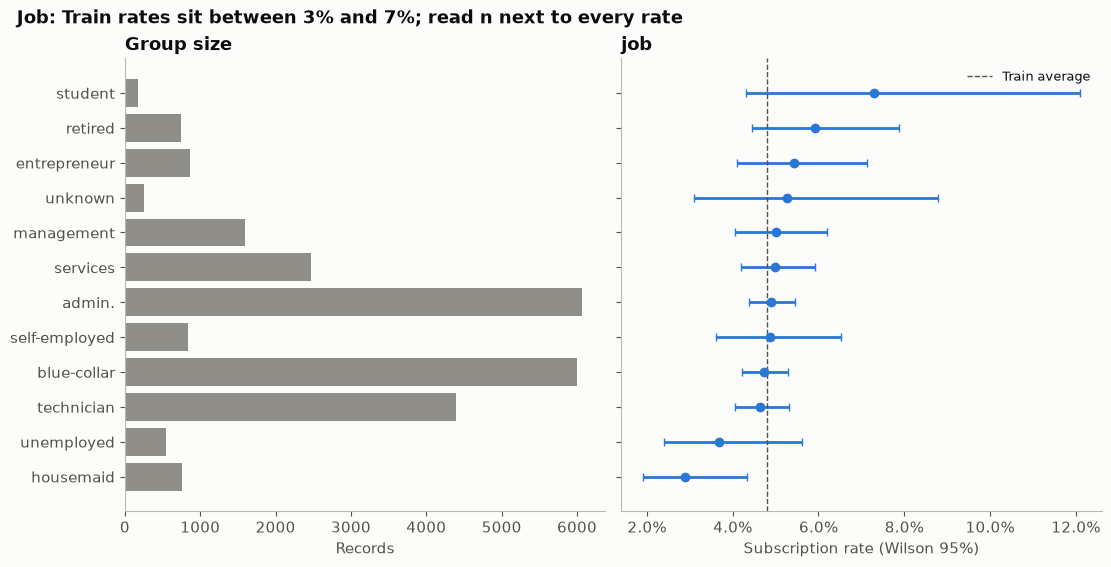

,n,yes,rate,lo,hi
job,,,,,
housemaid,764,22,0.028796,0.019092,0.043215
unemployed,544,20,0.036765,0.023923,0.056103
technician,4392,204,0.046448,0.040610,0.053079
blue-collar,6006,284,0.047286,0.042201,0.052949
self-employed,843,41,0.048636,0.036051,0.065315
admin.,6072,297,0.048913,0.043767,0.054629
services,2464,123,0.049919,0.041999,0.059240
management,1594,80,0.050188,0.040510,0.062030
unknown,247,13,0.052632,0.031013,0.087953


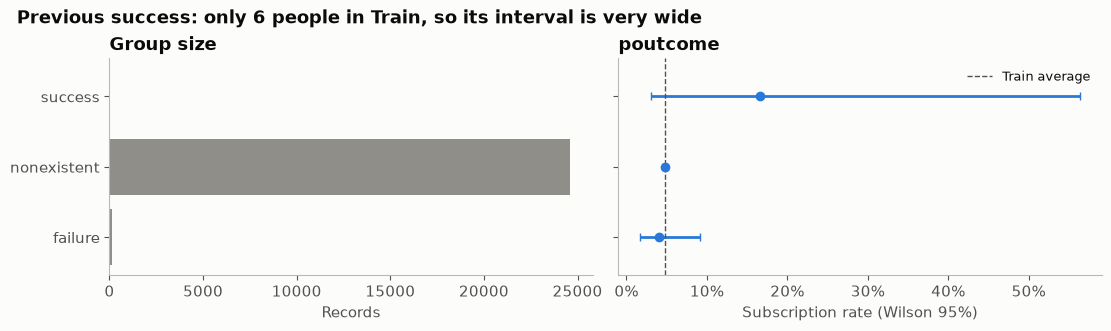

,n,yes,rate,lo,hi
poutcome,,,,,
failure,124,5,0.040323,0.017344,0.090927
nonexistent,24582,1182,0.048084,0.045479,0.050830
success,6,1,0.166667,0.030053,0.563509


In [12]:
# Data quality on Train, then job and previous outcome with the same helper as the rest of chapter 2
quality = pd.DataFrame({'nulls': eda_df.isna().sum(), 'unique': eda_df.nunique(),
    'unknown': [int(eda_df[c].eq('unknown').sum()) for c in eda_df]})
quality['unknown_pct'] = quality.unknown/len(eda_df)*100
display(quality)
quality.to_csv(MODEL_OUT/'train_data_quality.csv')
print('Previously contacted in Train:', int(eda_df.pdays.ne(999).sum()))
for col in ['marital', 'default']:
    group_stats(col)                                   # tables only (EDA_OUT/<col>_rates.csv)
job_g = plot_groups('job', '02_eda_job',
                    title=f'Job: Train rates sit between {group_stats("job").rate.min():.0%} and {group_stats("job").rate.max():.0%}; read n next to every rate')
display(job_g)
n_success = int(eda_df.poutcome.eq('success').sum())
pout_g = plot_groups('poutcome', '02_eda_poutcome',
                     title=f'Previous success: only {n_success} people in Train, so its interval is very wide')
display(pout_g)

ต่อด้วยกลุ่มอื่นจาก EDA เดิม: อายุ การศึกษา สินเชื่อบ้าน สินเชื่อส่วนบุคคล และประวัติการติดต่อ

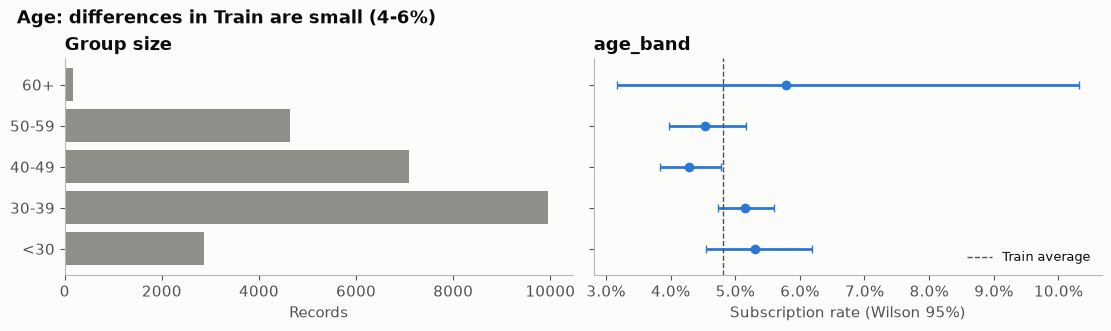

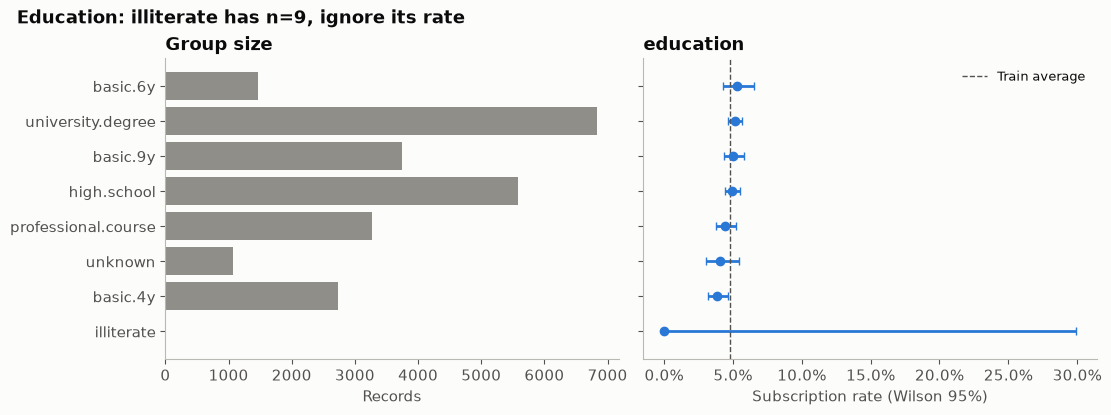

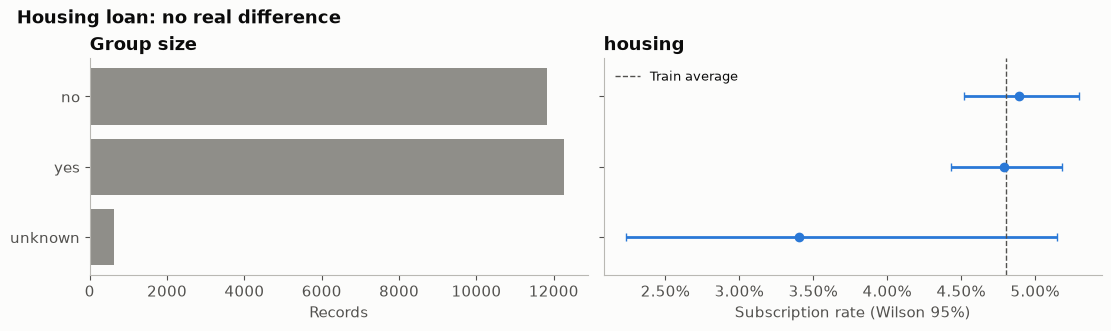

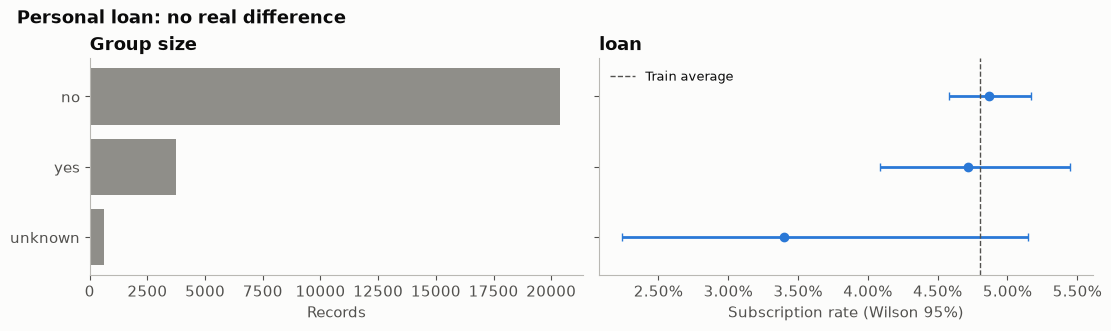

,n,yes,rate,lo,hi
loan,,,,,
unknown,617,21,0.034036,0.022367,0.051471
yes,3728,176,0.047210,0.040856,0.054497
no,20367,991,0.048657,0.045786,0.051698


In [13]:
# Subscription rate by customer group (Train, Wilson 95%)
eda_df['age_band'] = pd.cut(eda_df.age, [0, 29, 39, 49, 59, 200], labels=['<30', '30-39', '40-49', '50-59', '60+'])
age_rates = plot_groups('age_band', 'e03_age_rates', sort=False, title='Age: differences in Train are small (4-6%)')
edu_rates = plot_groups('education', 'e04_education_rates', title='Education: illiterate has n=9, ignore its rate')
plot_groups('housing', 'e05_housing_rates', title='Housing loan: no real difference')
plot_groups('loan', 'e06_loan_rates', title='Personal loan: no real difference')

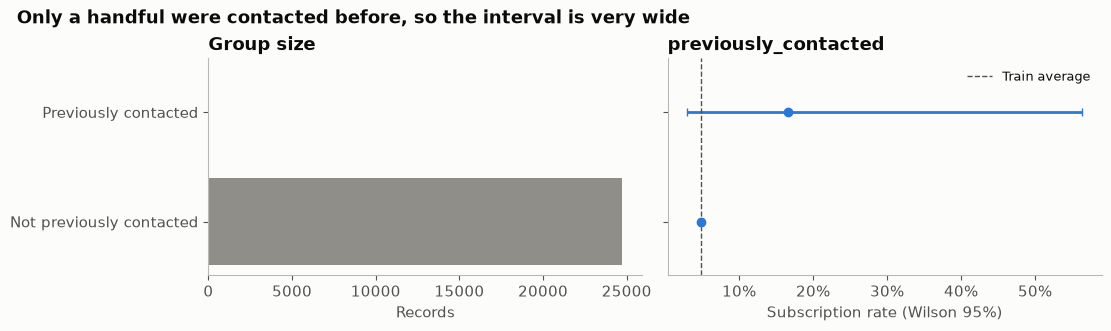

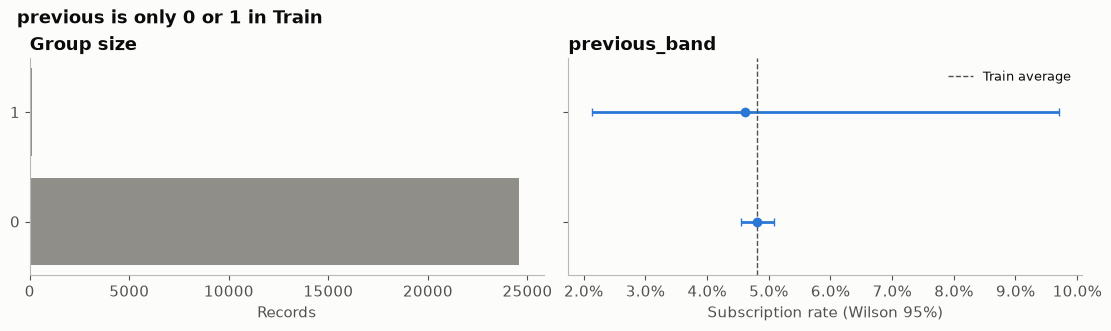

1) Train: 24,712 records, 1,188 subscribed (4.81%)
2) Best job with n>=100: student at 7.30% (n=178)
3) pdays=999 (never contacted): 99.98% of Train
4) Group differences are small in Train; campaign history barely exists yet -> the model can only learn it from later data


In [14]:
# Previous-campaign history (Train): the strongest signal later is almost absent here
eda_df['previously_contacted'] = np.where(eda_df.pdays.ne(999), 'Previously contacted', 'Not previously contacted')
eda_df['previous_band'] = pd.cut(eda_df.previous, [-1, 0, 1, 2, np.inf], labels=['0', '1', '2', '3+'])
plot_groups('previously_contacted', 'e07_previous_contact', title='Only a handful were contacted before, so the interval is very wide')
plot_groups('previous_band', 'e08_previous_count', sort=False, title='previous is only 0 or 1 in Train')
job_all = group_stats('job'); top_job = job_all[job_all.n.ge(100)].sort_values('rate', ascending=False)
print(f'1) Train: {len(eda_df):,} records, {eda_df.subscribed.sum():,} subscribed ({eda_base:.2%})')
print(f'2) Best job with n>=100: {top_job.index[0]} at {top_job.rate.iloc[0]:.2%} (n={int(top_job.n.iloc[0]):,})')
print(f'3) pdays=999 (never contacted): {eda_df.pdays.eq(999).mean():.2%} of Train')
print('4) Group differences are small in Train; campaign history barely exists yet -> the model can only learn it from later data')

## 2.4 ข้อมูลหาย (`unknown`) และค่าผิดปกติ

> 🔧 **เทคนิค:** ตรวจ missing (`unknown`) และ outlier ด้วย Boxplot + IQR fence (W1)  
> 🎯 **ทำไม:** รู้คุณภาพข้อมูลก่อนสร้างโมเดล และตัดสินใจว่าจะเก็บหรือตัด outlier  
> 🗣️ **พูดว่า:** “ข้อมูลหายซ่อนอยู่ในคำว่า unknown โดยเฉพาะ default ที่ไม่ทราบเกือบ 28% และลูกค้าสูงอายุเพิ่งโผล่มาในช่วงหลัง”

ไฟล์ไม่มีช่องว่าง แต่มี `unknown` แทน (`default` ไม่ทราบเกือบ 28% หรือมากกว่า 1 ใน 4) จึงเก็บไว้เป็นกลุ่มหนึ่ง ส่วนอายุ Train ไม่มี outlier เลย (สูงสุด 61 ปี) แต่ช่วงหลังมีลูกค้าอายุเกินเส้น IQR fence ที่ตั้งจาก Train เราไม่ตัดทิ้ง เพราะ outlier อาจเป็นลูกค้าที่มีค่าที่สุด (W1)

Train age IQR fence: [12.0, 68.0]


,share_outside_train_fence
Train,0.000000
Validation,0.009347
Test,0.051712


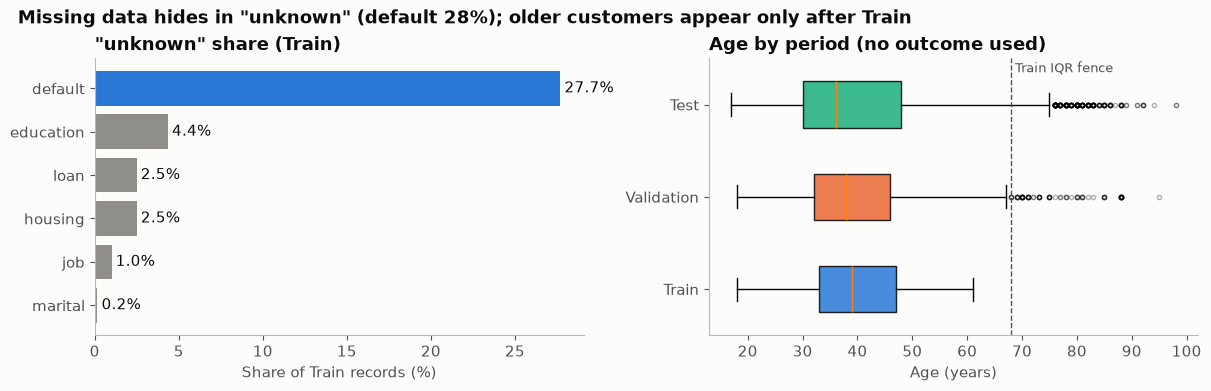

In [15]:
# Unknown shares and age outliers on Train only
unk = quality.loc[quality.unknown.gt(0), 'unknown_pct'].sort_values()
age_q1, age_q3 = eda_df.age.quantile([.25, .75]); iqr = age_q3 - age_q1
upper, lower = age_q3 + 1.5*iqr, age_q1 - 1.5*iqr
ages = {s: raw.age[split_name.eq(s).to_numpy()] for s in ['Train', 'Validation', 'Test']}
outside = pd.Series({s: float((a.gt(upper) | a.lt(lower)).mean()) for s, a in ages.items()}, name='share_outside_train_fence')
print(f'Train age IQR fence: [{lower:.1f}, {upper:.1f}]'); display(outside.to_frame())
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), layout='constrained')
axs[0].barh(unk.index, unk, color=[HL if v > 20 else GREY for v in unk])
axs[0].bar_label(axs[0].containers[0], fmt='%.1f%%', padding=3)
axs[0].set(title='"unknown" share (Train)', xlabel='Share of Train records (%)')
bp = axs[1].boxplot(list(ages.values()), orientation='horizontal', tick_labels=list(ages),
                    patch_artist=True, widths=.5, flierprops=dict(marker='o', ms=3, alpha=.3))
for patch, c in zip(bp['boxes'], PERIOD_COLORS.values()): patch.set_facecolor(c); patch.set_alpha(.85)
axs[1].axvline(upper, color=WARN, ls='--', lw=1); axs[1].text(upper, 3.35, ' Train IQR fence', color=WARN, fontsize=9)
axs[1].set(title='Age by period (no outcome used)', xlabel='Age (years)')
fig.suptitle(f'Missing data hides in "unknown" (default {unk["default"]:.0f}%); older customers appear only after Train',
             fontweight='bold', x=.01, ha='left')
fig.savefig(MODEL_OUT/'02b_unknown_outliers.png', dpi=160); plt.show()

## 2.5 แบ่งกลุ่มลูกค้าด้วย K-means (W4)

> 🔧 **เทคนิค:** Z-score → K-means, เลือก K ด้วย elbow/silhouette, profiling (W4)  
> 🎯 **ทำไม:** แบ่งลูกค้าเป็นกลุ่มตามธรรมชาติ เพื่อนำไปทำ STP/4Ps ใน 6.1  
> 🗣️ **พูดว่า:** “K-means แบ่งลูกค้าได้ 4 กลุ่มที่ตีความได้ แต่ช่วงเวลามีผลกับอัตราสมัครมากกว่ากลุ่ม เราจึงใช้กลุ่มเพื่อออกแบบข้อความ”

ทำตามขั้นตอนในห้อง: เลือกตัวแปร 7 ตัวที่มีความหมายเชิงธุรกิจ → ปรับเป็น **Z-score** (อายุกับตัวแปร 0/1 มีหน่วยต่างกัน) → ดู elbow/silhouette → ใช้ **K = 4** → profile ด้วยตัวแปรที่ไม่ได้ใช้สร้างกลุ่ม ชื่อกลุ่มตั้งจาก cluster center ตามกฎในโค้ด

**สิ่งที่ได้:** ตีความกลุ่มได้ แต่กลุ่มซ้อนกัน (silhouette ต่ำ) และ **ช่วงเวลามีผลกับอัตราสมัครมากกว่ากลุ่ม** จึงใช้กลุ่มเพื่อออกแบบข้อความ (6.1) ไม่ใช้จัดลำดับการโทร

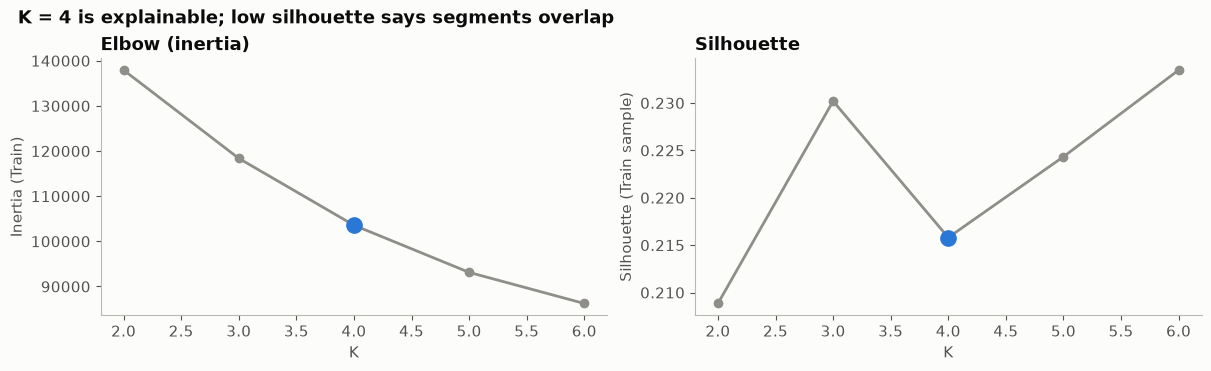

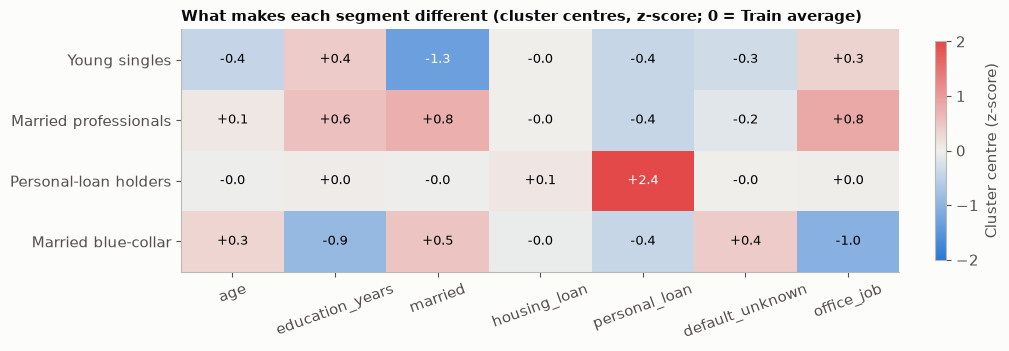

,records,previously_contacted,age,education_years,married,office_job,personal_loan,share,rate_Train,rate_Validation,rate_Test
segment,,,,,,,,,,,
Young singles,12178,0.046,36.148,13.220,0.000,0.720,0.0,0.296,0.051,0.141,0.306
Married professionals,10905,0.037,40.981,13.674,1.000,0.971,0.0,0.265,0.048,0.101,0.346
Personal-loan holders,6245,0.037,39.972,11.690,0.631,0.567,1.0,0.152,0.047,0.114,0.293
Married blue-collar,11860,0.027,43.064,8.080,0.873,0.039,0.0,0.288,0.046,0.085,0.284


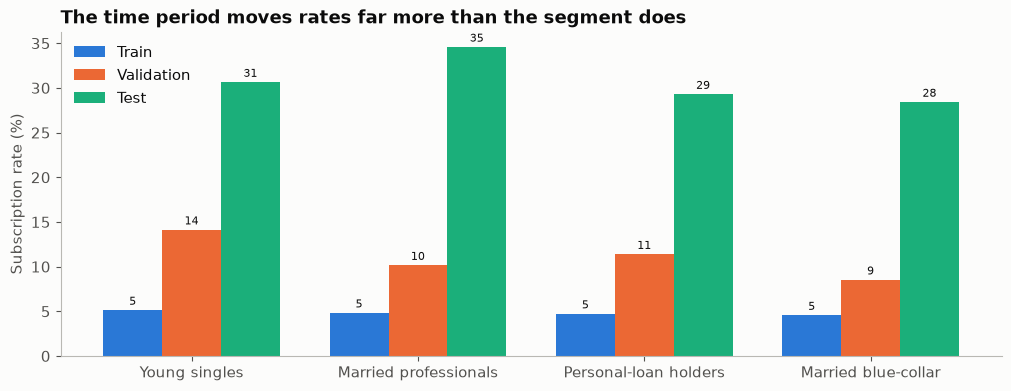

In [16]:
# W4: z-score -> K-means on Train; profile with outcome afterwards
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
EDU_YEARS = {'illiterate': 0, 'basic.4y': 4, 'basic.6y': 6, 'basic.9y': 9, 'high.school': 12,
             'professional.course': 13, 'university.degree': 16}
seg_X = pd.DataFrame({
    'age': raw.age,
    'education_years': raw.education.map(EDU_YEARS),
    'married': raw.marital.eq('married').astype(int),
    'housing_loan': raw.housing.eq('yes').astype(int),
    'personal_loan': raw.loan.eq('yes').astype(int),
    'default_unknown': raw.default.eq('unknown').astype(int),
    'office_job': raw.job.isin(['admin.', 'management', 'technician', 'entrepreneur', 'self-employed']).astype(int)})
seg_X['education_years'] = seg_X.education_years.fillna(seg_X.education_years.iloc[train].median())
seg_scaler = StandardScaler().fit(seg_X.iloc[train]); seg_Z = seg_scaler.transform(seg_X)

elbow = []
for k in range(2, 7):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(seg_Z[train])
    elbow.append(dict(k=k, inertia=km_k.inertia_,
                      silhouette=silhouette_score(seg_Z[train][::5], km_k.labels_[::5], random_state=SEED)))
elbow = pd.DataFrame(elbow); elbow.to_csv(MODEL_OUT/'kmeans_elbow.csv', index=False)

K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(seg_Z[train])
segment_id = kmeans.predict(seg_Z)
centers = pd.DataFrame(kmeans.cluster_centers_, columns=seg_X.columns)          # z-units
centers_raw = pd.DataFrame(seg_scaler.inverse_transform(kmeans.cluster_centers_), columns=seg_X.columns)

# Rule-based names from the centres, so labels survive cluster-number permutations
names = {}
loan_seg = int(centers_raw.personal_loan.idxmax()); names[loan_seg] = 'Personal-loan holders'
rest = [s for s in range(K) if s not in names]
single_seg = min(rest, key=lambda s: centers_raw.married[s]); names[single_seg] = 'Young singles'
rest.remove(single_seg)
office_seg = max(rest, key=lambda s: centers_raw.office_job[s]); names[office_seg] = 'Married professionals'
rest.remove(office_seg); names[rest[0]] = 'Married blue-collar'
segment = pd.Series(segment_id, index=raw.index).map(names)
SEG_ORDER = ['Young singles', 'Married professionals', 'Personal-loan holders', 'Married blue-collar']

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), layout='constrained')
axs[0].plot(elbow.k, elbow.inertia, marker='o', color=GREY); axs[0].plot(K, elbow.set_index('k').inertia[K], 'o', ms=11, color=HL)
axs[0].set(title='Elbow (inertia)', xlabel='K', ylabel='Inertia (Train)')
axs[1].plot(elbow.k, elbow.silhouette, marker='o', color=GREY); axs[1].plot(K, elbow.set_index('k').silhouette[K], 'o', ms=11, color=HL)
axs[1].set(title='Silhouette', xlabel='K', ylabel='Silhouette (Train sample)')
fig.suptitle('K = 4 is explainable; low silhouette says segments overlap', fontweight='bold', x=.01, ha='left')
fig.savefig(MODEL_OUT/'02c_kmeans_elbow.png', dpi=160); plt.show()

heat = centers.rename(index=names).loc[SEG_ORDER]
fig, ax = plt.subplots(figsize=(10, 3.4), layout='constrained')
im = ax.imshow(heat.to_numpy(), cmap=DIVERGING, vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(heat.shape[1]), heat.columns, rotation=20); ax.set_yticks(range(K), heat.index)
for i in range(K):
    for j in range(heat.shape[1]):
        ax.text(j, i, f'{heat.iloc[i, j]:+.1f}', ha='center', va='center', fontsize=9,
                color='white' if abs(heat.iloc[i, j]) > 1.2 else 'black')
fig.colorbar(im, ax=ax, label='Cluster centre (z-score)', shrink=.9)
ax.set_title('What makes each segment different (cluster centres, z-score; 0 = Train average)', fontsize=11)
fig.savefig(MODEL_OUT/'02c_kmeans_centres.png', dpi=160); plt.show()

seg_frame = pd.DataFrame({'segment': segment, 'split': split_name.to_numpy(), 'subscribed': y.to_numpy(),
                          'previously_contacted': raw.pdays.ne(999).astype(int).to_numpy()})
profile = (seg_frame.groupby('segment').agg(records=('subscribed', 'size'), previously_contacted=('previously_contacted', 'mean'))
           .join(centers_raw.rename(index=names)[['age', 'education_years', 'married', 'office_job', 'personal_loan']]))
profile['share'] = profile.records/len(seg_frame)
rates = seg_frame.pivot_table(index='segment', columns='split', values='subscribed', aggfunc='mean')[['Train', 'Validation', 'Test']]
profile = profile.join(rates.add_prefix('rate_')).loc[SEG_ORDER]
display(profile.round(3)); profile.to_csv(MODEL_OUT/'kmeans_segment_profile.csv')

fig, ax = plt.subplots(figsize=(10, 3.8), layout='constrained')
w = .26
for j, (sp, c) in enumerate(PERIOD_COLORS.items()):
    b = ax.bar(np.arange(K) + (j-1)*w, rates.loc[SEG_ORDER, sp]*100, w, color=c, label=sp)
    ax.bar_label(b, fmt='%.0f', padding=2, fontsize=8)
ax.set_xticks(range(K), SEG_ORDER); ax.set_ylabel('Subscription rate (%)'); ax.legend(frameon=False)
ax.set_title('The time period moves rates far more than the segment does')
fig.savefig(MODEL_OUT/'02c_kmeans_rates.png', dpi=160); plt.show()

# บทที่ 3 โมเดล: ข้อมูลก่อนโทรเรียงรายชื่อได้ดีแค่ไหน

**คำถามของบท:** โมเดลดีกว่าการสุ่มและกฎง่าย ๆ แค่ไหน พึ่งข้อมูลอะไร และผลเสถียรไหมเมื่อเปลี่ยนช่วงเวลาหรือวิธีแบ่ง

## 3.1 กติกาการวัดผล

> 🔧 **เทคนิค:** จัดอันดับทีละรอบ 500 ราย + วัด Precision / Recall / Lift เทียบการสุ่มและกฎง่าย ๆ  
> 🎯 **ทำไม:** วัดสิ่งที่ธุรกิจสนใจ (เลือกจำนวนเท่ากันแล้วเจอผู้สมัครกี่ราย) และมีคู่เทียบที่ยุติธรรม  
> 🗣️ **พูดว่า:** “เราเทียบโมเดลกับสองคู่แข่ง คือการสุ่ม และกฎง่าย ๆ ว่าโทรหาคนที่เคยตอบรับก่อน ในจำนวนรายชื่อที่เท่ากัน”

เรียงคะแนนจากสูงไปต่ำในรอบละ 500 รายชื่อ แล้วเลือกตามสัดส่วนที่ต้องการ วัดผลด้วย **Precision** (ในรายชื่อที่เลือกมีผู้สมัครกี่เปอร์เซ็นต์), **Recall** (เก็บผู้สมัครได้กี่เปอร์เซ็นต์ของทั้งหมด) และ **Lift** (ดีกว่าการสุ่มกี่เท่า) คู่เทียบคือ **การสุ่ม** และ **กฎง่าย ๆ "โทรหาคนที่เคยตอบรับแคมเปญก่อน"**

In [17]:
def ranked_batches(scores, batch_size=BATCH_SIZE):
    scores=np.asarray(scores,dtype=float)
    assert len(scores)>0 and np.isfinite(scores).all()
    rng=np.random.default_rng(SEED)
    return [np.arange(start,min(start+batch_size,len(scores)))[
        np.lexsort((rng.permutation(min(batch_size,len(scores)-start)),
                    -scores[start:start+batch_size]))]
        for start in range(0,len(scores),batch_size)]

def select_top_fraction(scores, fraction, batch_size=BATCH_SIZE):
    if not 0<=fraction<=1: raise ValueError('fraction must be in [0,1]')
    chosen=np.zeros(len(scores),dtype=bool)
    for order in ranked_batches(scores,batch_size):
        chosen[order[:int(np.floor(fraction*len(order)+1e-9))]]=True
    return chosen

def capacity_curve(target,scores,batch_size=BATCH_SIZE):
    yy=np.asarray(target,dtype=int); scores=np.asarray(scores)
    assert len(yy)==len(scores)
    batches=ranked_batches(scores,batch_size)
    prefixes=[np.r_[0,np.cumsum(yy[o])] for o in batches]
    rows=[];total=int(yy.sum())
    for q in FRACTIONS:
        ks=[int(np.floor(q*len(o)+1e-9)) for o in batches]
        selected=sum(ks)
        found=int(sum(cs[k] for cs,k in zip(prefixes,ks)))
        expected=float(sum(k*yy[o].mean() for o,k in zip(batches,ks)))
        rows.append(dict(fraction=float(q),selected=selected,found=found,
            positive_total=total,precision=found/selected if selected else np.nan,
            recall=found/total if total else np.nan,random_expected=expected,
            lift=found/expected if expected else np.nan))
    return pd.DataFrame(rows)

def history_rule(frame):
    # Predeclared simple rule; ties randomized, no Test outcome used.
    return frame.poutcome.map({'success':2.,'failure':1.,'nonexistent':0.}).fillna(0.).to_numpy()

tiny=capacity_curve([1,0,1,0],[.9,.8,.7,.1],batch_size=3)
assert tiny.iloc[0].selected==0 and tiny.iloc[0].found==0
assert tiny.iloc[-1].selected==4 and tiny.iloc[-1].found==2
assert np.all(np.diff(tiny.found)>=0)
print('Policy boundary checks passed')


Policy boundary checks passed


## 3.2 เลือกโมเดลจาก Validation

> 🔧 **เทคนิค:** Classification (Logistic Regression / Random Forest / Gradient Boosting) เลือกด้วย Average Precision บน Validation  
> 🎯 **ทำไม:** AP เหมาะกับข้อมูลที่ผู้สมัครมีน้อย (imbalanced) และวัดคุณภาพการเรียงลำดับ โดยไม่ผูกกับต้นทุน  
> 🗣️ **พูดว่า:** “จาก 8 แบบที่ลอง Logistic Regression ชนะบน Validation ด้วย AP 0.17 เทียบกับ 0.11 ของการสุ่ม และเราเลือกก่อนคิดเรื่องเงิน”

ลอง 8 แบบ (Logistic Regression ×3, Random Forest ×3, Gradient Boosting ×2) ฝึกบน Train แล้วเลือกด้วย **Average Precision (AP) บน Validation** เพราะเราสนใจว่าผู้สมัครถูกดันขึ้นมาอยู่ต้นรายชื่อหรือเปล่า และเลือกโมเดลก่อนคิดเรื่องเงิน

In [18]:
def make_model(kind,parameter,cat=None,num=None):
    prep=ColumnTransformer([
        ('categorical',OneHotEncoder(handle_unknown='ignore',sparse_output=False),CAT if cat is None else cat),
        ('numeric',StandardScaler(),NUM if num is None else num)])
    if kind=='Logistic regression':
        est=LogisticRegression(C=parameter,max_iter=1500,random_state=SEED)
    elif kind=='Gradient boosting':
        depth,rate=parameter
        est=HistGradientBoostingClassifier(max_depth=depth,learning_rate=rate,max_iter=200,random_state=SEED)
    else:
        depth,leaf=parameter
        est=RandomForestClassifier(n_estimators=180,max_depth=depth,
            min_samples_leaf=leaf,max_features=.8,random_state=SEED,n_jobs=-1)
    return Pipeline([('preprocess',prep),('model',est)])

specs=[('Logistic regression',c) for c in [.1,1.,10.]]
specs += [('Random forest',p) for p in [(8,20),(12,10),(None,20)]]
specs += [('Gradient boosting',p) for p in [(3,.05),(6,.05)]]
fitted={};spec_by_id={};val_scores={};validation_curves={};metric_rows=[]
for kind,param in specs:
    name=f'{kind} {param}'
    model=make_model(kind,param).fit(X.iloc[train],y.iloc[train])
    score=model.predict_proba(X.iloc[valid])[:,1]
    fitted[name]=model;spec_by_id[name]=(kind,param);val_scores[name]=score
    validation_curves[name]=capacity_curve(y.iloc[valid],score)
    metric_rows.append(dict(model=name,ap=average_precision_score(y.iloc[valid],score),
        auc=roc_auc_score(y.iloc[valid],score)))
    print('Fitted:',name)
val_scores['History rule']=history_rule(raw.iloc[valid])
validation_curves['History rule']=capacity_curve(y.iloc[valid],val_scores['History rule'])
random_curve=validation_curves['History rule'].copy()
random_curve['found']=random_curve.random_expected
random_curve['precision']=random_curve.found/random_curve.selected.replace(0,np.nan)
random_curve['recall']=random_curve.found/random_curve.positive_total
random_curve['lift']=np.where(random_curve.selected>0,1.,np.nan)
validation_curves['Random expected']=random_curve
validation_metrics=pd.DataFrame(metric_rows)
display(validation_metrics)
validation_metrics.to_csv(MODEL_OUT/'validation_model_metrics.csv',index=False)

validation_metrics['family']=[spec_by_id[m][0] for m in validation_metrics.model]
ordered=validation_metrics.sort_values(['ap','auc','model'],ascending=[False,False,True],kind='stable')
core_model=str(ordered.iloc[0].model)
family_models=ordered.drop_duplicates('family').model.tolist()
assert core_model in family_models
model_lock={'selection_metric':'Validation average precision; tie: ROC AUC then name',
            'core_model':core_model,'family_models':family_models,
            'cost_used_for_model_selection':False}
(MODEL_OUT/'model_selection.json').write_text(json.dumps(model_lock,indent=2),encoding='utf-8')
display(ordered)
print('Core model locked BEFORE business assumptions:',core_model)


Fitted: Logistic regression 0.1
Fitted: Logistic regression 1.0
Fitted: Logistic regression 10.0


Fitted: Random forest (8, 20)


Fitted: Random forest (12, 10)


Fitted: Random forest (None, 20)
Fitted: Gradient boosting (3, 0.05)
Fitted: Gradient boosting (6, 0.05)


,model,ap,auc
0,Logistic regression 0.1,0.158836,0.588272
1,Logistic regression 1.0,0.173964,0.596978
2,Logistic regression 10.0,0.174279,0.597709
3,"Random forest (8, 20)",0.135630,0.566832
4,"Random forest (12, 10)",0.121774,0.533209
5,"Random forest (None, 20)",0.122474,0.547828
6,"Gradient boosting (3, 0.05)",0.140283,0.604427
7,"Gradient boosting (6, 0.05)",0.140289,0.566888


,model,ap,auc,family
2,Logistic regression 10.0,0.174279,0.597709,Logistic regression
1,Logistic regression 1.0,0.173964,0.596978,Logistic regression
0,Logistic regression 0.1,0.158836,0.588272,Logistic regression
7,"Gradient boosting (6, 0.05)",0.140289,0.566888,Gradient boosting
6,"Gradient boosting (3, 0.05)",0.140283,0.604427,Gradient boosting
3,"Random forest (8, 20)",0.135630,0.566832,Random forest
5,"Random forest (None, 20)",0.122474,0.547828,Random forest
4,"Random forest (12, 10)",0.121774,0.533209,Random forest


Core model locked BEFORE business assumptions: Logistic regression 10.0


## 3.3 ทดสอบบน Test (ยังไม่คิดเงิน)

> 🔧 **เทคนิค:** Hold-out test: ฝึกใหม่ด้วย Train + Val แล้ววัดบน Test ครั้งเดียว  
> 🎯 **ทำไม:** ประเมินผลกับข้อมูลที่ไม่ได้ใช้เลือกโมเดล  
> 🗣️ **พูดว่า:** “บน Test โมเดลได้ AP 0.53 เทียบกับ 0.31 ของการสุ่ม หรือดีกว่าสุ่มราว 1.7 เท่า”

ฝึกตัวแทนของแต่ละตระกูลใหม่ด้วย Train + Validation แล้ววัดผลบน Test โดยไม่เปลี่ยนผู้ชนะ จุดอ้างอิงของ AP แบบสุ่มคืออัตราสมัครของ Test

In [19]:
needed=family_models
final_models={};test_scores={};test_curves={}
for name in needed:
    model=make_model(*spec_by_id[name]).fit(X.iloc[:cut2],y.iloc[:cut2])
    final_models[name]=model
    test_scores[name]=model.predict_proba(X.iloc[test])[:,1]
for name in ['History rule']:
    test_scores[name]=history_rule(raw.iloc[test])
for name,score in test_scores.items():
    test_curves[name]=capacity_curve(y.iloc[test],score)
rc=test_curves['History rule'].copy()
rc['found']=rc.random_expected;rc['precision']=rc.found/rc.selected.replace(0,np.nan)
rc['recall']=rc.found/rc.positive_total;rc['lift']=np.where(rc.selected>0,1.,np.nan)
test_curves['Random expected']=rc

model_test_rows=[]
for name,score in test_scores.items():
    model_test_rows.append(dict(model=name,core_model=(name==core_model),
        ap=average_precision_score(y.iloc[test],score),
        auc=roc_auc_score(y.iloc[test],score)))
model_test_metrics=pd.DataFrame(model_test_rows)
model_test_metrics['test_prevalence']=float(y.iloc[test].mean())
model_test_metrics.to_csv(MODEL_OUT/'test_model_metrics.csv',index=False)
display(model_test_metrics)
capacity_rows=[]
for name,curve in test_curves.items():
    t=curve[curve.fraction.round(2).isin([.05,.10,.20,.30,.50,1.])].copy()
    t['model']=name;capacity_rows.append(t)
model_capacity=pd.concat(capacity_rows,ignore_index=True)
model_capacity.to_csv(MODEL_OUT/'test_capacity_comparison.csv',index=False)
display(model_capacity[['model','fraction','selected','found','precision','recall','lift']])
# Preserve reusable scores. Chapter 4 consumes these, never retrains or reselects a model.
score_export=pd.DataFrame({'source_row':np.arange(cut2+1,n+1),'target':y.iloc[test].to_numpy()})
for name,scores in test_scores.items():score_export[name]=scores
score_export.to_csv(MODEL_OUT/'test_model_scores.csv',index=False)


,model,core_model,ap,auc,test_prevalence
0,Logistic regression 10.0,True,0.529169,0.685418,0.308327
1,"Gradient boosting (6, 0.05)",False,0.484504,0.672688,0.308327
2,"Random forest (8, 20)",False,0.476973,0.673573,0.308327
3,History rule,False,0.448763,0.620747,0.308327


,model,fraction,selected,found,precision,recall,lift
0,Logistic regression 10.0,0.05,411,203.000000,0.493917,0.079921,1.604013
1,Logistic regression 10.0,0.10,823,393.000000,0.477521,0.154724,1.549643
2,Logistic regression 10.0,0.20,1647,739.000000,0.448695,0.290945,1.455570
3,Logistic regression 10.0,0.30,2471,1026.000000,0.415217,0.403937,1.346804
4,Logistic regression 10.0,0.50,4119,1493.000000,0.362467,0.587795,1.175591
5,Logistic regression 10.0,1.00,8238,2540.000000,0.308327,1.000000,1.000000
6,"Gradient boosting (6, 0.05)",0.05,411,180.000000,0.437956,0.070866,1.422278
7,"Gradient boosting (6, 0.05)",0.10,823,348.000000,0.422843,0.137008,1.372203
8,"Gradient boosting (6, 0.05)",0.20,1647,644.000000,0.391014,0.253543,1.268453
9,"Gradient boosting (6, 0.05)",0.30,2471,928.000000,0.375556,0.365354,1.218162


## 3.4 โมเดลดีกว่ากฎง่าย ๆ จริงไหม?

> 🔧 **เทคนิค:** Paired difference + bootstrap ระดับรอบ (2,000 ครั้ง)  
> 🎯 **ทำไม:** รู้ว่าโมเดลชนะกฎ "จริง" หรือเป็นแค่ noise  
> 🗣️ **พูดว่า:** “แต่ถ้าเทียบกับกฎง่าย ๆ ที่ 20% เท่ากัน โมเดลเจอเพิ่มแค่ 27 ราย และช่วงความไม่แน่นอนคร่อมศูนย์”

คำนวณส่วนต่าง (โมเดล − กฎ) ทีละรอบ 500 รายชื่อ แล้ว bootstrap 2,000 ครั้ง ถ้าช่วงคร่อม 0 แปลว่ายังบอกไม่ได้ว่าโมเดลดีกว่า

,fraction,selected,diff,lo,hi,batches_model_ahead,batches
0,0.05,411,0.0,-22.0,19.0,7,17
1,0.10,823,8.0,-16.0,31.0,9,17
2,0.20,1647,27.0,-5.0,58.0,13,17
3,0.30,2471,18.0,-11.0,50.0,10,17
4,0.50,4119,76.0,29.0,119.0,15,17


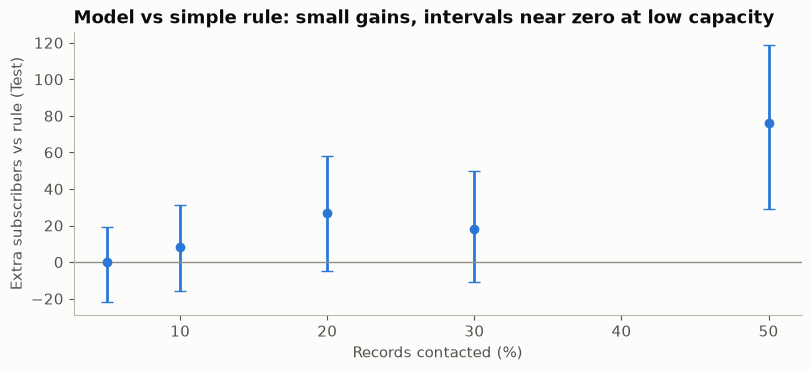

In [20]:
# Paired per-batch difference: model minus history rule, batch bootstrap
yt_arr = y.iloc[test].to_numpy()
ml_orders, rule_orders = ranked_batches(test_scores[core_model]), ranked_batches(test_scores['History rule'])
def found_per_batch(orders, q):
    return np.array([yt_arr[o[:int(np.floor(q*len(o)+1e-9))]].sum() for o in orders])
boot_rng = np.random.default_rng(SEED); gap_rows = []
for q in [.05, .10, .20, .30, .50]:
    d = found_per_batch(ml_orders, q) - found_per_batch(rule_orders, q)
    boots = [d[boot_rng.integers(0, len(d), len(d))].sum() for _ in range(2000)]
    lo, hi = np.quantile(boots, [.025, .975])
    gap_rows.append(dict(fraction=q, selected=int(sum(int(np.floor(q*len(o)+1e-9)) for o in ml_orders)),
                         diff=float(d.sum()), lo=float(lo), hi=float(hi), batches_model_ahead=int((d > 0).sum()),
                         batches=len(d)))
rule_gap = pd.DataFrame(gap_rows); display(rule_gap); rule_gap.to_csv(MODEL_OUT/'model_vs_rule_gap.csv', index=False)
g20 = rule_gap.loc[np.isclose(rule_gap.fraction, .20)].iloc[0]
fig, ax = plt.subplots(figsize=(8, 3.6), layout='constrained')
ax.errorbar(rule_gap.fraction*100, rule_gap['diff'], yerr=[rule_gap['diff']-rule_gap.lo, rule_gap.hi-rule_gap['diff']],
            fmt='o', color=HL, capsize=4, lw=2)
ax.axhline(0, color=GREY, lw=1)
ax.set(xlabel='Records contacted (%)', ylabel='Extra subscribers vs rule (Test)',
       title='Model vs simple rule: small gains, intervals near zero at low capacity')
fig.savefig(MODEL_OUT/'03b_model_vs_rule_gap.png', dpi=160); plt.show()

## 3.5 ภาพรวมการเรียงลำดับ

> 🔧 **เทคนิค:** Precision–Recall curve, Gains curve, อัตราสมัครรายช่วงคะแนน  
> 🎯 **ทำไม:** เห็นคุณภาพการเรียงลำดับทุกระดับการโทร ไม่ใช่จุดเดียว  
> 🗣️ **พูดว่า:** “เส้นของโมเดลอยู่เหนือการสุ่มตลอด แต่วิ่งเกือบทับเส้นของกฎง่าย ๆ”

Precision–Recall, Gains curve และอัตราสมัครของแต่ละช่วงคะแนน เทียบโมเดลกับกฎง่าย ๆ และการสุ่ม

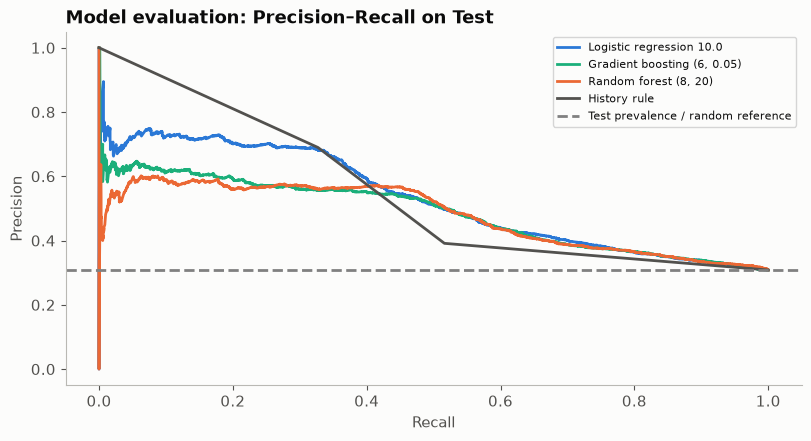

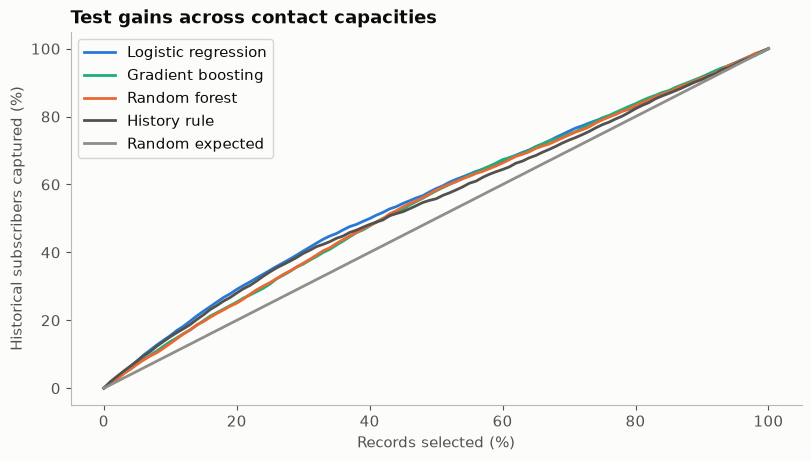

,split,band,records,found,rate
0,Validation,0-10%,823,149,0.181045
1,Validation,10-20%,824,116,0.140777
2,Validation,20-30%,824,103,0.125000
3,Validation,30-40%,824,84,0.101942
4,Validation,40-50%,824,79,0.095874
5,Validation,50-60%,823,96,0.116646
6,Validation,60-70%,824,70,0.084951
7,Validation,70-80%,824,68,0.082524
8,Validation,80-90%,824,82,0.099515
9,Validation,90-100%,824,65,0.078883


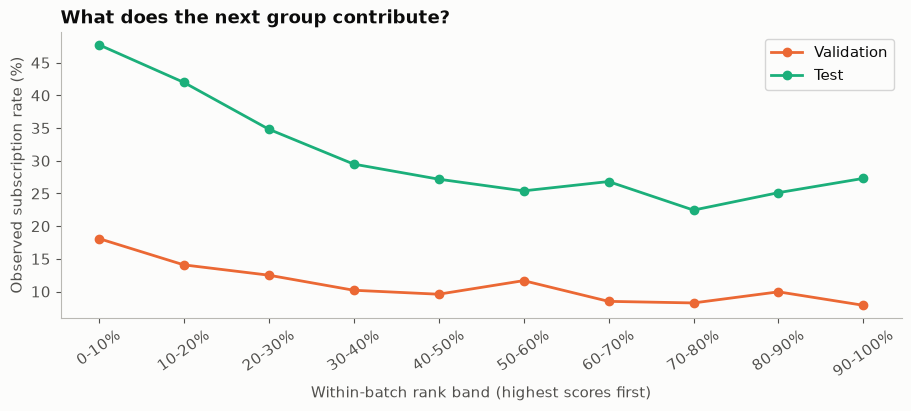

,model,target_recall,required_fraction
0,Logistic regression 10.0,0.3,0.21
1,Logistic regression 10.0,0.5,0.41
2,Logistic regression 10.0,0.7,0.62
3,History rule,0.3,0.35
4,History rule,0.5,0.54
5,History rule,0.7,0.72
6,Random expected,0.3,0.31
7,Random expected,0.5,0.50
8,Random expected,0.7,0.71


In [21]:
from sklearn.metrics import precision_recall_curve
colors={'Logistic regression':HL,'Random forest':'#eb6834','Gradient boosting':HL2,'History rule':INK2,'Random expected':GREY}
fig,ax=plt.subplots(figsize=(8,4.3),layout='constrained')
for name in family_models+['History rule']:
    precision,recall,_=precision_recall_curve(y.iloc[test],test_scores[name])
    ax.plot(recall,precision,label=name,color=colors[spec_by_id[name][0]] if name in spec_by_id else colors[name])
ax.axhline(y.iloc[test].mean(),ls='--',color='gray',label='Test prevalence / random reference')
ax.set(xlabel='Recall',ylabel='Precision',title='Model evaluation: Precision–Recall on Test')
ax.legend(fontsize=8);fig.savefig(MODEL_OUT/'03_precision_recall.png',dpi=160);plt.show()

fig,ax=plt.subplots(figsize=(8,4.5),layout='constrained')
for name,label in [(m,spec_by_id[m][0]) for m in family_models]+[('History rule','History rule'),('Random expected','Random expected')]:
    c=test_curves[name]
    ax.plot(c.fraction*100,c.recall*100,label=label,lw=2,color=colors[label])
ax.set(xlabel='Records selected (%)',ylabel='Historical subscribers captured (%)',title='Test gains across contact capacities')
ax.legend();fig.savefig(MODEL_OUT/'03_gains.png',dpi=160);plt.show()

decile_rows=[]
for split_name,target,score in [('Validation',y.iloc[valid],val_scores[core_model]),
                                 ('Test',y.iloc[test],test_scores[core_model])]:
    yy=np.asarray(target)
    for j in range(10):
        lo=select_top_fraction(score,j/10);hi=select_top_fraction(score,(j+1)/10)
        band=hi & ~lo
        decile_rows.append(dict(split=split_name,band=f'{j*10}-{(j+1)*10}%',
            records=int(band.sum()),found=int(yy[band].sum()),
            rate=float(yy[band].mean()) if band.any() else np.nan))
deciles=pd.DataFrame(decile_rows);display(deciles)
deciles.to_csv(MODEL_OUT/'marginal_score_bands.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
for split_name,group in deciles.groupby('split',sort=False):
    ax.plot(group.band,group.rate*100,marker='o',label=split_name,color=PERIOD_COLORS[split_name])
ax.set(xlabel='Within-batch rank band (highest scores first)',ylabel='Observed subscription rate (%)',
       title='What does the next group contribute?')
ax.tick_params(axis='x',rotation=35);ax.legend()
fig.savefig(MODEL_OUT/'04_marginal_bands.png',dpi=160);plt.show()

coverage=[]
for name in [core_model,'History rule','Random expected']:
    c=validation_curves[name]
    for target in [.3,.5,.7]:
        eligible=c[c.recall>=target]
        coverage.append(dict(model=name,target_recall=target,
            required_fraction=float(eligible.iloc[0].fraction) if len(eligible) else np.nan))
coverage=pd.DataFrame(coverage);display(coverage)
coverage.to_csv(MODEL_OUT/'validation_coverage_targets.csv',index=False)


## 3.6 โมเดลอาศัยข้อมูลอะไร?

> 🔧 **เทคนิค:** Grouped permutation importance  
> 🎯 **ทำไม:** แก้ปัญหาตัวแปรที่บอกเรื่องเดียวกันชดเชยกันเอง ทำให้อ่านผลผิด  
> 🗣️ **พูดว่า:** “เมื่อดูเป็นกลุ่ม ประวัติแคมเปญสำคัญที่สุด ตามด้วยข้อมูลส่วนตัวและอาชีพ ส่วนสถานะสินเชื่อแทบไม่ช่วย”

สลับค่า **ทั้งกลุ่มพร้อมกัน** (ใช้ลำดับสุ่มเดียวกันกับทุกคอลัมน์ในกลุ่ม) เพื่อไม่ให้ตัวแปรในกลุ่มเดียวกันชดเชยกันเอง

,group,importance,sd
2,Credit status,0.006088,0.001652
1,Demographics & job,0.023304,0.003868
0,Campaign history,0.038798,0.001560


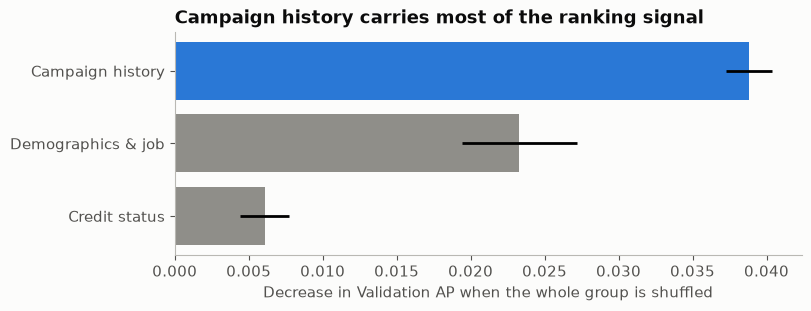

In [22]:
# Grouped permutation importance on Validation (shared permutation inside a group)
GROUPS = {'Campaign history': ['previous', 'poutcome', 'pdays_band'],
          'Demographics & job': ['age', 'job', 'marital', 'education'],
          'Credit status': ['default', 'housing', 'loan']}
assert sorted(sum(GROUPS.values(), [])) == sorted(X.columns)
Xv, yv_s = X.iloc[valid], y.iloc[valid]
ap_full = average_precision_score(yv_s, fitted[core_model].predict_proba(Xv)[:, 1])
g_rng = np.random.default_rng(SEED); g_rows = []
for gname, cols in GROUPS.items():
    drops = []
    for _ in range(5):
        Xp = Xv.copy(); perm = g_rng.permutation(len(Xp))
        Xp[cols] = Xv[cols].iloc[perm].set_axis(Xp.index)
        drops.append(ap_full - average_precision_score(yv_s, fitted[core_model].predict_proba(Xp)[:, 1]))
    g_rows.append(dict(group=gname, importance=np.mean(drops), sd=np.std(drops)))
group_imp = pd.DataFrame(g_rows).sort_values('importance'); display(group_imp)
group_imp.to_csv(MODEL_OUT/'validation_group_importance.csv', index=False)
fig, ax = plt.subplots(figsize=(8, 3), layout='constrained')
ax.barh(group_imp.group, group_imp.importance, xerr=group_imp.sd,
        color=[HL if g == group_imp.group.iloc[-1] else GREY for g in group_imp.group])
ax.axvline(0, color='gray', lw=.6)
ax.set(xlabel='Decrease in Validation AP when the whole group is shuffled',
       title=f'{group_imp.group.iloc[-1]} carries most of the ranking signal')
fig.savefig(MODEL_OUT/'07b_group_importance.png', dpi=160); plt.show()

## 3.7 ใช้ได้ในหลายช่วงเวลาไหม?

> 🔧 **เทคนิค:** Rolling-origin validation (ฝึกเพิ่มทีละช่วง 5 รอบ)  
> 🎯 **ทำไม:** ดูว่าโมเดลใช้ได้ข้ามช่วงเวลา ไม่ได้บังเอิญดีแค่ช่วงเดียว  
> 🗣️ **พูดว่า:** “เมื่อลองย้อนหลัง 5 ช่วง โมเดลช่วยชัดเจนแค่ 2 ช่วงหลัง ซึ่งเป็นช่วงที่เริ่มมีประวัติแคมเปญสะสม”

ฝึกด้วยข้อมูลเก่าแล้วทดสอบช่วงถัดไป 5 รอบ ภายในข้อมูล 80% แรก AP ต้องอ่านคู่กับอัตราสมัครของแต่ละรอบ

,fraction,selected,found,positive_total,precision,recall,random_expected,lift,train_end,evaluation_end,prevalence,ap,auc
0,0.1,411.0,29.0,273.0,0.070560,0.106227,27.262185,1.063745,0.3,0.4,0.066278,0.068663,0.518584
1,0.2,823.0,57.0,273.0,0.069259,0.208791,54.566387,1.044599,0.3,0.4,0.066278,0.068663,0.518584
2,0.3,1235.0,81.0,273.0,0.065587,0.296703,81.870588,0.989366,0.3,0.4,0.066278,0.068663,0.518584
3,0.5,2059.0,134.0,273.0,0.065080,0.490842,136.478992,0.981836,0.3,0.4,0.066278,0.068663,0.518584
4,0.1,411.0,28.0,257.0,0.068127,0.108949,25.556303,1.095620,0.4,0.5,0.062394,0.062164,0.500149
5,0.2,823.0,52.0,257.0,0.063183,0.202335,51.272269,1.014193,0.4,0.5,0.062394,0.062164,0.500149
6,0.3,1235.0,84.0,257.0,0.068016,0.326848,76.988235,1.091076,0.4,0.5,0.062394,0.062164,0.500149
7,0.5,2059.0,131.0,257.0,0.063623,0.509728,128.420168,1.020089,0.4,0.5,0.062394,0.062164,0.500149
8,0.1,411.0,18.0,225.0,0.043796,0.080000,22.472881,0.800965,0.5,0.6,0.054638,0.060929,0.507675
9,0.2,823.0,46.0,225.0,0.055893,0.204444,44.979661,1.022684,0.5,0.6,0.054638,0.060929,0.507675


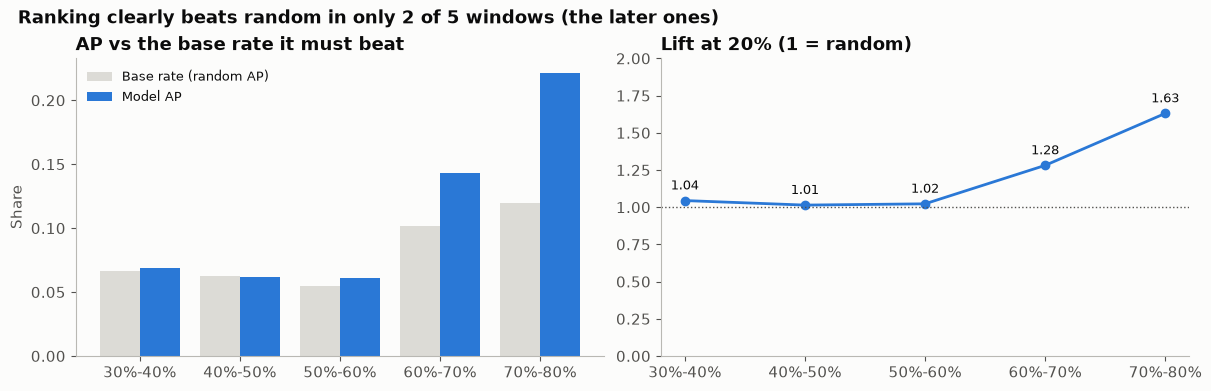

In [23]:
model_temporal_rows=[]
for train_end,eval_end in [(.3,.4),(.4,.5),(.5,.6),(.6,.7),(.7,.8)]:
    a,b=[int(n*f) for f in [train_end,eval_end]]
    model=make_model(*spec_by_id[core_model]).fit(X.iloc[:a],y.iloc[:a])
    score=model.predict_proba(X.iloc[a:b])[:,1]
    curve=capacity_curve(y.iloc[a:b],score)
    for q in [.1,.2,.3,.5]:
        r=curve.loc[np.isclose(curve.fraction,q)].iloc[0].to_dict()
        r.update(train_end=train_end,evaluation_end=eval_end,
            prevalence=float(y.iloc[a:b].mean()),
            ap=average_precision_score(y.iloc[a:b],score),auc=roc_auc_score(y.iloc[a:b],score))
        model_temporal_rows.append(r)
model_temporal=pd.DataFrame(model_temporal_rows)
model_temporal.to_csv(MODEL_OUT/'temporal_model_metrics.csv',index=False)
display(model_temporal)

# One picture of ranking quality over time (two panels, one axis each)
tm = model_temporal[np.isclose(model_temporal.fraction, .2)].reset_index(drop=True)
xs = np.arange(len(tm)); fold = [f'{a:.0%}-{b:.0%}' for a, b in zip(tm.train_end, tm.evaluation_end)]
n_help = int((tm.lift > 1.1).sum())
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8), layout='constrained')
a1.bar(xs - .2, tm.prevalence, .4, color=LIGHT, label='Base rate (random AP)')
a1.bar(xs + .2, tm.ap, .4, color=HL, label='Model AP')
a1.set_xticks(xs, fold); a1.set(title='AP vs the base rate it must beat', ylabel='Share'); a1.legend(frameon=False, fontsize=9)
a2.plot(xs, tm.lift, color=HL, marker='o'); a2.axhline(1, color=WARN, ls=':', lw=1)
for x, v in zip(xs, tm.lift): a2.annotate(f'{v:.2f}', (x, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
a2.set_xticks(xs, fold); a2.set(title='Lift at 20% (1 = random)', ylim=(0, 2))
fig.suptitle(f'Ranking clearly beats random in only {n_help} of {len(tm)} windows (the later ones)', fontweight='bold', x=.01, ha='left')
fig.savefig(MODEL_OUT/'06b_temporal_folds.png', dpi=160); plt.show()


## 3.8 ถ้าแบ่ง Train / Validation / Test ต่างไป ผลเปลี่ยนไหม?

> 🔧 **เทคนิค:** Split sensitivity: เทียบ 6 วิธีแบ่ง + เลือกโมเดลใหม่ทุกแบบ  
> 🎯 **ทำไม:** พิสูจน์ว่าการสุ่มแบ่งทำให้ผลดีเกินจริง (temporal leakage) และดูความเสถียรของผู้ชนะ  
> 🗣️ **พูดว่า:** “ถ้าสุ่มแบ่งข้อมูล ผลจะดูดีกว่าความจริงราว 2 เท่า เพราะโมเดลแอบเห็นอนาคต และเมื่อเปลี่ยนวิธีแบ่ง ผู้ชนะก็เปลี่ยน บางแบบแพ้กฎด้วย”

**ขั้นตอน:** (1) ตั้งคำถามว่าแบ่งแบบไหนถึงเหมือนการใช้งานจริง (2) ลอง 6 แบบ: ตามเวลา 3 สัดส่วน, ตามปฏิทิน 2 แบบ และ **สุ่ม** 1 แบบเป็นตัวอย่างที่ไม่ควรทำ (3) คุม feature และตัวเลือกโมเดลให้เหมือนเดิม (4) **เลือกโมเดลใหม่ในแต่ละแบบ** จาก 8 ตัวเลือก (5) เทียบด้วย AP ÷ อัตราสมัคร (ปรับฐานให้เทียบข้ามชุดได้) และ lift เทียบกฎง่าย ๆ

ใช้เวลารันราว 1–2 นาที

,scheme,train,validation,test,rate_train,rate_validation,rate_test,winner,same_winner,test_ap,test_auc,ap_over_base,lift20_model,lift20_rule
0,A time 60/20/20 (main),24712,8238,8238,0.048,0.111,0.308,Logistic regression 10.0,True,0.529,0.685,1.716,1.953,1.818
1,B time 70/15/15,28831,6178,6179,0.056,0.107,0.385,"Gradient boosting (3, 0.05)",False,0.518,0.637,1.346,1.455,1.767
2,C time 50/25/25,20594,10297,10297,0.047,0.099,0.258,"Gradient boosting (3, 0.05)",False,0.480,0.703,1.860,2.135,1.898
3,D calendar 2008 | 2009H1 | 2009H2-10,27690,9249,4249,0.048,0.147,0.458,Logistic regression 10.0,True,0.616,0.637,1.345,1.575,1.603
4,E calendar to May09 | Jun-Dec09 | 2010,36224,2906,2058,0.067,0.391,0.521,Logistic regression 10.0,True,0.676,0.647,1.297,1.479,1.447
5,F random stratified (ignores time),24712,8238,8238,0.113,0.113,0.113,"Gradient boosting (3, 0.05)",False,0.351,0.706,3.115,2.307,1.827


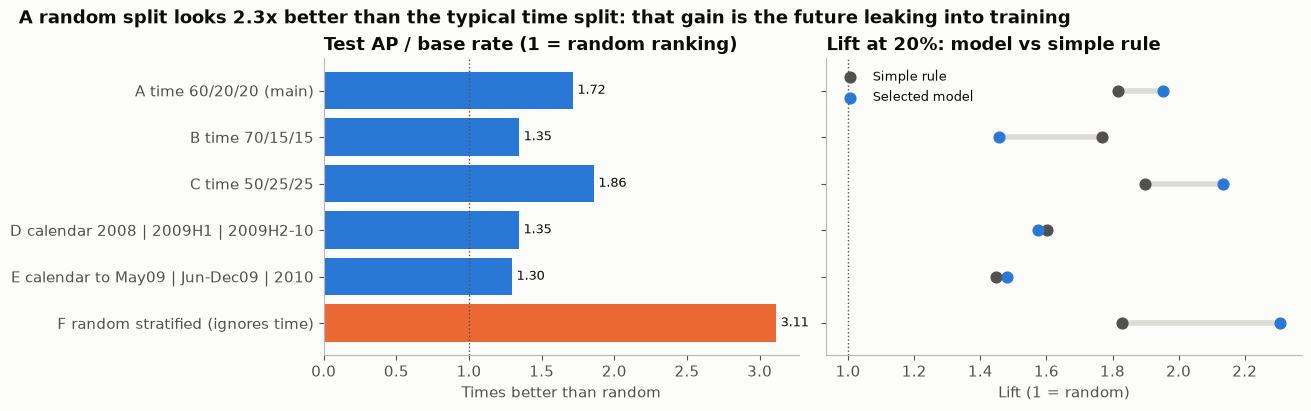

Winner differs from the main model in 3 of 6 schemes


In [24]:
# Same features and candidates, different ways of splitting the file
year_month_int = year_month.apply(lambda p: p.year*100 + p.month).to_numpy()
idx_all = np.arange(n)
def chrono(a, b): return idx_all[:int(n*a)], idx_all[int(n*a):int(n*b)], idx_all[int(n*b):]
from sklearn.model_selection import train_test_split
r_tr, r_te = train_test_split(idx_all, test_size=.2, stratify=y, random_state=SEED)
r_tr, r_va = train_test_split(r_tr, test_size=.25, stratify=y.iloc[r_tr], random_state=SEED)
SCHEMES = {
    'A time 60/20/20 (main)': chrono(.6, .8),
    'B time 70/15/15': chrono(.7, .85),
    'C time 50/25/25': chrono(.5, .75),
    'D calendar 2008 | 2009H1 | 2009H2-10': (idx_all[year_month_int < 200901],
        idx_all[(year_month_int >= 200901) & (year_month_int < 200907)], idx_all[year_month_int >= 200907]),
    'E calendar to May09 | Jun-Dec09 | 2010': (idx_all[year_month_int < 200906],
        idx_all[(year_month_int >= 200906) & (year_month_int < 201001)], idx_all[year_month_int >= 201001]),
    'F random stratified (ignores time)': (np.sort(r_tr), np.sort(r_va), np.sort(r_te)),
}
def top_lift(target, score, q=.2):
    t = np.asarray(target); k = int(len(t)*q); return t[np.argsort(-np.asarray(score))[:k]].mean()/t.mean()
split_rows = []
for sname, (tr_i, va_i, te_i) in SCHEMES.items():
    cand = []
    for kind, param in specs:                       # step 6: re-run model selection inside each scheme
        sv = make_model(kind, param).fit(X.iloc[tr_i], y.iloc[tr_i]).predict_proba(X.iloc[va_i])[:, 1]
        cand.append((average_precision_score(y.iloc[va_i], sv), roc_auc_score(y.iloc[va_i], sv), f'{kind} {param}', kind, param))
    cand.sort(key=lambda r: (-r[0], -r[1], r[2])); best = cand[0]
    both = np.r_[tr_i, va_i]
    st = make_model(best[3], best[4]).fit(X.iloc[both], y.iloc[both]).predict_proba(X.iloc[te_i])[:, 1]
    yt_s = y.iloc[te_i].to_numpy(); rule_s = history_rule(raw.iloc[te_i]) + np.random.default_rng(SEED).random(len(te_i))*1e-3
    split_rows.append(dict(scheme=sname, train=len(tr_i), validation=len(va_i), test=len(te_i),
        rate_train=y.iloc[tr_i].mean(), rate_validation=y.iloc[va_i].mean(), rate_test=yt_s.mean(),
        winner=best[2], same_winner=(best[2] == core_model), test_ap=average_precision_score(yt_s, st),
        test_auc=roc_auc_score(yt_s, st), ap_over_base=average_precision_score(yt_s, st)/yt_s.mean(),
        lift20_model=top_lift(yt_s, st), lift20_rule=top_lift(yt_s, rule_s)))
split_sens = pd.DataFrame(split_rows); split_sens.to_csv(MODEL_OUT/'split_sensitivity.csv', index=False)
display(split_sens.round(3))

is_random = split_sens.scheme.str.startswith('F')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4), layout='constrained', sharey=True)
ypos = np.arange(len(split_sens))[::-1]
a1.barh(ypos, split_sens.ap_over_base, color=['#eb6834' if r else HL for r in is_random])
for yv, v in zip(ypos, split_sens.ap_over_base): a1.text(v + .03, yv, f'{v:.2f}', va='center', fontsize=9)
a1.axvline(1, color=WARN, ls=':', lw=1); a1.set_yticks(ypos, split_sens.scheme)
a1.set(title='Test AP / base rate (1 = random ranking)', xlabel='Times better than random')
a2.scatter(split_sens.lift20_rule, ypos, color=INK2, s=60, label='Simple rule', zorder=3)
a2.scatter(split_sens.lift20_model, ypos, color=HL, s=60, label='Selected model', zorder=3)
for yv, a, b in zip(ypos, split_sens.lift20_rule, split_sens.lift20_model): a2.plot([a, b], [yv, yv], color=LIGHT, lw=4, zorder=1)
a2.axvline(1, color=WARN, ls=':', lw=1); a2.legend(frameon=False, fontsize=9, loc='upper left')
a2.set(title='Lift at 20%: model vs simple rule', xlabel='Lift (1 = random)')
gap = split_sens.loc[is_random, 'ap_over_base'].iloc[0] / split_sens.loc[~is_random, 'ap_over_base'].median()
fig.suptitle(f'A random split looks {gap:.1f}x better than the typical time split: that gain is the future leaking into training',
             fontweight='bold', x=.01, ha='left')
fig.savefig(MODEL_OUT/'06c_split_sensitivity.png', dpi=160); plt.show()
print('Winner differs from the main model in', int((~split_sens.same_winner).sum()), 'of', len(split_sens), 'schemes')

**อ่านผล:**
1. **การสุ่มทำให้โมเดลดูดีเกินจริง** (AP ÷ อัตราสมัคร ~3.1 เทียบกับ 1.3–1.9 ของแบบตามเวลา) เพราะได้เห็นข้อมูลอนาคตปนตอนฝึก ซึ่งในงานจริงทำไม่ได้
2. **ทุกแบบที่แบ่งตามเวลาเรียงได้ดีกว่าสุ่ม** (lift 1.5–2.1)
3. **ผู้ชนะไม่เสถียร**: เปลี่ยนจาก Logistic Regression เป็น Gradient Boosting ใน 3 จาก 6 แบบ เพราะสองตระกูลนี้ได้ AP ใกล้กันมาก
4. **ข้อได้เปรียบเหนือกฎง่าย ๆ ก็ไม่เสถียร**: ในแบบ B และ D โมเดล **แพ้** กฎ "เคยตอบรับก่อน" ที่ 20%

**สรุป:** ใช้แบบ A ต่อเพราะขนาดชุดสมดุลที่สุด แต่ข้อสรุปที่พูดได้อย่างมั่นใจมีแค่ "ข้อมูลก่อนโทรเรียงรายชื่อได้ดีกว่าสุ่ม" ส่วน "โมเดลดีกว่ากฎ" ขึ้นกับวิธีแบ่ง ข้อเสนอจึงเริ่มจากกฎง่าย ๆ แล้วใช้โมเดลช่วยเรียงส่วนที่เหลือ

## 3.9 สรุปบทโมเดล และแปลเป็นภาษาธุรกิจ

> 🔧 **เทคนิค:** สรุปผล Test ด้วย AP / AUC เทียบ base rate  
> 🎯 **ทำไม:** ปิดบทที่ 3 ด้วยคำตอบเรื่องคุณภาพโมเดลก่อนคิดเรื่องเงิน  
> 🗣️ **พูดว่า:** “สรุปบทโมเดล: ข้อมูลก่อนโทรเรียงลูกค้าได้ดีกว่าสุ่มจริง แต่ประโยชน์ส่วนใหญ่มาจากกฎง่าย ๆ ที่ใช้ประวัติแคมเปญ”

โมเดลที่เลือก ผล Test และการเทียบกับกฎง่าย ๆ ทั้งหมดนี้ตอบได้โดยยังไม่ต้องสมมติค่าโทร

In [25]:
core_test=model_test_metrics[model_test_metrics.model.eq(core_model)].iloc[0]
model_report=f"""### เราได้อะไรจากพาร์ตโมเดลบ้าง?

โมเดลหลักที่เลือกจาก AP บน Validation คือ **{core_model}** เมื่อฝึกใหม่แล้วทดสอบกับ Test ได้ **AP {core_test.ap:.3f}** และ **ROC AUC {core_test.auc:.3f}** ขณะที่ Test มีอัตราสมัคร {core_test.test_prevalence:.1%} ซึ่งใช้เป็นจุดอ้างอิง AP ของการจัดอันดับแบบสุ่ม

**เทียบกับกฎง่าย ๆ ตรง ๆ:** ที่ 20% เท่ากัน โมเดลพบผู้สมัครมากกว่ากฎ **{g20['diff']:+.0f} ราย** (bootstrap 95% {g20['lo']:+.0f} ถึง {g20['hi']:+.0f}) หรือประมาณ {g20['diff']/g20['selected']*1000:+.0f} รายต่อ 1,000 สาย ประโยชน์ส่วนใหญ่จึงมาจากประวัติแคมเปญที่กฎก็ใช้อยู่แล้ว

ตัวเลขนี้บอกคุณภาพการจัดอันดับ ไม่ได้บอกว่าควรติดต่อกี่คน ให้ดูผลหลายสัดส่วนด้านล่างคู่กับกราฟ และเทียบกับกฎง่าย ๆ เพื่อประเมินว่าการใช้โมเดลเพิ่มคุณค่าแค่ไหน

ข้อมูลแต่ละช่วงมีอัตราสมัครต่างกันมาก จึงต้องอ่านผล Test คู่กับการตรวจช่วงอื่น ๆ ด้วย ผลนี้ยังไม่พิสูจน์ว่าการโทรทำให้สมัครเพิ่ม

**ถึงตรงนี้เราเลือกโมเดลหลักเสร็จแล้ว ส่วนถัดไปจะใช้โมเดลตัวเดิมคงที่ แล้วเปลี่ยนเฉพาะสมมติฐานทางธุรกิจและจำนวนรายชื่อที่เลือก**
"""
display(Markdown(model_report))
(MODEL_OUT/'model_story_results.md').write_text(model_report,encoding='utf-8')
display(model_capacity[model_capacity.model.isin([core_model,'History rule','Random expected'])][
    ['model','fraction','selected','found','precision','recall','lift']])


### เราได้อะไรจากพาร์ตโมเดลบ้าง?

โมเดลหลักที่เลือกจาก AP บน Validation คือ **Logistic regression 10.0** เมื่อฝึกใหม่แล้วทดสอบกับ Test ได้ **AP 0.529** และ **ROC AUC 0.685** ขณะที่ Test มีอัตราสมัคร 30.8% ซึ่งใช้เป็นจุดอ้างอิง AP ของการจัดอันดับแบบสุ่ม

**เทียบกับกฎง่าย ๆ ตรง ๆ:** ที่ 20% เท่ากัน โมเดลพบผู้สมัครมากกว่ากฎ **+27 ราย** (bootstrap 95% -5 ถึง +58) หรือประมาณ +16 รายต่อ 1,000 สาย ประโยชน์ส่วนใหญ่จึงมาจากประวัติแคมเปญที่กฎก็ใช้อยู่แล้ว

ตัวเลขนี้บอกคุณภาพการจัดอันดับ ไม่ได้บอกว่าควรติดต่อกี่คน ให้ดูผลหลายสัดส่วนด้านล่างคู่กับกราฟ และเทียบกับกฎง่าย ๆ เพื่อประเมินว่าการใช้โมเดลเพิ่มคุณค่าแค่ไหน

ข้อมูลแต่ละช่วงมีอัตราสมัครต่างกันมาก จึงต้องอ่านผล Test คู่กับการตรวจช่วงอื่น ๆ ด้วย ผลนี้ยังไม่พิสูจน์ว่าการโทรทำให้สมัครเพิ่ม

**ถึงตรงนี้เราเลือกโมเดลหลักเสร็จแล้ว ส่วนถัดไปจะใช้โมเดลตัวเดิมคงที่ แล้วเปลี่ยนเฉพาะสมมติฐานทางธุรกิจและจำนวนรายชื่อที่เลือก**


,model,fraction,selected,found,precision,recall,lift
0,Logistic regression 10.0,0.05,411,203.000000,0.493917,0.079921,1.604013
1,Logistic regression 10.0,0.10,823,393.000000,0.477521,0.154724,1.549643
2,Logistic regression 10.0,0.20,1647,739.000000,0.448695,0.290945,1.455570
3,Logistic regression 10.0,0.30,2471,1026.000000,0.415217,0.403937,1.346804
4,Logistic regression 10.0,0.50,4119,1493.000000,0.362467,0.587795,1.175591
5,Logistic regression 10.0,1.00,8238,2540.000000,0.308327,1.000000,1.000000
18,History rule,0.05,411,203.000000,0.493917,0.079921,1.604013
19,History rule,0.10,823,385.000000,0.467801,0.151575,1.518099
20,History rule,0.20,1647,712.000000,0.432301,0.280315,1.402389
21,History rule,0.30,2471,1008.000000,0.407932,0.396850,1.323176


#### ผู้สมัครต่อ 1,000 สาย และ CPA

> 🔧 **เทคนิค:** แปลงเป็น KPI ธุรกิจ: ผู้สมัครต่อ 1,000 สาย และ CPA (W1)  
> 🎯 **ทำไม:** ผู้บริหารเข้าใจได้ทันที โดยไม่ต้องรู้จัก Precision/Recall  
> 🗣️ **พูดว่า:** “ถ้าโทร 1,000 สาย โมเดลเจอผู้สมัคร 449 ราย กฎง่าย ๆ เจอ 432 ราย และการสุ่มเจอ 308 ราย ต้นทุนต่อผู้สมัครจึงลดลงราวหนึ่งในสาม”

ผู้บริหารถามแค่ว่า "ถ้าโทร 1,000 สายจากรายชื่อ 20% แรก จะได้ผู้สมัครกี่ราย และต้นทุนต่อผู้สมัคร (CPA) เท่าไร" (W1 KPI)

,method,contacted,subscribers,conversion_rate,per_1000_calls,CPA_THB,lift_vs_random
0,Random list,1647,507.705,0.308,308.260,470.381,1.000
1,Simple rule (past success first),1647,712.000,0.432,432.301,335.414,1.402
2,Model (logistic regression),1647,739.000,0.449,448.695,323.160,1.456


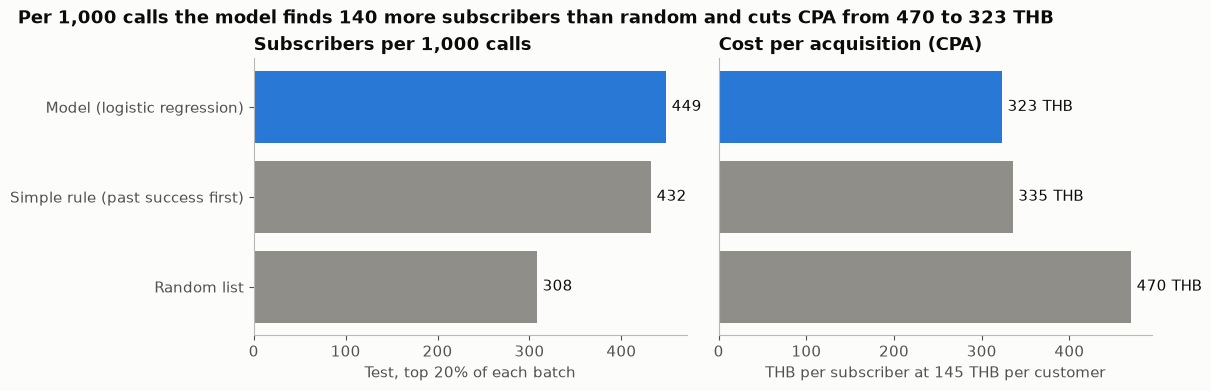

Model vs simple rule: +16 subscribers per 1,000 calls. The rule already captures most of the gain.


In [26]:
# W1 KPIs at a 20% contact capacity on Test
COST_EXAMPLE = COST_PER_CUSTOMER  # THB per customer, from 1.4
kpi_rows = []
for name, label in [('Random expected', 'Random list'), ('History rule', 'Simple rule (past success first)'),
                    (core_model, 'Model (logistic regression)')]:
    r = test_curves[name].loc[np.isclose(test_curves[name].fraction, .20)].iloc[0]
    kpi_rows.append(dict(method=label, contacted=int(r.selected), subscribers=float(r.found),
                         conversion_rate=r.precision, per_1000_calls=r.precision*1000,
                         CPA_THB=r.selected*COST_EXAMPLE/r.found, lift_vs_random=r.lift))
kpi = pd.DataFrame(kpi_rows); display(kpi.round(3)); kpi.to_csv(MODEL_OUT/'kpi_20pct_test.csv', index=False)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), layout='constrained')
cols = [GREY, GREY, HL]
b = axs[0].barh(kpi.method, kpi.per_1000_calls, color=cols); axs[0].bar_label(b, fmt='%.0f', padding=4)
axs[0].set(title='Subscribers per 1,000 calls', xlabel='Test, top 20% of each batch')
b = axs[1].barh(kpi.method, kpi.CPA_THB, color=cols); axs[1].bar_label(b, fmt='%.0f THB', padding=4)
axs[1].set(title='Cost per acquisition (CPA)', xlabel=f'THB per subscriber at {COST_EXAMPLE:.0f} THB per customer')
fig.suptitle(f'Per 1,000 calls the model finds {kpi.per_1000_calls.iloc[2]-kpi.per_1000_calls.iloc[0]:.0f} more subscribers than random '
             f'and cuts CPA from {kpi.CPA_THB.iloc[0]:.0f} to {kpi.CPA_THB.iloc[2]:.0f} THB',
             fontweight='bold', x=.01, ha='left')
axs[1].set_yticks([])
fig.savefig(MODEL_OUT/'08_kpi_per_1000_cpa.png', dpi=160); plt.show()
gap = kpi.per_1000_calls.iloc[2] - kpi.per_1000_calls.iloc[1]
print(f'Model vs simple rule: {gap:+.0f} subscribers per 1,000 calls. The rule already captures most of the gain.')

# บทที่ 4 เงิน: ควรโทรกี่ราย

**สูตร:** มูลค่าสุทธิ = ผู้สมัครที่พบ × มูลค่าต่อผู้สมัคร − รายชื่อที่โทร × ค่าติดต่อต่อราย และ **ใช้โมเดลตัวเดิมตลอดบท** ไม่เลือกโมเดลใหม่ตามเงิน

## 4.1 สถานการณ์ที่ทดลอง (27 แบบ)

ค่าโทร 3 ระดับ × จำนวนสาย 3 ระดับ × มูลค่า 3 ระดับ โดยสถานการณ์หลักใช้ตัวเลขจาก 1.4

In [27]:
CALL_COSTS = [25., CALL_COST, 100.]   # see 1.4
CALLS_PER_CUSTOMER = [1., CALLS_OBS, 4.]
VALUES = [VALUE_LOW, VALUE_BASE, VALUE_HIGH]
BASE_SCENARIO = f'call{CALL_COST:g}_calls{CALLS_OBS:g}_value{VALUE_BASE:g}'
scenarios = pd.DataFrame([
    dict(scenario=f'call{c:g}_calls{m:g}_value{v:g}', cost_per_call=c,
         assumed_calls=m, cost_per_customer=c*m, value_per_subscriber=v,
         value_cost_ratio=v/(c*m))
    for c in CALL_COSTS for m in CALLS_PER_CUSTOMER for v in VALUES
])
assert len(scenarios) == 27
display(scenarios)
scenarios.to_csv(BUSINESS_OUT/'scenario_assumptions.csv', index=False)


,scenario,cost_per_call,assumed_calls,cost_per_customer,value_per_subscriber,value_cost_ratio
0,call25_calls1_value500,25.0,1.0,25.0,500.0,20.000000
1,call25_calls1_value1500,25.0,1.0,25.0,1500.0,60.000000
2,call25_calls1_value3000,25.0,1.0,25.0,3000.0,120.000000
3,call25_calls2.9_value500,25.0,2.9,72.5,500.0,6.896552
4,call25_calls2.9_value1500,25.0,2.9,72.5,1500.0,20.689655
5,call25_calls2.9_value3000,25.0,2.9,72.5,3000.0,41.379310
6,call25_calls4_value500,25.0,4.0,100.0,500.0,5.000000
7,call25_calls4_value1500,25.0,4.0,100.0,1500.0,15.000000
8,call25_calls4_value3000,25.0,4.0,100.0,3000.0,30.000000
9,call50_calls1_value500,50.0,1.0,50.0,500.0,10.000000


## 4.2 หาจุดหยุดจาก Validation

> 🔧 **เทคนิค:** Profit curve: หาสัดส่วนที่ให้มูลค่าสุทธิสูงสุดบน Validation  
> 🎯 **ทำไม:** เลือกจุดหยุดจากข้อมูลที่ไม่ใช่ Test  
> 🗣️ **พูดว่า:** “บน Validation จุดที่คุ้มที่สุดคือโทรราว 61% แรกของรายชื่อ”

ลองเลือก 0–100% แล้วหาจุดที่มูลค่าสุทธิสูงสุด ถ้าเท่ากันเลือกจำนวนน้อยกว่า ตัวเลขเงินคิดจากผลย้อนหลัง ยังไม่ใช่กำไรที่พิสูจน์ว่าเกิดเพราะการโทร

In [28]:
def with_economics(curve,cost,value):
    z=curve.copy()
    z['contact_cost']=z.selected*cost
    z['scenario_net_value']=z.found*value-z.contact_cost
    z['random_expected_net_value']=z.random_expected*value-z.contact_cost
    return z

def choose_policy(table,value_column='scenario_net_value'):
    # Exact ties: fewer contacts, then stable model name. Never use Test to choose.
    return table.sort_values([value_column,'selected','model'],
        ascending=[False,True,True],kind='stable').iloc[0]


locked_rows=[];near_rows=[];validation_economics=[]
for scenario in scenarios.itertuples(index=False):
    pieces=[]
    for name in [core_model,'History rule','Random expected']:
        curve=validation_curves[name]
        t=with_economics(curve,scenario.cost_per_customer,scenario.value_per_subscriber)
        t['model']=name;t['scenario']=scenario.scenario
        pieces.append(t)
    table=pd.concat(pieces,ignore_index=True)
    validation_economics.append(table)
    families={'ML':[core_model], 'History':['History rule'],
              'Random':['Random expected'], 'Overall':[core_model,'History rule','Random expected']}
    for family,names in families.items():
        best=choose_policy(table[table.model.isin(names)])
        row=best.to_dict();row['family']=family
        row['cost_per_customer']=scenario.cost_per_customer
        row['value_per_subscriber']=scenario.value_per_subscriber
        locked_rows.append(row)
        if family=='ML':
            c=table[table.model.eq(best.model)]
            tolerance=max(abs(best.scenario_net_value)*.01,scenario.value_per_subscriber)
            near=c[c.scenario_net_value>=best.scenario_net_value-tolerance]
            near_rows.append(dict(scenario=scenario.scenario,model=best.model,
                near_best_min=float(near.fraction.min()),near_best_max=float(near.fraction.max()),
                tolerance=tolerance))
locked=pd.DataFrame(locked_rows)
near_best=pd.DataFrame(near_rows)
val_economics=pd.concat(validation_economics,ignore_index=True)
locked.to_csv(BUSINESS_OUT/'locked_validation_policies.csv',index=False)
near_best.to_csv(BUSINESS_OUT/'validation_near_best_ranges.csv',index=False)
val_economics.to_csv(BUSINESS_OUT/'validation_economic_curves.csv',index=False)
display(locked[locked.scenario.eq(BASE_SCENARIO)][
    ['family','model','fraction','selected','found','scenario_net_value']])
display(near_best[near_best.scenario.eq(BASE_SCENARIO)])
print('Policies locked using Validation only; Test will not choose a new cutoff.')

assert locked.loc[locked.family.eq('ML'),'model'].eq(core_model).all()


,family,model,fraction,selected,found,scenario_net_value
52,ML,Logistic regression 10.0,0.61,5025,636.0,225375.0
53,History,History rule,1.00,8238,912.0,173490.0
54,Random,Random expected,1.00,8238,912.0,173490.0
55,Overall,Logistic regression 10.0,0.61,5025,636.0,225375.0


,scenario,model,near_best_min,near_best_max,tolerance
13,call50_calls2.9_value1500,Logistic regression 10.0,0.6,0.61,2253.75


Policies locked using Validation only; Test will not choose a new cutoff.


## 4.3 เอาจุดหยุดนั้นไปใช้กับ Test

> 🔧 **เทคนิค:** นำจุดหยุดที่ล็อกไว้ไปใช้กับ Test (out-of-time evaluation)  
> 🎯 **ทำไม:** ดูว่ากฎที่ตั้งจากอดีตใช้กับอนาคตได้ไหม  
> 🗣️ **พูดว่า:** “แต่พอเอาไปใช้กับ Test ได้ 1.86 ล้านบาท ขณะที่ถ้าโทรทุกคนจะได้ 2.62 ล้าน แปลว่าจุดหยุดจากอดีตเข้มเกินไปสำหรับช่วงที่ลูกค้าตอบรับดี”

In [29]:
test_rows=[];same_rows=[]
for policy in locked.itertuples(index=False):
    curve=with_economics(test_curves[policy.model],policy.cost_per_customer,policy.value_per_subscriber)
    r=curve.loc[np.isclose(curve.fraction,policy.fraction)].iloc[0].to_dict()
    r.update(scenario=policy.scenario,family=policy.family,model=policy.model,
        validation_fraction=policy.fraction,validation_net_value=policy.scenario_net_value,
        cost_per_customer=policy.cost_per_customer,value_per_subscriber=policy.value_per_subscriber)
    test_rows.append(r)
    if policy.family=='ML':
        for name in [policy.model,'History rule','Random expected']:
            c=with_economics(test_curves[name],policy.cost_per_customer,policy.value_per_subscriber)
            s=c.loc[np.isclose(c.fraction,policy.fraction)].iloc[0].to_dict()
            s.update(scenario=policy.scenario,model=name)
            same_rows.append(s)
test_results=pd.DataFrame(test_rows)
same_capacity=pd.DataFrame(same_rows)
test_results.to_csv(BUSINESS_OUT/'test_locked_policy_results.csv',index=False)
same_capacity.to_csv(BUSINESS_OUT/'test_same_capacity_results.csv',index=False)
display(test_results[test_results.scenario.eq(BASE_SCENARIO)][
    ['family','model','fraction','selected','found','precision','recall','scenario_net_value']])
base=locked[(locked.scenario.eq(BASE_SCENARIO)) & locked.family.eq('ML')].iloc[0]
base_test=test_results[(test_results.scenario.eq(BASE_SCENARIO)) & test_results.family.eq('ML')].iloc[0]
display(same_capacity[same_capacity.scenario.eq(BASE_SCENARIO)])


,family,model,fraction,selected,found,precision,recall,scenario_net_value
52,ML,Logistic regression 10.0,0.61,5025.0,1723.0,0.342886,0.678346,1855875.0
53,History,History rule,1.00,8238.0,2540.0,0.308327,1.000000,2615490.0
54,Random,Random expected,1.00,8238.0,2540.0,0.308327,1.000000,2615490.0
55,Overall,Logistic regression 10.0,0.61,5025.0,1723.0,0.342886,0.678346,1855875.0


,fraction,selected,found,positive_total,precision,recall,random_expected,lift,contact_cost,scenario_net_value,random_expected_net_value,scenario,model
39,0.61,5025.0,1723.000000,2540.0,0.342886,0.678346,1549.311513,1.112107,728625.0,1.855875e+06,1.595342e+06,call50_calls2.9_value1500,Logistic regression 10.0
40,0.61,5025.0,1655.000000,2540.0,0.329353,0.651575,1549.311513,1.068216,728625.0,1.753875e+06,1.595342e+06,call50_calls2.9_value1500,History rule
41,0.61,5025.0,1549.311513,2540.0,0.308321,0.609965,1549.311513,1.000000,728625.0,1.595342e+06,1.595342e+06,call50_calls2.9_value1500,Random expected


## 4.4 ช่วงคะแนนไหนคุ้มที่จะโทร?

> 🔧 **เทคนิค:** Break-even analysis รายช่วงคะแนน (ค่าติดต่อ ÷ มูลค่า)  
> 🎯 **ทำไม:** อธิบายด้วยภาพเดียวว่าทำไมจุดหยุดย้ายข้ามช่วงไม่ได้  
> 🗣️ **พูดว่า:** “บน Validation มีแค่ 6 จาก 10 ช่วงคะแนนที่คุ้มโทร แต่บน Test คุ้มครบทั้ง 10 ช่วง จึงตั้งเปอร์เซ็นต์ตายตัวไม่ได้”

ช่วงคะแนนที่อัตราสมัครสูงกว่า **ค่าติดต่อ ÷ มูลค่า** คือช่วงที่คุ้ม ภาพนี้ตอบว่าทำไมจุดหยุดจาก Validation ใช้กับ Test ไม่ได้: จำนวนช่วงที่คุ้มต่างกันมากตามอัตราสมัครของช่วงนั้น

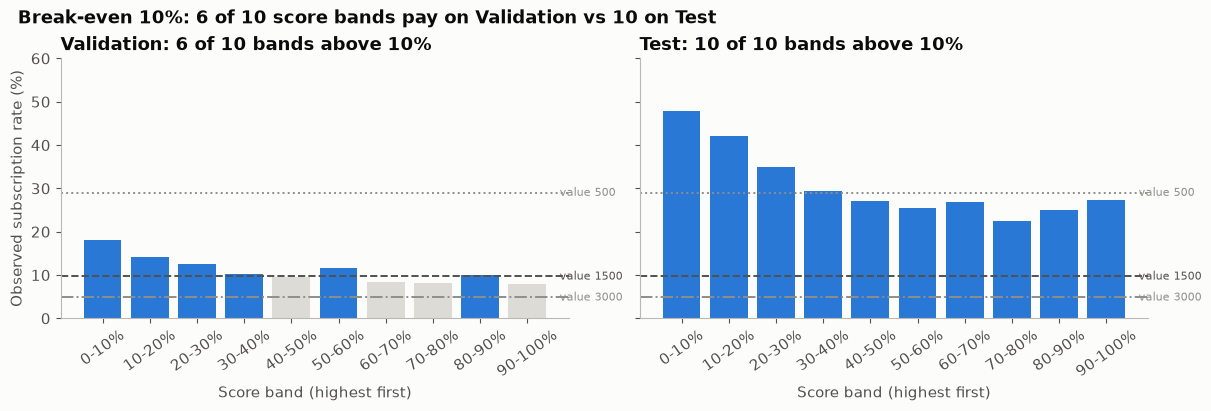

In [30]:
# Score-band rates vs break-even rates (cost / value)
fig, axs = plt.subplots(1, 2, figsize=(12, 4), layout='constrained', sharey=True)
n_pass = {}
bands = deciles.band.unique()
for ax, split in zip(axs, ['Validation', 'Test']):
    g = deciles[deciles.split.eq(split)]
    be = base.cost_per_customer/base.value_per_subscriber
    ax.bar(range(len(g)), g.rate*100, color=[HL if r >= be else LIGHT for r in g.rate])
    for v, ls in [(VALUE_LOW, ':'), (VALUE_BASE, '--'), (VALUE_HIGH, '-.')]:
        lvl = base.cost_per_customer/v*100
        ax.axhline(lvl, color=WARN if v == base.value_per_subscriber else GREY, ls=ls, lw=1.4)
        ax.text(len(g)-.4, lvl, f' value {v:g}', va='center', fontsize=8,
                color=WARN if v == base.value_per_subscriber else GREY)
    ax.set_xticks(range(len(g)), bands, rotation=35)
    n_ok = int((g.rate >= be).sum())
    n_pass[split] = n_ok
    ax.set(title=f'{split}: {n_ok} of 10 bands above {be:.0%}', xlabel='Score band (highest first)')
axs[0].set_ylabel('Observed subscription rate (%)'); axs[0].set_ylim(0, 60)
fig.suptitle(f'Break-even {be:.0%}: {n_pass["Validation"]} of 10 score bands pay on Validation vs {n_pass["Test"]} on Test',
             fontweight='bold', x=.01, ha='left')
fig.savefig(BUSINESS_OUT/'05b_break_even_bands.png', dpi=160); plt.show()

## 4.5 ทางแก้: โทรเมื่อโอกาสที่คาด > จุดคุ้มทุน และปรับตามรอบล่าสุด

> 🔧 **เทคนิค:** Calibration แบบ prior shift + decision threshold = ค่าติดต่อ ÷ มูลค่า + reliability diagram / Brier  
> 🎯 **ทำไม:** ให้จุดหยุดปรับตามอัตราสมัครล่าสุดเองอัตโนมัติ แก้ปัญหาที่ต้นฉบับพบแต่ยังไม่ได้แก้  
> 🗣️ **พูดว่า:** “ทางแก้คือโทรเมื่อโอกาสสมัครที่คาดเกินจุดคุ้มทุน และปรับตามรอบล่าสุด วิธีนี้ชนะทั้งสองช่วงในสถานการณ์หลัก: Test ได้ 2.65 ล้าน เทียบกับ 1.86 ล้าน”

คะแนนจากโมเดลที่ฝึกในช่วงอัตราสมัคร 5% ย่อมต่ำเกินไปสำหรับช่วง 30% จึง **เลื่อนระดับคะแนน (prior shift)** ให้ค่าเฉลี่ยตรงกับอัตราสมัครที่เห็นจริงในรอบที่โทรเสร็จล่าสุด แล้วโทรเมื่อคะแนนเกินจุดคุ้มทุน จำนวนรอบที่ใช้อ้างอิงเลือกจาก Validation ภาพซ้ายคือ reliability diagram ที่ดูว่าคะแนนใกล้อัตราสมัครจริงขึ้นไหม

,window_batches,validation_total_net
0,1,18779067.5
1,2,17937102.5
2,3,18309185.0
3,5,18256810.0
4,10,17534772.5


Window chosen on Validation: 1 batch(es)


,scenario,break_even,validation_fixed_net,validation_adaptive_net,test_fixed_net,test_adaptive_net,test_contact_all_net
0,call25_calls1_value500,0.050000,250125.0,252650.0,1052625.0,1058725.0,1064050.0
1,call25_calls1_value1500,0.016667,1162050.0,1160900.0,3604050.0,3604050.0,3604050.0
2,call25_calls1_value3000,0.008333,2530050.0,2530050.0,7414050.0,7414050.0,7414050.0
3,call25_calls2.9_value500,0.145000,15425.0,26420.0,173425.0,743862.5,672745.0
4,call25_calls2.9_value1500,0.048333,770762.5,778477.5,3178262.5,3196935.0,3212745.0
5,call25_calls2.9_value3000,0.024167,2138745.0,2136170.0,7022745.0,7020397.5,7022745.0
6,call25_calls4_value500,0.200000,3800.0,-19200.0,36800.0,599200.0,446200.0
7,call25_calls4_value1500,0.066667,546500.0,552500.0,2954000.0,2977200.0,2986200.0
8,call25_calls4_value3000,0.033333,1912200.0,1886900.0,6796200.0,6786700.0,6796200.0
9,call50_calls1_value500,0.100000,66750.0,94350.0,610250.0,874750.0,858100.0


Adaptive beats fixed share in 18/27 Test and 12/27 Validation scenarios
Test Brier score  raw: 0.2181  adapted: 0.1891


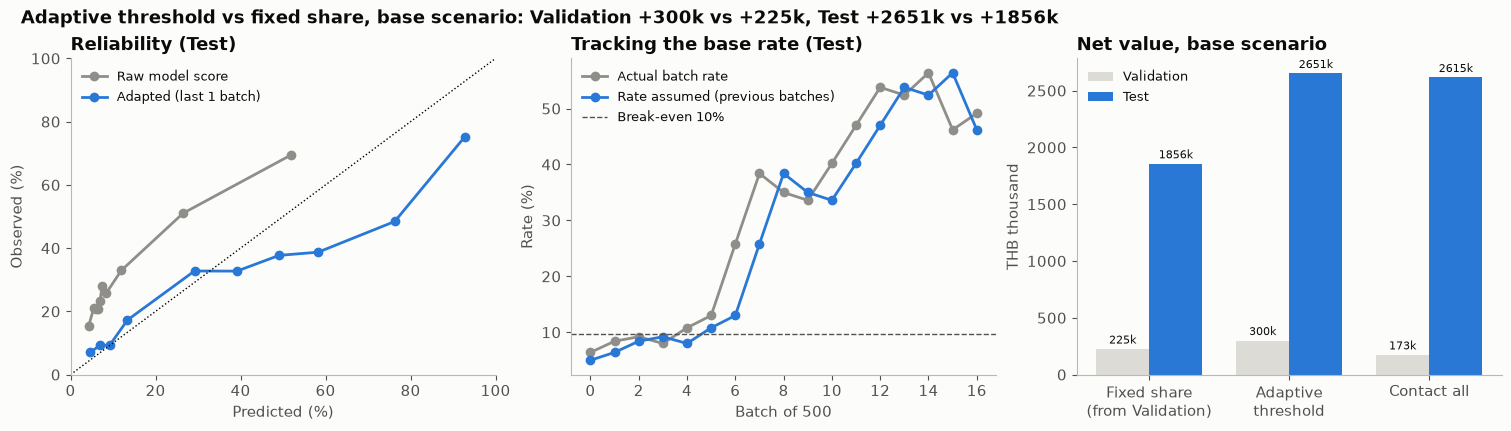

In [31]:
# Prior-shift recalibration from the latest finished batches, then threshold at cost/value
from sklearn.metrics import brier_score_loss
def logit(p):
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6); return np.log(p/(1 - p))
def prior_shift_scores(p, target, prior, history, window, batch_size=BATCH_SIZE):
    p, target = np.asarray(p, float), np.asarray(target)
    seen = list(np.asarray(history)[-window*batch_size:]); out = np.empty_like(p); used = []
    for s in range(0, len(p), batch_size):
        sl = slice(s, s + batch_size); recent = float(np.mean(seen[-window*batch_size:]))
        out[sl] = 1/(1 + np.exp(-(logit(p[sl]) + logit(recent) - logit(prior)))); used.append(recent)
        seen += list(target[sl])                       # outcomes known once the batch is finished
    return out, np.array(used)
def threshold_net(scores, target, cost, value):
    sel = np.asarray(scores) > cost/value; t = np.asarray(target)
    return dict(selected=int(sel.sum()), found=int(t[sel].sum()), net=float(t[sel].sum()*value - sel.sum()*cost))

yv_arr = y.iloc[valid].to_numpy()
prior_val, prior_test = float(y.iloc[train].mean()), float(y.iloc[:cut2].mean())
win_table = pd.DataFrame([dict(window_batches=W, validation_total_net=sum(
    threshold_net(prior_shift_scores(val_scores[core_model], yv_arr, prior_val, y.iloc[train], W)[0], yv_arr,
                  s.cost_per_customer, s.value_per_subscriber)['net'] for s in scenarios.itertuples()))
    for W in [1, 2, 3, 5, 10]])
W_BEST = int(win_table.sort_values(['validation_total_net', 'window_batches'], ascending=[False, True]).iloc[0].window_batches)
display(win_table); print('Window chosen on Validation:', W_BEST, 'batch(es)')
adapt_val, _ = prior_shift_scores(val_scores[core_model], yv_arr, prior_val, y.iloc[train], W_BEST)
adapt_test, used_rate = prior_shift_scores(test_scores[core_model], yt_arr, prior_test, y.iloc[:cut2], W_BEST)

fixed_val = locked[locked.family.eq('ML')].set_index('scenario').scenario_net_value
fixed_test = test_results[test_results.family.eq('ML')].set_index('scenario').scenario_net_value
adaptive_rows = []
for s in scenarios.itertuples():
    tv = threshold_net(adapt_test, yt_arr, s.cost_per_customer, s.value_per_subscriber)
    vv = threshold_net(adapt_val, yv_arr, s.cost_per_customer, s.value_per_subscriber)
    adaptive_rows.append(dict(scenario=s.scenario, cost_per_customer=s.cost_per_customer, value_per_subscriber=s.value_per_subscriber,
        break_even=s.cost_per_customer/s.value_per_subscriber,
        validation_fixed_net=fixed_val[s.scenario], validation_adaptive_net=vv['net'],
        test_fixed_net=fixed_test[s.scenario], test_adaptive_net=tv['net'], test_adaptive_selected=tv['selected'],
        test_contact_all_net=yt_arr.sum()*s.value_per_subscriber - len(yt_arr)*s.cost_per_customer))
adaptive = pd.DataFrame(adaptive_rows); adaptive.to_csv(BUSINESS_OUT/'adaptive_threshold_policy.csv', index=False)
adapt_wins_test = int((adaptive.test_adaptive_net > adaptive.test_fixed_net).sum())
adapt_wins_val = int((adaptive.validation_adaptive_net > adaptive.validation_fixed_net).sum())
adapt_base = adaptive.set_index('scenario').loc[BASE_SCENARIO]
display(adaptive[['scenario', 'break_even', 'validation_fixed_net', 'validation_adaptive_net',
                  'test_fixed_net', 'test_adaptive_net', 'test_contact_all_net']])
print(f'Adaptive beats fixed share in {adapt_wins_test}/27 Test and {adapt_wins_val}/27 Validation scenarios')

calib = pd.DataFrame({'raw': test_scores[core_model], 'adapted': adapt_test, 'y': yt_arr})
print('Test Brier score  raw:', round(brier_score_loss(yt_arr, calib.raw), 4), ' adapted:', round(brier_score_loss(yt_arr, calib.adapted), 4))
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), layout='constrained')
a = axs[0]
for col, c, lab in [('raw', GREY, 'Raw model score'), ('adapted', HL, f'Adapted (last {W_BEST} batch)')]:
    g = calib.groupby(pd.qcut(calib[col], 10, duplicates='drop'), observed=True).agg(p=(col, 'mean'), obs=('y', 'mean'))
    a.plot(g.p*100, g.obs*100, marker='o', color=c, label=lab)
a.plot([0, 100], [0, 100], ls=':', color='black', lw=1); a.legend(frameon=False, fontsize=9)
a.set(title='Reliability (Test)', xlabel='Predicted (%)', ylabel='Observed (%)', xlim=(0, 100), ylim=(0, 100))
a = axs[1]
batch_rate = [yt_arr[s:s+BATCH_SIZE].mean() for s in range(0, len(yt_arr), BATCH_SIZE)]
a.plot(np.array(batch_rate)*100, color=GREY, marker='o', label='Actual batch rate')
a.plot(used_rate*100, color=HL, marker='o', label='Rate assumed (previous batches)')
a.axhline(base.cost_per_customer/base.value_per_subscriber*100, color=WARN, ls='--', lw=1, label=f'Break-even {base.cost_per_customer/base.value_per_subscriber:.0%}')
a.legend(frameon=False, fontsize=9); a.set(title='Tracking the base rate (Test)', xlabel='Batch of 500', ylabel='Rate (%)')
a = axs[2]
labels_ = ['Fixed share\n(from Validation)', 'Adaptive\nthreshold', 'Contact all']
for j, (split, vals) in enumerate([('Validation', [adapt_base.validation_fixed_net, adapt_base.validation_adaptive_net,
                                                    float(yv_arr.sum()*base.value_per_subscriber - len(yv_arr)*base.cost_per_customer)]),
                                   ('Test', [adapt_base.test_fixed_net, adapt_base.test_adaptive_net, adapt_base.test_contact_all_net])]):
    b = a.bar(np.arange(3) + (j - .5)*.38, np.array(vals)/1000, .38, color=LIGHT if j == 0 else HL, label=split)
    a.bar_label(b, fmt='%.0fk', fontsize=8, padding=2)
a.axhline(0, color='black', lw=.6); a.set_xticks(range(3), labels_); a.legend(frameon=False, fontsize=9)
a.set(title='Net value, base scenario', ylabel='THB thousand')
fig.suptitle(f'Adaptive threshold vs fixed share, base scenario: Validation {adapt_base.validation_adaptive_net/1000:+.0f}k vs '
             f'{adapt_base.validation_fixed_net/1000:+.0f}k, Test {adapt_base.test_adaptive_net/1000:+.0f}k vs {adapt_base.test_fixed_net/1000:+.0f}k',
             fontweight='bold', x=.01, ha='left')
fig.savefig(BUSINESS_OUT/'05c_adaptive_threshold.png', dpi=160); plt.show()

# บทที่ 5 Insight: อะไรที่ทำได้ทันที

> 🔧 **เทคนิค:** Exploratory data visualization (W12): story-first, ชื่อกราฟเป็นข้อสรุป, palette ผ่าน CVD, หนึ่งแกนต่อกราฟ  
> 🎯 **ทำไม:** หา insight ที่ทำได้ทันที นอกเหนือจากโมเดล  
> 🗣️ **พูดว่า:** “นอกจากโมเดล ข้อมูลยังบอกสิ่งที่ทำได้ทันทีอีกหลายเรื่อง ทุกกราฟมีหนึ่งข้อความ และชื่อกราฟคือข้อสรุป”

แต่ละกราฟตอบหนึ่งคำถาม และชื่อกราฟคือข้อสรุป **สีของช่วงเวลาคงที่ทั้งเล่ม** (Train = ฟ้า, Validation = ส้ม, Test = เขียวน้ำทะเล) palette ผ่านการตรวจตาบอดสี หนึ่งกราฟใช้แกน y เดียว (W12: story-first, C.R.A.P., reduce clutter)

พาร์ตนี้ใช้ผลของทุกช่วงหลังจากล็อกโมเดลและจุดหยุดแล้ว จึงไม่ได้ย้อนกลับไปเปลี่ยนการเลือกโมเดล และทุกข้อเป็นความสัมพันธ์

In [32]:
# Chapter 5 shared helpers
VALUE_REAL = VALUE_BASE   # same assumptions as 1.4 / chapter 4
yes_all = raw.y.eq('yes').to_numpy()
def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float); p = k/n; den = 1 + z*z/n
    c = (p + z*z/(2*n))/den; h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/den
    return c - h, c + h
SPLITS = list(PERIOD_COLORS)
# own name: the original cells reuse `split_name` as a loop variable
period = pd.Series(np.select([np.arange(len(raw)) < c1, np.arange(len(raw)) < c2], ['Train', 'Validation'], 'Test'))

## 5.1 โทรซ้ำครั้งที่เท่าไรถึงไม่คุ้ม?

> 🔧 **เทคนิค:** Discrete hazard (อัตราสมัครต่อสายที่ k แบบ survival analysis) + กฎ "โทรไม่เกิน N ครั้ง"  
> 🎯 **ทำไม:** ลดต้นทุนจากจำนวนสาย ไม่ใช่จำนวนลูกค้า (operations)  
> 🗣️ **พูดว่า:** “โทรซ้ำได้ผลลดลงเรื่อย ๆ สายแรกได้ 16% แต่สายที่ห้าเหลือ 6% การตั้งเพดานจำนวนครั้งจึงควรดูอัตราต่อสายล่าสุด ไม่ใช่ตัวเลขตายตัว”

อัตราสมัครของ **สายที่ k** = คนที่สมัครในสายที่ k ÷ คนที่ยังถูกโทรถึงสายที่ k สายนั้นคุ้มเมื่ออัตรานี้ > ค่าโทรต่อสาย ÷ มูลค่า จากนั้นลองกฎ "โทรไม่เกิน N ครั้ง" โดยเลือก N บน Validation

,calls,subscribers,calls_saved,subscribers_lost,net_vs_no_cap
split,,,,,
Train,57858,1069,0.191,0.100,503400.0
Validation,15799,897,0.044,0.016,13650.0
Test,16672,2488,0.060,0.020,-24800.0


Cap chosen on Validation: at most 5 calls per customer


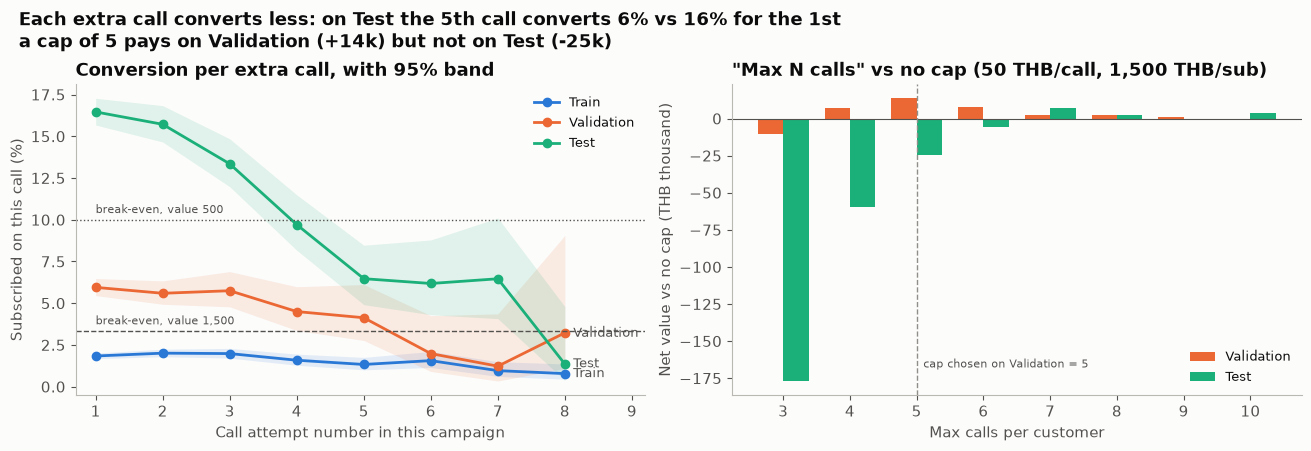

In [33]:
# Per-attempt conversion (discrete hazard) and a "max N calls" rule
K_MAX = 8
haz_rows = []
for sp in SPLITS:
    g = raw[period.eq(sp).to_numpy()]
    for k in range(1, K_MAX + 1):
        at_risk = int((g.campaign >= k).sum()); succ = int(((g.campaign == k) & g.y.eq('yes')).sum())
        lo, hi = wilson(succ, at_risk)
        haz_rows.append(dict(split=sp, call=k, at_risk=at_risk, subscribed=succ, rate=succ/at_risk, lo=float(lo), hi=float(hi)))
hazard = pd.DataFrame(haz_rows); hazard.to_csv(BUSINESS_OUT/'per_call_conversion.csv', index=False)

def cap_result(g, cap, cost=CALL_COST, value=VALUE_REAL):
    calls = np.minimum(g.campaign, cap).sum(); kept = int((g.y.eq('yes') & (g.campaign <= cap)).sum())
    return dict(calls=int(calls), subscribers=kept, net=kept*value - calls*cost)
cap_rows = []
for sp in SPLITS:
    g = raw[period.eq(sp).to_numpy()]; full = cap_result(g, 10**6)
    for cap in list(range(1, 11)) + [None]:
        r = cap_result(g, 10**6 if cap is None else cap)
        cap_rows.append(dict(split=sp, cap='no cap' if cap is None else cap, **r,
                             calls_saved=1 - r['calls']/full['calls'], subscribers_lost=1 - r['subscribers']/full['subscribers'],
                             net_vs_no_cap=r['net'] - full['net']))
caps = pd.DataFrame(cap_rows); caps.to_csv(BUSINESS_OUT/'call_cap_policy.csv', index=False)
val_caps = caps[caps.split.eq('Validation') & caps.cap.ne('no cap')]
CAP_BEST = int(val_caps.sort_values(['net', 'cap'], ascending=[False, True]).iloc[0].cap)
cap_view = caps[caps.cap.eq(CAP_BEST)].set_index('split')
display(cap_view[['calls', 'subscribers', 'calls_saved', 'subscribers_lost', 'net_vs_no_cap']].round(3))
print(f'Cap chosen on Validation: at most {CAP_BEST} calls per customer')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.4), layout='constrained')
for sp in SPLITS:
    h = hazard[hazard.split.eq(sp)]
    a1.fill_between(h.call, h.lo*100, h.hi*100, color=PERIOD_COLORS[sp], alpha=.12, lw=0)
    a1.plot(h.call, h.rate*100, color=PERIOD_COLORS[sp], marker='o', ms=6, label=sp)
    a1.annotate(sp, (h.call.iloc[-1], h.rate.iloc[-1]*100), textcoords='offset points', xytext=(6, 0), va='center',
                fontsize=9, color=INK2)
for v, lab in [(VALUE_LOW, 'break-even, value 500'), (VALUE_REAL, 'break-even, value 1,500')]:
    a1.axhline(CALL_COST/v*100, color=WARN, ls='--' if v == VALUE_REAL else ':', lw=1)
    a1.text(1, CALL_COST/v*100 + .4, lab, fontsize=8, color=INK2)
a1.set(xlabel='Call attempt number in this campaign', ylabel='Subscribed on this call (%)', xlim=(.7, K_MAX + 1.2),
       title='Conversion per extra call, with 95% band')
a1.legend(frameon=False, fontsize=9)
show = caps[caps.cap.ne('no cap') & caps.cap.ne(1) & caps.cap.ne(2)]   # caps 1-2 lose far more; see table
w = .38
for j, sp in enumerate(['Validation', 'Test']):
    d = show[show.split.eq(sp)]
    a2.bar(d.cap.astype(int) + (j - .5)*w, d.net_vs_no_cap/1000, w, color=PERIOD_COLORS[sp], label=sp)
a2.axhline(0, color=INK2, lw=.8); a2.axvline(CAP_BEST, color=GREY, ls='--', lw=1)
a2.text(CAP_BEST + .1, a2.get_ylim()[0]*.9, f'cap chosen on Validation = {CAP_BEST}', fontsize=8, color=INK2)
a2.set(xlabel='Max calls per customer', ylabel='Net value vs no cap (THB thousand)', xticks=range(3, 11),
       title=f'"Max N calls" vs no cap ({CALL_COST:.0f} THB/call, {VALUE_REAL:,.0f} THB/sub)')
a2.legend(frameon=False, fontsize=9)
h_t = hazard[hazard.split.eq('Test')].set_index('call').rate
fig.suptitle(f'Each extra call converts less: on Test the 5th call converts {h_t[5]:.0%} vs {h_t[1]:.0%} for the 1st\n'
             f'a cap of {CAP_BEST} pays on Validation ({cap_view.net_vs_no_cap["Validation"]/1000:+.0f}k) but not on Test ({cap_view.net_vs_no_cap["Test"]/1000:+.0f}k)',
             fontweight='bold', x=.01, ha='left')
fig.savefig(BUSINESS_OUT/'11_per_call_conversion_cap.png', dpi=160); plt.show()

## 5.2 มือถือหรือโทรศัพท์บ้าน?

> 🔧 **เทคนิค:** Dumbbell chart + Wilson CI แยกตามช่วงเวลา  
> 🎯 **ทำไม:** เทียบช่องทางโดยดูว่าความต่างคงที่ทุกช่วงหรือเปล่า (Place ใน 4Ps)  
> 🗣️ **พูดว่า:** “โทรเบอร์มือถือได้ผลดีกว่าโทรศัพท์บ้านราว 1.5 เท่า และเป็นแบบนี้ทุกช่วงเวลา”

ช่องทางเป็นสิ่งที่ธนาคารเลือกเองได้ (Place) จุดสองจุดต่อหนึ่งช่วงเวลา และช่องว่างระหว่างจุดคือความต่าง

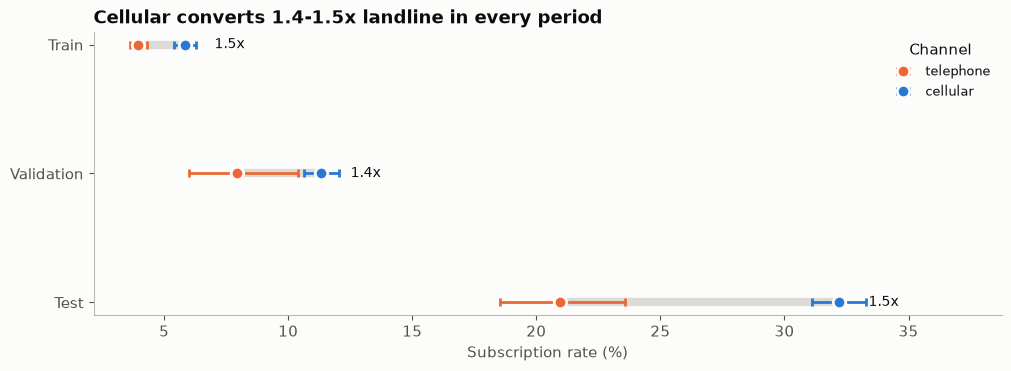

,split,contact,n,k,rate,lo,hi
0,Test,cellular,7245,2332,0.322,0.311,0.333
1,Test,telephone,993,208,0.209,0.185,0.236
2,Train,cellular,11254,656,0.058,0.054,0.063
3,Train,telephone,13458,532,0.040,0.036,0.043
4,Validation,cellular,7645,865,0.113,0.106,0.120
5,Validation,telephone,593,47,0.079,0.060,0.104


In [34]:
# Channel dumbbell per period
ch = (raw.assign(split=period.to_numpy(), yes=yes_all).groupby(['split', 'contact'])
      .yes.agg(n='size', k='sum').reset_index())
ch['rate'] = ch.k/ch.n; ch['lo'], ch['hi'] = wilson(ch.k, ch.n)
ch.to_csv(BUSINESS_OUT/'channel_rates.csv', index=False)
piv = ch.pivot(index='split', columns='contact', values='rate').loc[SPLITS]
ratio = piv.cellular/piv.telephone
fig, ax = plt.subplots(figsize=(10, 3.6), layout='constrained')
for i, sp in enumerate(SPLITS):
    ax.plot([piv.telephone[sp]*100, piv.cellular[sp]*100], [i, i], color=LIGHT, lw=6, solid_capstyle='round', zorder=1)
    for chn in ['telephone', 'cellular']:
        r = ch[(ch.split == sp) & (ch.contact == chn)].iloc[0]
        ax.errorbar(r.rate*100, i, xerr=[[(r.rate-r.lo)*100], [(r.hi-r.rate)*100]], fmt='o', ms=9,
                    color=CHANNEL_COLORS[chn], ecolor=CHANNEL_COLORS[chn], capsize=3, zorder=3,
                    markeredgecolor='#fcfcfb', markeredgewidth=2, label=chn if i == 0 else None)
    ax.text(piv.cellular[sp]*100 + 1.2, i, f'{ratio[sp]:.1f}x', va='center', fontsize=10, color=INK)
ax.set_yticks(range(len(SPLITS)), SPLITS); ax.invert_yaxis()
ax.set(xlabel='Subscription rate (%)', title=f'Cellular converts {ratio.min():.1f}-{ratio.max():.1f}x landline in every period')
ax.set_xlim(right=ax.get_xlim()[1] + 4)
ax.legend(frameon=False, loc='upper right', title='Channel', fontsize=9)
fig.savefig(BUSINESS_OUT/'12_channel_dumbbell.png', dpi=160); plt.show()
display(ch.round(3))

## 5.3 วัยไหนตอบรับดีที่สุด?

> 🔧 **เทคนิค:** Small multiples แยกตามช่วงเวลา (สเกลแยก)  
> 🎯 **ทำไม:** เทียบรูปแบบตามอายุ แม้อัตราสมัครแต่ละช่วงต่างกันมาก (Targeting)  
> 🗣️ **พูดว่า:** “ลูกค้าอายุต่ำกว่า 25 และ 60 ปีขึ้นไปตอบรับสูงกว่าค่าเฉลี่ยทุกช่วง กลุ่ม 60+ สมัครถึง 43–46%”

แยกเป็นหนึ่งช่องต่อหนึ่งช่วงเวลา (สเกลแยกกันเพราะระดับต่างกันมาก) กลุ่ม 60+ แทบไม่มีใน Train จึงไม่ปรากฏเป็นกลุ่มของ K-means ใน 2.5

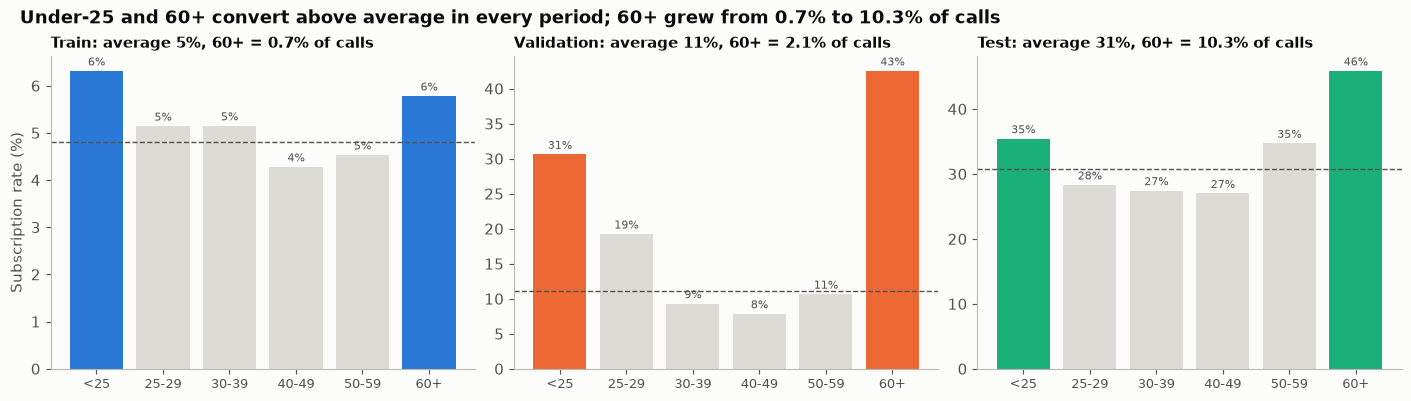

In [35]:
# Age U-shape, small multiples by period
AGE_BANDS = ['<25', '25-29', '30-39', '40-49', '50-59', '60+']
age = raw.assign(split=period.to_numpy(), yes=yes_all,
                 band=pd.cut(raw.age, [0, 24, 29, 39, 49, 59, 120], labels=AGE_BANDS))
age_tab = age.groupby(['split', 'band'], observed=True).yes.agg(n='size', rate='mean').reset_index()
age_tab.to_csv(BUSINESS_OUT/'age_band_rates.csv', index=False)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.9), layout='constrained')
for ax, sp in zip(axs, SPLITS):
    d = age_tab[age_tab.split.eq(sp)].set_index('band').reindex(AGE_BANDS); base_rate = age[age.split.eq(sp)].yes.mean()
    bars = ax.bar(AGE_BANDS, d.rate*100, color=[PERIOD_COLORS[sp] if b in ('<25', '60+') else LIGHT for b in AGE_BANDS])
    ax.bar_label(bars, labels=[f'{r:.0%}' for r in d.rate], fontsize=8, padding=2, color=INK2)
    ax.axhline(base_rate*100, color=WARN, ls='--', lw=1)
    share60 = d.n['60+']/d.n.sum()
    ax.set_title(f'{sp}: average {base_rate:.0%}, 60+ = {share60:.1%} of calls', fontsize=11)
    ax.tick_params(axis='x', labelsize=9)
axs[0].set_ylabel('Subscription rate (%)')
s60 = age_tab.pivot(index='band', columns='split', values='n').loc['60+']/age_tab.groupby('split').n.sum()
assert all((age_tab[age_tab.split.eq(sp)].set_index('band').rate[['<25', '60+']] > age[age.split.eq(sp)].yes.mean()).all() for sp in SPLITS)
fig.suptitle(f'Under-25 and 60+ convert above average in every period; 60+ grew from {s60["Train"]:.1%} to {s60["Test"]:.1%} of calls',
             fontweight='bold', x=.01, ha='left')
fig.savefig(BUSINESS_OUT/'13_age_small_multiples.png', dpi=160); plt.show()

## 5.4 ทำไมต้องตัด `duration` ออก?

> 🔧 **เทคนิค:** Leakage check: AUC ของ `duration` ตัวเดียว + อัตราสมัครราย decile  
> 🎯 **ทำไม:** เป็นหลักฐานว่าทำไมต้องตัดตัวแปรที่รู้หลังโทร  
> 🗣️ **พูดว่า:** “ระยะเวลาการคุยบอกผลได้ดีกว่าโมเดลเรามาก แต่รู้ค่าหลังวางสาย ถ้าใส่ไว้ก็คือโกงข้อสอบ เราจึงตัดออก”

ระยะเวลาการคุยบอกผลได้เกือบหมด แต่รู้ค่าหลังวางสาย ถ้าใส่ในโมเดล ผลจะดูดีเกินจริงแต่ใช้เลือกรายชื่อล่วงหน้าไม่ได้ (data leakage)

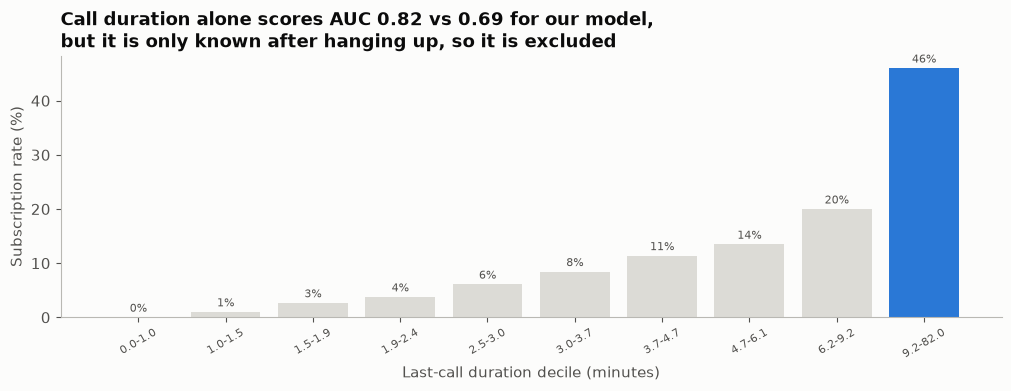

In [36]:
# Leakage illustration: outcome rate by call-duration decile
dur = raw.assign(yes=yes_all, decile=pd.qcut(raw.duration, 10, labels=False) + 1)
dt = dur.groupby('decile').agg(rate=('yes', 'mean'), lo_s=('duration', 'min'), hi_s=('duration', 'max')).reset_index()
auc_duration = roc_auc_score(yes_all, raw.duration)
fig, ax = plt.subplots(figsize=(10, 3.8), layout='constrained')
bars = ax.bar(dt.decile, dt.rate*100, color=[HL if d == 10 else LIGHT for d in dt.decile])
ax.bar_label(bars, labels=[f'{r:.0%}' for r in dt.rate], fontsize=8, padding=2, color=INK2)
ax.set_xticks(dt.decile, [f'{a/60:.1f}-{b/60:.1f}' for a, b in zip(dt.lo_s, dt.hi_s)],
              rotation=30, fontsize=8)
ax.set(ylabel='Subscription rate (%)', xlabel='Last-call duration decile (minutes)')
ax.set_title(f'Call duration alone scores AUC {auc_duration:.2f} vs {model_test_metrics.set_index("model").auc[core_model]:.2f} '
             f'for our model,\nbut it is only known after hanging up, so it is excluded')
fig.savefig(MODEL_OUT/'14_duration_leakage.png', dpi=160); plt.show()

## 5.5 โทรเยอะ = ได้ผลดี?

> 🔧 **เทคนิค:** Bubble scatter (แกน log) + Spearman rank correlation  
> 🎯 **ทำไม:** ดูความสัมพันธ์ระหว่างปริมาณการโทรกับอัตราสมัครรายเดือน  
> 🗣️ **พูดว่า:** “เดือนที่โทรน้อยแต่เลือกคนได้อัตราสมัครสูงกว่าเดือนที่โทรแบบหว่านแหชัดเจน”

หนึ่งจุดคือหนึ่งเดือน เดือนที่โทรน้อยและเลือกคนได้อัตราสูงกว่ามาก แต่ผลนี้ปนกับผลของช่วงเวลาด้วย จึงอ่านคู่กับไทม์ไลน์ 1.3

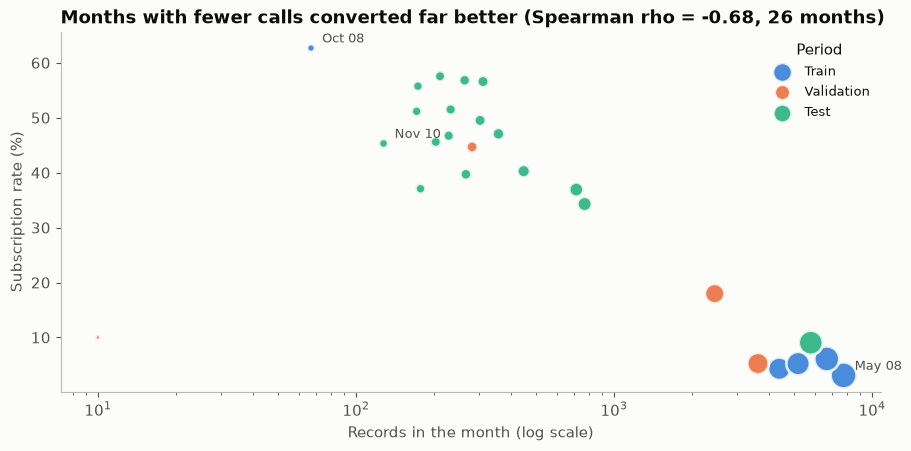

In [37]:
# Monthly volume vs conversion (one axis per measure; log x)
from scipy.stats import spearmanr
rho, pval = spearmanr(monthly.records, monthly.rate)
fig, ax = plt.subplots(figsize=(9, 4.4), layout='constrained')
for sp, col in PERIOD_COLORS.items():
    m = month_split.eq(sp).to_numpy()
    ax.scatter(monthly.records[m], monthly.rate[m]*100, s=np.sqrt(monthly.records[m])*4, color=col, alpha=.85,
               edgecolor='#fcfcfb', linewidth=2, label=sp, zorder=3)
for i in [monthly.records.values.argmax(), monthly.rate.values.argmax(), len(monthly) - 1]:
    ax.annotate(tl_labels[i], (monthly.records.iloc[i], monthly.rate.iloc[i]*100), textcoords='offset points',
                xytext=(8, 4), fontsize=9, color=INK2)
ax.set_xscale('log'); ax.legend(frameon=False, title='Period', fontsize=9)
ax.set(xlabel='Records in the month (log scale)', ylabel='Subscription rate (%)',
       title=f'Months with fewer calls converted far better (Spearman rho = {rho:.2f}, {len(monthly)} months)')
fig.savefig(BUSINESS_OUT/'15_volume_vs_conversion.png', dpi=160); plt.show()

## 5.6 ควรเลือกวันโทรไหม?

> 🔧 **เทคนิค:** Heatmap สีแบบ diverging (เทียบค่าเฉลี่ยของแต่ละช่วง)  
> 🎯 **ทำไม:** ตรวจว่าควรจัดตารางโทรตามวันไหม ผลที่บอกว่า "ไม่ต้องทำ" ก็เป็น insight  
> 🗣️ **พูดว่า:** “วันในสัปดาห์ไม่มีผลที่สม่ำเสมอ ไม่ต้องเสียแรงจัดตารางโทรตามวัน”

สีคือความต่างจากค่าเฉลี่ยของช่วงเดียวกัน ถ้าไม่มีวันไหนดีกว่าสม่ำเสมอทุกช่วง ก็ไม่ต้องเสียแรงจัดตารางตามวัน

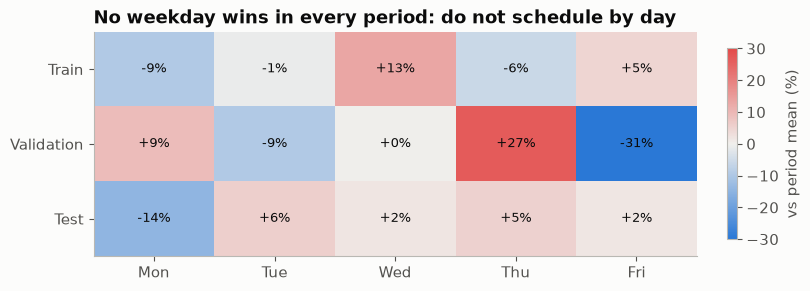

In [38]:
# Weekday effect relative to each period's mean (diverging, grey = no difference)
DAYS = ['mon', 'tue', 'wed', 'thu', 'fri']
wd = raw.assign(split=period.to_numpy(), yes=yes_all).pivot_table(index='split', columns='day_of_week', values='yes',
                                                                        aggfunc='mean').loc[SPLITS, DAYS]
wd_rel = wd.div(raw.assign(split=period.to_numpy(), yes=yes_all).groupby('split').yes.mean().loc[SPLITS], axis=0) - 1
fig, ax = plt.subplots(figsize=(8, 2.8), layout='constrained')
im = ax.imshow(wd_rel.to_numpy()*100, cmap=DIVERGING, vmin=-30, vmax=30, aspect='auto')
for i in range(len(SPLITS)):
    for j in range(len(DAYS)):
        ax.text(j, i, f'{wd_rel.iloc[i, j]:+.0%}', ha='center', va='center', fontsize=9, color=INK)
ax.set_xticks(range(len(DAYS)), [d.title() for d in DAYS]); ax.set_yticks(range(len(SPLITS)), SPLITS)
fig.colorbar(im, ax=ax, label='vs period mean (%)', shrink=.85)
best_day_consistent = (wd_rel > .05).all().any()   # >5% above the period mean every time
ax.set_title('No weekday wins in every period: do not schedule by day' if not best_day_consistent
             else 'One weekday beats the average by >5% in every period')
fig.savefig(BUSINESS_OUT/'16_weekday_heatmap.png', dpi=160); plt.show()

## 5.7 สรุป insight

> 🔧 **เทคนิค:** ตาราง insight → หลักฐาน → สิ่งที่ทำได้ → rubric  
> 🎯 **ทำไม:** รวมข้อค้นพบให้พร้อมใช้บนสไลด์  
> 🗣️ **พูดว่า:** “สรุปเป็นหกข้อที่ธนาคารทำได้ทันที แต่ละข้อมีหลักฐานจากข้อมูลกำกับ”

In [39]:
# Insight summary for the closing slide
h_v = hazard[hazard.split.eq('Validation')].set_index('call').rate
r60 = age_tab[age_tab.band.eq('60+')].set_index('split').rate
insights = f"""| # | Insight | หลักฐานจากข้อมูล | สิ่งที่ธนาคารทำได้ | Rubric |
|---|---|---|---|---|
| 1 | โทรซ้ำได้ผลลดลงเรื่อย ๆ | Test: สายที่ 1 ได้ {h_t[1]:.0%} → สายที่ 5 ได้ {h_t[5]:.0%}; Validation: {h_v[1]:.1%} → {h_v[5]:.1%} | เพดาน **โทรไม่เกิน {CAP_BEST} ครั้ง** (เลือกบน Validation): ประหยัดสาย {cap_view.calls_saved['Test']:.0%} เสียผู้สมัคร {cap_view.subscribers_lost['Test']:.1%} บน Test แต่สุทธิ {cap_view.net_vs_no_cap['Validation']/1000:+.0f}k (Val) / {cap_view.net_vs_no_cap['Test']/1000:+.0f}k (Test) จึงคุ้มเฉพาะช่วงที่อัตราสมัครต่ำ ควรตั้งเพดานตามอัตราต่อสายล่าสุด | Analysis, Conclusion |
| 2 | มือถือได้ผลดีกว่าโทรศัพท์บ้าน | มือถือได้มากกว่า {ratio.min():.1f}–{ratio.max():.1f} เท่าในทุกช่วง | ให้ความสำคัญกับเบอร์มือถือ และเก็บเบอร์มือถือของลูกค้าให้ครบ (Place) | Analysis, 4Ps |
| 3 | อายุต่ำกว่า 25 และ 60+ สูงกว่าค่าเฉลี่ยทุกช่วง | 60+ ได้ {r60['Validation']:.0%} (Val) และ {r60['Test']:.0%} (Test) | ทำข้อความและข้อเสนอเฉพาะวัยเกษียณกับวัยเริ่มทำงาน (Targeting) | STP |
| 4 | `duration` รั่วข้อมูล | ใช้ตัวเดียวได้ AUC {auc_duration:.2f} แต่รู้ค่าหลังวางสาย | ใช้เฉพาะข้อมูลที่มีก่อนโทร | Data justification |
| 5 | โทรน้อยแต่เลือกคน ดีกว่าหว่านแห | Spearman rho = {rho:.2f} ระหว่างจำนวนสายกับอัตราสมัครรายเดือน | ใช้คะแนนโมเดลและประวัติแคมเปญคัดรายชื่อก่อนโทร | Business question |
| 6 | วันในสัปดาห์ไม่สำคัญ | ไม่มีวันไหนสูงกว่าค่าเฉลี่ยครบทุกช่วง | ไม่ต้องจัดตารางโทรตามวัน | Conclusion |

ทุกข้อเป็นความสัมพันธ์จากข้อมูลย้อนหลังของโปรตุเกสปี 2008–2010 ก่อนนำไปใช้ควรทดสอบด้วย A/B test (6.2)
"""
display(Markdown(insights)); (BUSINESS_OUT/'part3_insights.md').write_text(insights, encoding='utf-8')

| # | Insight | หลักฐานจากข้อมูล | สิ่งที่ธนาคารทำได้ | Rubric |
|---|---|---|---|---|
| 1 | โทรซ้ำได้ผลลดลงเรื่อย ๆ | Test: สายที่ 1 ได้ 16% → สายที่ 5 ได้ 6%; Validation: 5.9% → 4.1% | เพดาน **โทรไม่เกิน 5 ครั้ง** (เลือกบน Validation): ประหยัดสาย 6% เสียผู้สมัคร 2.0% บน Test แต่สุทธิ +14k (Val) / -25k (Test) จึงคุ้มเฉพาะช่วงที่อัตราสมัครต่ำ ควรตั้งเพดานตามอัตราต่อสายล่าสุด | Analysis, Conclusion |
| 2 | มือถือได้ผลดีกว่าโทรศัพท์บ้าน | มือถือได้มากกว่า 1.4–1.5 เท่าในทุกช่วง | ให้ความสำคัญกับเบอร์มือถือ และเก็บเบอร์มือถือของลูกค้าให้ครบ (Place) | Analysis, 4Ps |
| 3 | อายุต่ำกว่า 25 และ 60+ สูงกว่าค่าเฉลี่ยทุกช่วง | 60+ ได้ 43% (Val) และ 46% (Test) | ทำข้อความและข้อเสนอเฉพาะวัยเกษียณกับวัยเริ่มทำงาน (Targeting) | STP |
| 4 | `duration` รั่วข้อมูล | ใช้ตัวเดียวได้ AUC 0.82 แต่รู้ค่าหลังวางสาย | ใช้เฉพาะข้อมูลที่มีก่อนโทร | Data justification |
| 5 | โทรน้อยแต่เลือกคน ดีกว่าหว่านแห | Spearman rho = -0.68 ระหว่างจำนวนสายกับอัตราสมัครรายเดือน | ใช้คะแนนโมเดลและประวัติแคมเปญคัดรายชื่อก่อนโทร | Business question |
| 6 | วันในสัปดาห์ไม่สำคัญ | ไม่มีวันไหนสูงกว่าค่าเฉลี่ยครบทุกช่วง | ไม่ต้องจัดตารางโทรตามวัน | Conclusion |

ทุกข้อเป็นความสัมพันธ์จากข้อมูลย้อนหลังของโปรตุเกสปี 2008–2010 ก่อนนำไปใช้ควรทดสอบด้วย A/B test (6.2)


1236

# บทที่ 6 ข้อเสนอ: เสนออะไร ให้ใคร ผ่านช่องทางไหน

## 6.1 STP และ 4Ps (W4)

> 🔧 **เทคนิค:** STP + 4Ps จาก cluster × คะแนนโมเดล (W4) + bubble chart  
> 🎯 **ทำไม:** แปลงกลุ่มลูกค้าเป็นแผนการตลาดที่มีหลักฐาน  
> 🗣️ **พูดว่า:** “เราเสนอเริ่มนำร่องกับกลุ่มคนโสดวัยทำงาน ใช้ข้อความต่างกันในแต่ละกลุ่ม และไม่ต้องให้ดอกเบี้ยพิเศษเกินจำเป็น”

วางกลุ่ม K-means (2.5) คู่กับคะแนนโมเดล ดูขนาดกลุ่ม อัตราสมัครล่าสุด (Validation) และสัดส่วนของกลุ่มที่ติดอยู่ใน 20% แรกของคะแนน ข้อเสนอเรื่องอายุใช้ผลจาก 5.3 แทน เพราะ K-means ไม่มีกลุ่ม 60+ (มีใน Train เพียง 0.7%) ตาราง 4Ps เป็น **สมมติฐานที่ต้องทดสอบ** และข้อมูลไม่มีรายได้หรือยอดเงิน เรื่องราคาจึงต้องให้ฝ่ายผลิตภัณฑ์ช่วยกำหนด

,test_records,in_top20,mean_score,test_rate,share,rate_Validation,share_of_top20
segment,,,,,,,
Young singles,3125,0.284,0.151,0.306,0.296,0.141,0.539
Married professionals,1947,0.136,0.124,0.346,0.265,0.101,0.161
Personal-loan holders,1226,0.215,0.138,0.293,0.152,0.114,0.160
Married blue-collar,1940,0.120,0.119,0.284,0.288,0.085,0.141


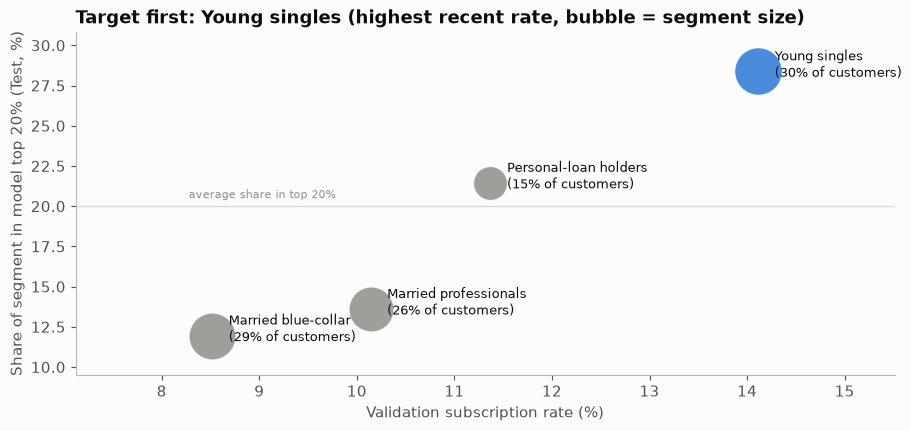

### STP และ 4Ps ที่ได้จากหลักฐานในโน้ตบุ๊กนี้

**Segmentation:** ลูกค้าแบ่งได้ 4 กลุ่ม (Young singles 30%, Married professionals 26%, Personal-loan holders 15%, Married blue-collar 29%) แต่ silhouette ต่ำและอัตราสมัครระหว่างกลุ่มในช่วงเดียวกันต่างกันเพียงไม่กี่จุด จึงใช้กลุ่มเพื่อ **ออกแบบข้อความและข้อเสนอ** ส่วนลำดับการโทรให้คะแนนโมเดลกับประวัติแคมเปญเป็นตัวหลัก

**Targeting:** เริ่มจากรายชื่อที่คะแนนโมเดลสูงสุด และคนที่เคยตอบรับแคมเปญก่อน ในบรรดากลุ่ม K-means กลุ่ม **Young singles** มีอัตราสมัครใน Validation สูงสุด (14.1%) จึงเหมาะเป็นกลุ่มนำร่อง

**Positioning:** เงินฝากประจำเป็น "ที่พักเงินปลอดภัย ดอกเบี้ยแน่นอน" ซึ่งเด่นขึ้นในช่วงที่ตลาดผันผวนและดอกเบี้ยอ้างอิงต่ำ (ดูไทม์ไลน์ 1.3)

| 4Ps | Young singles | Married professionals | Personal-loan holders | Married blue-collar |
|---|---|---|---|---|
| Product | เงินฝากระยะสั้น ฝากเริ่มต้นต่ำ | เงินฝากระยะยาว ผูกกับเป้าหมายครอบครัว | ไม่เน้นเงินฝากก้อน อาจเสนอแบบฝากรายเดือน | เงินฝากระยะสั้น เข้าใจง่าย |
| Price | ไม่ต้องให้ดอกเบี้ยพิเศษสูง ใช้โบนัสฝากครั้งแรก | อัตราขั้นบันไดตามยอด ไม่ลดเกินจำเป็น | เน้นความยืดหยุ่นแทนอัตราสูง | อัตรามาตรฐาน ชูความปลอดภัย |
| Place | ช่องทางมือถือ/ดิจิทัล | โทรนัดหมาย หรือที่สาขา | โทรพร้อมรอบชำระสินเชื่อ | โทร หรือที่สาขาใกล้บ้าน |
| Promotion | ข้อความเรื่องเริ่มออมเร็ว | ข้อความเรื่องวางแผนอนาคตลูก | ข้อความเรื่องจัดการเงินรายเดือน | ข้อความเรื่องความมั่นคง |

**ข้อควรระวัง:** ตาราง 4Ps เป็นแนวทางเชิงตรรกะจากลักษณะกลุ่ม ยังไม่มีข้อมูลยืนยันว่าข้อเสนอแต่ละแบบเพิ่มยอดสมัคร จึงต้องทดลองตาม 6.2


1503

In [40]:
# Segment x model: who ends up at the top of the list?
top20 = select_top_fraction(test_scores[core_model], .20)
seg_test = pd.DataFrame({'segment': segment.iloc[test].to_numpy(), 'top20': top20,
                         'score': test_scores[core_model], 'subscribed': y.iloc[test].to_numpy()})
stp = (seg_test.groupby('segment').agg(test_records=('top20', 'size'), in_top20=('top20', 'mean'),
                                       mean_score=('score', 'mean'), test_rate=('subscribed', 'mean'))
       .join(profile[['share', 'rate_Validation']]).loc[SEG_ORDER])
stp['share_of_top20'] = seg_test[seg_test.top20].segment.value_counts(normalize=True).reindex(SEG_ORDER).fillna(0)
display(stp.round(3)); stp.to_csv(BUSINESS_OUT/'stp_segment_table.csv')

fig, ax = plt.subplots(figsize=(9, 4.2), layout='constrained')
target = stp.rate_Validation.idxmax()
for s, r in stp.iterrows():
    ax.scatter(r.rate_Validation*100, r.in_top20*100, s=r.share*4000, alpha=.85,
               color=HL if s == target else GREY, edgecolor='white')
    ax.annotate(f'{s}\n({r.share:.0%} of customers)', (r.rate_Validation*100, r.in_top20*100),
                textcoords='offset points', xytext=(12, -4), fontsize=9)
ax.axhline(20, color=LIGHT, lw=1); ax.text(ax.get_xlim()[0], 20.5, ' average share in top 20%', fontsize=8, color=GREY)
ax.margins(x=.25, y=.15)
ax.set(xlabel='Validation subscription rate (%)', ylabel='Share of segment in model top 20% (Test, %)',
       title=f'Target first: {target} (highest recent rate, bubble = segment size)')
fig.savefig(BUSINESS_OUT/'07b_stp_bubble.png', dpi=160); plt.show()

stp_text = f"""### STP และ 4Ps ที่ได้จากหลักฐานในโน้ตบุ๊กนี้

**Segmentation:** ลูกค้าแบ่งได้ 4 กลุ่ม ({', '.join(f'{s} {stp.share[s]:.0%}' for s in SEG_ORDER)}) แต่ silhouette ต่ำและอัตราสมัครระหว่างกลุ่มในช่วงเดียวกันต่างกันเพียงไม่กี่จุด จึงใช้กลุ่มเพื่อ **ออกแบบข้อความและข้อเสนอ** ส่วนลำดับการโทรให้คะแนนโมเดลกับประวัติแคมเปญเป็นตัวหลัก

**Targeting:** เริ่มจากรายชื่อที่คะแนนโมเดลสูงสุด และคนที่เคยตอบรับแคมเปญก่อน ในบรรดากลุ่ม K-means กลุ่ม **{target}** มีอัตราสมัครใน Validation สูงสุด ({stp.rate_Validation[target]:.1%}) จึงเหมาะเป็นกลุ่มนำร่อง

**Positioning:** เงินฝากประจำเป็น "ที่พักเงินปลอดภัย ดอกเบี้ยแน่นอน" ซึ่งเด่นขึ้นในช่วงที่ตลาดผันผวนและดอกเบี้ยอ้างอิงต่ำ (ดูไทม์ไลน์ 1.3)

| 4Ps | Young singles | Married professionals | Personal-loan holders | Married blue-collar |
|---|---|---|---|---|
| Product | เงินฝากระยะสั้น ฝากเริ่มต้นต่ำ | เงินฝากระยะยาว ผูกกับเป้าหมายครอบครัว | ไม่เน้นเงินฝากก้อน อาจเสนอแบบฝากรายเดือน | เงินฝากระยะสั้น เข้าใจง่าย |
| Price | ไม่ต้องให้ดอกเบี้ยพิเศษสูง ใช้โบนัสฝากครั้งแรก | อัตราขั้นบันไดตามยอด ไม่ลดเกินจำเป็น | เน้นความยืดหยุ่นแทนอัตราสูง | อัตรามาตรฐาน ชูความปลอดภัย |
| Place | ช่องทางมือถือ/ดิจิทัล | โทรนัดหมาย หรือที่สาขา | โทรพร้อมรอบชำระสินเชื่อ | โทร หรือที่สาขาใกล้บ้าน |
| Promotion | ข้อความเรื่องเริ่มออมเร็ว | ข้อความเรื่องวางแผนอนาคตลูก | ข้อความเรื่องจัดการเงินรายเดือน | ข้อความเรื่องความมั่นคง |

**ข้อควรระวัง:** ตาราง 4Ps เป็นแนวทางเชิงตรรกะจากลักษณะกลุ่ม ยังไม่มีข้อมูลยืนยันว่าข้อเสนอแต่ละแบบเพิ่มยอดสมัคร จึงต้องทดลองตาม 6.2
"""
display(Markdown(stp_text)); (BUSINESS_OUT/'stp_4ps.md').write_text(stp_text, encoding='utf-8')

## 6.2 พิสูจน์ก่อนใช้จริงด้วย A/B test (W1)

> 🔧 **เทคนิค:** ออกแบบ A/B test + สูตรขนาดตัวอย่างแบบสองสัดส่วน (W1)  
> 🎯 **ทำไม:** ข้อมูลย้อนหลังพิสูจน์ผลเชิงเหตุไม่ได้ ต้องทดลองก่อนใช้จริง  
> 🗣️ **พูดว่า:** “ก่อนใช้จริงต้องทำ A/B test ถ้าจะเห็นอัตราสมัครเพิ่ม 3 จุด ต้องใช้กลุ่มละประมาณ 1,900 คน และกันกลุ่มที่ไม่โทรไว้วัดผลจริง”

| องค์ประกอบ | การออกแบบ |
|---|---|
| Hypothesis | รายชื่อจากโมเดลมีอัตราสมัครสูงกว่ารายชื่อแบบเดิม |
| Control / Treatment | รายชื่อแบบเดิม / รายชื่อ 20% แรกของคะแนนโมเดล |
| OEC | Conversion rate และ CPA |
| Holdout | กันลูกค้าส่วนหนึ่งไว้ไม่โทร เพื่อวัดผลที่เกิดจากการโทรจริง (uplift) |

ขนาดตัวอย่างต่อกลุ่มคำนวณด้วยสูตรเปรียบเทียบสองสัดส่วน (α = 5%, power = 80%)

,control_rate,treatment_rate,uplift_pp,n_per_arm
0,0.111,0.121,1.0,16061
1,0.111,0.131,2.0,4165
2,0.111,0.141,3.0,1916
3,0.111,0.161,5.0,736
4,0.111,0.181,7.0,398


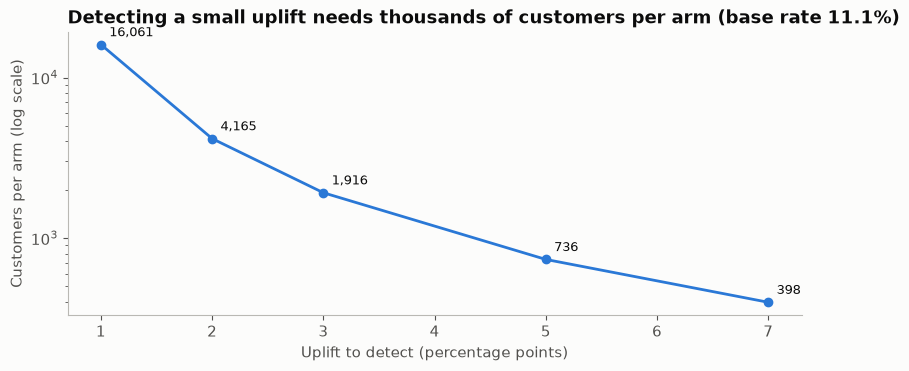

In [41]:
# Two-proportion sample size per arm (alpha 5% two-sided, power 80%)
from statistics import NormalDist
def n_per_arm(p1, p2, alpha=.05, power=.8):
    za, zb = NormalDist().inv_cdf(1-alpha/2), NormalDist().inv_cdf(power)
    pbar = (p1+p2)/2
    return int(np.ceil((za*np.sqrt(2*pbar*(1-pbar)) + zb*np.sqrt(p1*(1-p1)+p2*(1-p2)))**2/(p1-p2)**2))
p_val_random = float(y.iloc[valid].mean())
ab = pd.DataFrame([dict(control_rate=p_val_random, treatment_rate=p_val_random+d, uplift_pp=d*100,
                        n_per_arm=n_per_arm(p_val_random, p_val_random+d)) for d in [.01, .02, .03, .05, .07]])
display(ab.round(3)); ab.to_csv(BUSINESS_OUT/'ab_test_sample_size.csv', index=False)
fig, ax = plt.subplots(figsize=(8, 3.6), layout='constrained')
ax.plot(ab.uplift_pp, ab.n_per_arm, marker='o', color=HL)
for _, r in ab.iterrows():
    ax.annotate(f'{r.n_per_arm:,.0f}', (r.uplift_pp, r.n_per_arm), textcoords='offset points', xytext=(6, 6), fontsize=9)
ax.set_yscale('log')
ax.set(xlabel='Uplift to detect (percentage points)', ylabel='Customers per arm (log scale)',
       title=f'Detecting a small uplift needs thousands of customers per arm (base rate {p_val_random:.1%})')
fig.savefig(BUSINESS_OUT/'09_ab_sample_size.png', dpi=160); plt.show()

## 6.3 สรุปหน้าเดียว

> 🔧 **เทคนิค:** Dashboard 2×2 สี่ข้อความหลัก  
> 🎯 **ทำไม:** สไลด์ปิดที่เล่าเรื่องได้ในภาพเดียว  
> 🗣️ **พูดว่า:** “ภาพเดียวที่เล่าทั้งเรื่อง: ตลาดเปลี่ยน, โมเดลช่วยเรียง, ชนะกฎไม่มาก และจุดหยุดต้องปรับตามสภาวะ”

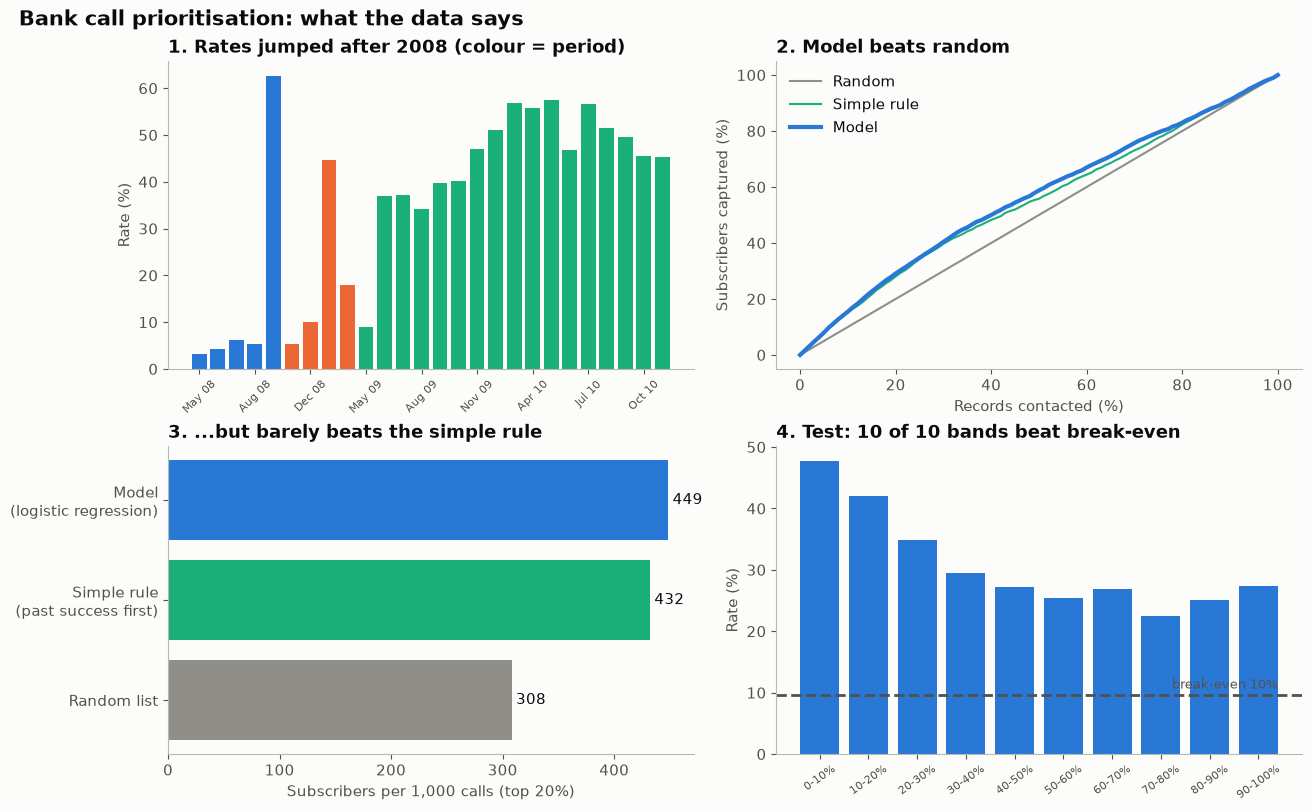

In [42]:
# One-page executive summary figure
fig, axs = plt.subplots(2, 2, figsize=(13, 8), layout='constrained')
a = axs[0, 0]
a.bar(tl_pos, monthly.rate*100, color=[PERIOD_COLORS[s] for s in month_split])
a.set_xticks(tl_pos[::3], tl_labels[::3], rotation=45, fontsize=8)
a.set(title='1. Rates jumped after 2008 (colour = period)', ylabel='Rate (%)')
a = axs[0, 1]
for name, label, c, lw in [('Random expected', 'Random', GREY, 1.5), ('History rule', 'Simple rule', HL2, 1.5), (core_model, 'Model', HL, 3)]:
    cc = test_curves[name]; a.plot(cc.fraction*100, cc.recall*100, color=c, lw=lw, label=label)
a.legend(frameon=False); a.set(title='2. Model beats random', xlabel='Records contacted (%)', ylabel='Subscribers captured (%)')
a = axs[1, 0]
b = a.barh(kpi.method.str.replace(' (', '\n('), kpi.per_1000_calls, color=[GREY, HL2, HL]); a.bar_label(b, fmt='%.0f', padding=3)
a.set(title='3. ...but barely beats the simple rule', xlabel='Subscribers per 1,000 calls (top 20%)')
a = axs[1, 1]
g = deciles[deciles.split.eq('Test')]; be = base.cost_per_customer/base.value_per_subscriber
a.bar(range(len(g)), g.rate*100, color=[HL if r >= be else LIGHT for r in g.rate])
a.axhline(be*100, color=WARN, ls='--'); a.text(9.4, be*100+1, f'break-even {be:.0%}', color=WARN, ha='right', fontsize=9)
a.set_xticks(range(len(g)), g.band, rotation=35, fontsize=8)
a.set(title=f'4. Test: {int((g.rate >= be).sum())} of 10 bands beat break-even', ylabel='Rate (%)')
fig.suptitle('Bank call prioritisation: what the data says', fontsize=15, fontweight='bold', x=.01, ha='left')
fig.savefig(BUSINESS_OUT/'10_executive_summary.png', dpi=160); plt.show()

## 6.4 บทสรุปผู้บริหาร: เสนออะไร ให้ใคร ผ่านช่องทางไหน

> 🔧 **เทคนิค:** Executive summary (เสนออะไร ให้ใคร กี่ราย กี่ครั้ง ช่องทาง พิสูจน์อย่างไร)  
> 🎯 **ทำไม:** ตอบ rubric ข้อบทสรุปและนัยเชิงธุรกิจ  
> 🗣️ **พูดว่า:** “ข้อเสนอของเรา: เริ่มจากคนที่เคยตอบรับก่อน ใช้โมเดลเรียงคนที่เหลือ โทรผ่านมือถือ หยุดเมื่อไม่คุ้ม และพิสูจน์ด้วย A/B test ก่อนขยายผล”

In [43]:
# Executive summary built from the results above
exec_text = f"""**ข้อเสนอ:** เสนอ **เงินฝากประจำ** ในฐานะที่พักเงินปลอดภัย ดอกเบี้ยแน่นอน

| คำถาม | คำตอบ | หลักฐาน |
|---|---|---|
| **ให้ใคร** | เริ่มจากคนที่ **เคยตอบรับแคมเปญก่อน** แล้วเรียงคนที่เหลือด้วยคะแนนโมเดล เน้นวัย **<25 และ 60+** | ประวัติแคมเปญเป็นสัญญาณหลัก (3.6); โมเดลได้ {kpi.per_1000_calls.iloc[2]:.0f} รายต่อ 1,000 สาย เทียบกับสุ่ม {kpi.per_1000_calls.iloc[0]:.0f} (3.9); 60+ สมัคร {r60['Test']:.0%} บน Test (5.3) |
| **กี่ราย** | โทรเมื่ออัตราสมัครที่คาด > ค่าติดต่อ ÷ มูลค่า (สถานการณ์หลัก {base.cost_per_customer/base.value_per_subscriber:.0%}) และปรับตามอัตราสมัครของรอบล่าสุด | สัดส่วนคงที่จาก Validation ได้ {adapt_base.test_fixed_net/1000:,.0f}k บาทบน Test ส่วนเกณฑ์ที่ปรับตามรอบได้ {adapt_base.test_adaptive_net/1000:,.0f}k (4.5) |
| **กี่ครั้ง** | โทรซ้ำเฉพาะเมื่ออัตราต่อสายล่าสุดยังเกิน {CALL_COST/VALUE_BASE:.1%} | สายที่ 5 ได้ {h_t[5]:.0%} เทียบกับ {h_t[1]:.0%} ของสายแรกบน Test (5.1) |
| **ผ่านช่องทางไหน** | **มือถือ** ก่อนโทรศัพท์บ้าน | มือถือได้ผล {ratio.min():.1f}–{ratio.max():.1f} เท่าในทุกช่วง (5.2) |
| **ด้วยข้อเสนอแบบใด** | ข้อความแยกตามกลุ่ม (ดูตาราง 4Ps ใน 6.1) ไม่ต้องให้ดอกเบี้ยพิเศษเกินจำเป็น | — |
| **พิสูจน์อย่างไร** | A/B test: รายชื่อจากโมเดล vs รายชื่อแบบเดิม พร้อม holdout ที่ไม่โทร | ถ้าจะเห็นอัตราสมัครเพิ่ม 3 จุด ต้องใช้กลุ่มละประมาณ {int(ab.set_index('uplift_pp').n_per_arm[3.0]):,} คน (6.2) |

**ข้อจำกัด:** ข้อมูลปี 2008–2010 จากโปรตุเกสช่วงวิกฤตการเงิน, ตัวเลขเงินมาจากแหล่งภายนอก, ทุกข้อเป็นความสัมพันธ์ย้อนหลัง ยังไม่ใช่ผลเชิงเหตุ
"""
display(Markdown(exec_text)); (OUT/'executive_summary.md').write_text(exec_text, encoding='utf-8')

**ข้อเสนอ:** เสนอ **เงินฝากประจำ** ในฐานะที่พักเงินปลอดภัย ดอกเบี้ยแน่นอน

| คำถาม | คำตอบ | หลักฐาน |
|---|---|---|
| **ให้ใคร** | เริ่มจากคนที่ **เคยตอบรับแคมเปญก่อน** แล้วเรียงคนที่เหลือด้วยคะแนนโมเดล เน้นวัย **<25 และ 60+** | ประวัติแคมเปญเป็นสัญญาณหลัก (3.6); โมเดลได้ 449 รายต่อ 1,000 สาย เทียบกับสุ่ม 308 (3.9); 60+ สมัคร 46% บน Test (5.3) |
| **กี่ราย** | โทรเมื่ออัตราสมัครที่คาด > ค่าติดต่อ ÷ มูลค่า (สถานการณ์หลัก 10%) และปรับตามอัตราสมัครของรอบล่าสุด | สัดส่วนคงที่จาก Validation ได้ 1,856k บาทบน Test ส่วนเกณฑ์ที่ปรับตามรอบได้ 2,651k (4.5) |
| **กี่ครั้ง** | โทรซ้ำเฉพาะเมื่ออัตราต่อสายล่าสุดยังเกิน 3.3% | สายที่ 5 ได้ 6% เทียบกับ 16% ของสายแรกบน Test (5.1) |
| **ผ่านช่องทางไหน** | **มือถือ** ก่อนโทรศัพท์บ้าน | มือถือได้ผล 1.4–1.5 เท่าในทุกช่วง (5.2) |
| **ด้วยข้อเสนอแบบใด** | ข้อความแยกตามกลุ่ม (ดูตาราง 4Ps ใน 6.1) ไม่ต้องให้ดอกเบี้ยพิเศษเกินจำเป็น | — |
| **พิสูจน์อย่างไร** | A/B test: รายชื่อจากโมเดล vs รายชื่อแบบเดิม พร้อม holdout ที่ไม่โทร | ถ้าจะเห็นอัตราสมัครเพิ่ม 3 จุด ต้องใช้กลุ่มละประมาณ 1,916 คน (6.2) |

**ข้อจำกัด:** ข้อมูลปี 2008–2010 จากโปรตุเกสช่วงวิกฤตการเงิน, ตัวเลขเงินมาจากแหล่งภายนอก, ทุกข้อเป็นความสัมพันธ์ย้อนหลัง ยังไม่ใช่ผลเชิงเหตุ


1178

# ภาคผนวก

รายละเอียดและการทดลองเสริม ใช้ตอบคำถาม ไม่จำเป็นต้องขึ้นสไลด์

## ก. Model B: ตัวแปรเศรษฐกิจของเดือนก่อนหน้า

> 🔧 **เทคนิค:** เพิ่ม feature แบบ lag 1 เดือน (ตัวแปรเศรษฐกิจ) แล้วทำ ablation เทียบ A vs B  
> 🎯 **ทำไม:** ทดสอบว่าตัวแปรที่ต้นฉบับตัดออกช่วยได้จริงไหม โดยไม่มีข้อมูลอนาคตรั่ว  
> 🗣️ **พูดว่า:** “เราลองใส่ตัวแปรเศรษฐกิจของเดือนก่อนแล้ว มันบอกได้ว่าเดือนไหนดี แต่แยกคนในเดือนเดียวกันไม่ได้ โมเดลหลักจึงไม่ได้ใช้”

ต้นฉบับตัดตัวแปรเศรษฐกิจทั้ง 5 ตัวออก (`emp.var.rate` รายไตรมาส, `cons.price.idx` และ `cons.conf.idx` รายเดือน, `euribor3m` รายวัน, `nr.employed` รายไตรมาส ตามนิยามใน `bank-additional-names.txt`) เพราะไม่แน่ใจว่ารู้ค่าตอนเลือกรายชื่อ ส่วนนี้ลองใส่กลับเข้าไป โดยใช้ **ค่าเฉลี่ยของเดือนก่อนหน้า** ซึ่งรู้แน่นอนแล้ว เพื่อกันข้อมูลอนาคตรั่ว (เดือนแรก พ.ค. 2008 ใช้ค่าของเดือนนั้นเอง)

**ผล:** ช่วยน้อยและไม่สม่ำเสมอ โมเดลหลัก (LR) แย่ลงมาก เพราะ Train เห็น Euribor แค่ช่วง 4–5% แต่ Test อยู่ที่ราว 1% โมเดลเส้นตรงจึงลากเส้นออกไปนอกช่วงที่เคยเห็น ส่วน RF/GB ดีขึ้นเล็กน้อยบน Validation แต่ไม่คงที่บน Test สาเหตุคือคนที่ถูกโทรในเดือนเดียวกันได้ค่าเท่ากัน ตัวแปรนี้จึงบอก "ระดับ" ของอัตราสมัครรายเดือนมากกว่าช่วยแยกคน เราจึงใช้ข้อมูลระดับผ่านการปรับตามรอบใน 4.5 แทน และไม่ได้ใช้ส่วนนี้เปลี่ยนโมเดลหลัก

,model,features,validation_ap,test_ap,test_auc,test_mean_score
0,Logistic regression 10.0,A: customer only,0.174,0.529,0.685,0.135
1,Logistic regression 10.0,B: + macro (prev month),0.099,0.356,0.469,0.125
2,"Gradient boosting (6, 0.05)",A: customer only,0.140,0.485,0.673,0.147
3,"Gradient boosting (6, 0.05)",B: + macro (prev month),0.148,0.445,0.642,0.169
4,"Random forest (8, 20)",A: customer only,0.136,0.477,0.674,0.148
5,"Random forest (8, 20)",B: + macro (prev month),0.155,0.484,0.697,0.197


Best Model B on Validation: Random forest (8, 20) AP=0.155 vs core model AP=0.174 -> core model kept


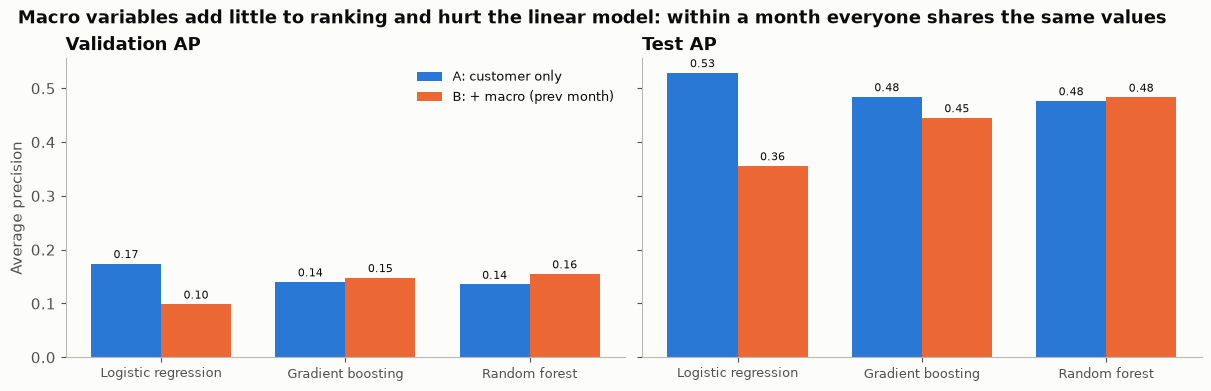

In [44]:
# Model B = Model A features + previous-month macro averages
MACRO = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
macro_month = raw[MACRO].groupby(year_month).mean()
macro_prev = macro_month.shift(1); macro_prev.iloc[0] = macro_month.iloc[0]
X_B = X.join(macro_prev.reindex(year_month).set_axis(X.index).add_suffix('_prev_month'))
NUM_B = NUM + [c + '_prev_month' for c in MACRO]
model_b_rows = []
for name in family_models:
    kind, param = spec_by_id[name]
    for label, XX, num in [('A: customer only', X, NUM), ('B: + macro (prev month)', X_B, NUM_B)]:
        mv = make_model(kind, param, CAT, num).fit(XX.iloc[train], y.iloc[train])
        sv = mv.predict_proba(XX.iloc[valid])[:, 1]
        mt = make_model(kind, param, CAT, num).fit(XX.iloc[:cut2], y.iloc[:cut2])
        st = mt.predict_proba(XX.iloc[test])[:, 1]
        model_b_rows.append(dict(model=name, features=label,
                                 validation_ap=average_precision_score(y.iloc[valid], sv),
                                 test_ap=average_precision_score(y.iloc[test], st),
                                 test_auc=roc_auc_score(y.iloc[test], st), test_mean_score=st.mean()))
model_b = pd.DataFrame(model_b_rows); display(model_b.round(3))
model_b.to_csv(MODEL_OUT/'model_b_macro_comparison.csv', index=False)
best_b = model_b[model_b.features.str.startswith('B')].sort_values('validation_ap', ascending=False).iloc[0]
core_val_ap = float(validation_metrics.set_index('model').ap[core_model])
print(f'Best Model B on Validation: {best_b.model} AP={best_b.validation_ap:.3f} vs core model AP={core_val_ap:.3f} '
      f'-> core model {"kept" if core_val_ap >= best_b.validation_ap else "would lose; reported, not switched"}')

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), layout='constrained', sharey=True)
for ax, col, title in [(axs[0], 'validation_ap', 'Validation AP'), (axs[1], 'test_ap', 'Test AP')]:
    pv = model_b.pivot(index='model', columns='features', values=col).loc[family_models]
    xs = np.arange(len(pv))
    for j, (f, c) in enumerate(zip(pv.columns, [HL, '#eb6834'])):
        b = ax.bar(xs + (j - .5)*.38, pv[f], .38, color=c, label=f); ax.bar_label(b, fmt='%.2f', fontsize=8, padding=2)
    ax.set_xticks(xs, [m.split(' ')[0] + ' ' + m.split(' ')[1] for m in pv.index], fontsize=9); ax.set_title(title)
axs[0].legend(frameon=False, fontsize=9); axs[0].set_ylabel('Average precision')
fig.suptitle('Macro variables add little to ranking and hurt the linear model: within a month everyone shares the same values',
             fontweight='bold', x=.01, ha='left')
fig.savefig(MODEL_OUT/'05b_model_b_macro.png', dpi=160); plt.show()

## ข. Importance ทีละตัวแปร

> 🔧 **เทคนิค:** Permutation importance ทีละตัวแปร  
> 🎯 **ทำไม:** อธิบายว่าโมเดลพึ่งตัวแปรไหน (ไม่ใช่สาเหตุ)  
> 🗣️ **พูดว่า:** “ตัวแปรที่โมเดลพึ่งมากที่สุดคือประวัติการติดต่อในแคมเปญก่อน”

สลับค่าทีละตัวแปรบน Validation แล้วดูว่า AP ลดลงเท่าไร ผลนี้อธิบายโมเดล ไม่ได้บอกว่าตัวแปรเป็นสาเหตุ ตัวแปรที่บอกเรื่องเดียวกันอาจแบ่งความสำคัญกันเอง จึงดูแบบกลุ่มใน 3.6 ประกอบ

,feature,importance,sd
7,previous,0.041739,0.000651
8,poutcome,0.035493,0.001681
9,pdays_band,0.034278,0.001450
1,job,0.017054,0.002331
4,default,0.006539,0.001108
0,age,0.004260,0.002437
2,marital,0.002408,0.001252
6,loan,-0.000891,0.001232
5,housing,-0.001093,0.000980
3,education,-0.002750,0.003731


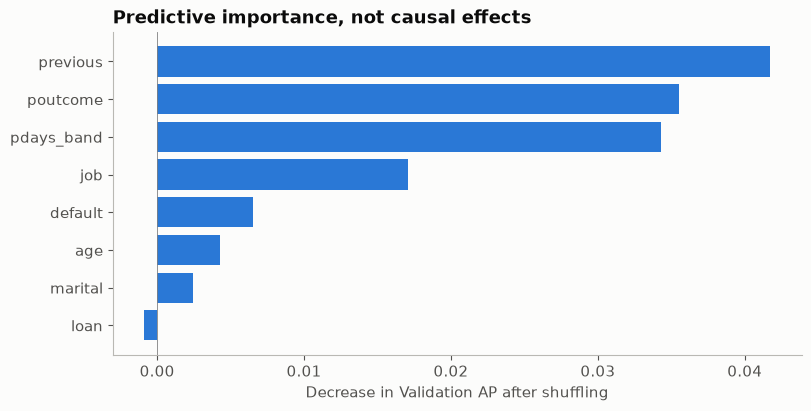

In [45]:
importance=permutation_importance(fitted[core_model],X.iloc[valid],y.iloc[valid],
    scoring='average_precision',n_repeats=3,random_state=SEED,n_jobs=1)
imp=pd.DataFrame(dict(feature=X.columns,importance=importance.importances_mean,
    sd=importance.importances_std)).sort_values('importance',ascending=False)
display(imp);imp.to_csv(MODEL_OUT/'validation_importance.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
g=imp.head(8).iloc[::-1]
ax.barh(g.feature,g.importance,color=HL);ax.axvline(0,color='gray',lw=.6)
ax.set(xlabel='Decrease in Validation AP after shuffling',title='Predictive importance, not causal effects')
fig.savefig(MODEL_OUT/'07_importance.png',dpi=160);plt.show()


## ค. มูลค่าสุทธิตามสัดส่วนที่โทร

> 🔧 **เทคนิค:** เส้นมูลค่าสุทธิตามสัดส่วนการโทร  
> 🎯 **ทำไม:** เห็นทั้งเส้นว่าคุ้มหรือไม่คุ้มตรงไหน ไม่ใช่แค่จุดเดียว  
> 🗣️ **พูดว่า:** “เส้นมูลค่าบน Test ยังขึ้นต่อไปจนเกือบสุดทาง ไม่ได้หยุดตรงจุดที่เลือกไว้”

มูลค่าสุทธิเมื่อเลือก 0–100% ในสถานการณ์หลัก ทั้ง Validation และ Test เส้นตั้งคือจุดหยุดที่เลือกจาก Validation

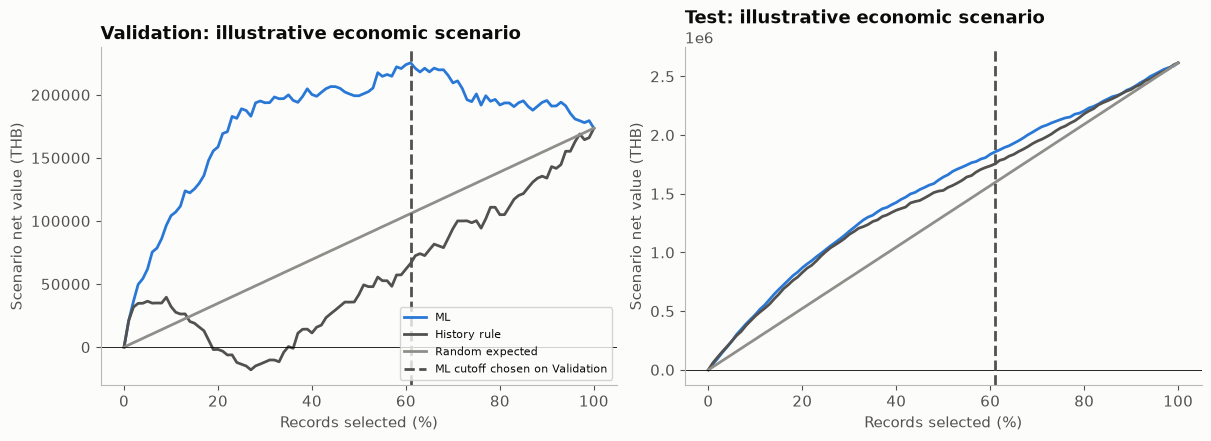

In [46]:
econ_colors={'ML':HL,'History rule':INK2,'Random expected':GREY}
fig,axes=plt.subplots(1,2,figsize=(12,4.3),layout='constrained')
for ax,split_name,curves in [(axes[0],'Validation',validation_curves),(axes[1],'Test',test_curves)]:
    for name,label in [(base.model,'ML'),('History rule','History rule'),('Random expected','Random expected')]:
        c=with_economics(curves[name],base.cost_per_customer,base.value_per_subscriber)
        ax.plot(c.fraction*100,c.scenario_net_value,label=label,color=econ_colors[label])
    ax.axhline(0,color='black',lw=.6)
    ax.axvline(base.fraction*100,color=WARN,ls='--',label='ML cutoff chosen on Validation')
    ax.set(title=f'{split_name}: illustrative economic scenario',xlabel='Records selected (%)',ylabel='Scenario net value (THB)')
axes[0].legend(fontsize=8)
fig.savefig(BUSINESS_OUT/'05_economic_curves.png',dpi=160);plt.show()


## ง. ความไวต่อสมมติฐาน (27 สถานการณ์ + ขนาดรอบ)

> 🔧 **เทคนิค:** Scenario / sensitivity analysis (27 สถานการณ์ + ขนาดรอบ)  
> 🎯 **ทำไม:** ดูว่าคำตอบไวต่อสมมติฐานแค่ไหน  
> 🗣️ **พูดว่า:** “คำตอบว่าควรโทรกี่รายไวต่อมูลค่าต่อลูกค้ามาก ขยับสมมติฐานนิดเดียว คำตอบเปลี่ยนตั้งแต่ไม่โทรเลยจนถึงโทรเกือบทุกคน ธนาคารจึงต้องใส่ตัวเลขจริงของตัวเอง”

ครบ 27 สถานการณ์ และลองขนาดรอบ 250 / 500 / 1,000 ราย โดยใช้โมเดลหลักตัวเดิม

,cost_per_call,assumed_calls,value_per_subscriber,model,fraction,scenario_net_value
0,25.0,1.0,500.0,Logistic regression 10.0,0.99,1052625.0
1,25.0,1.0,1500.0,Logistic regression 10.0,1.00,3604050.0
2,25.0,1.0,3000.0,Logistic regression 10.0,1.00,7414050.0
3,25.0,2.9,500.0,Logistic regression 10.0,0.13,173425.0
4,25.0,2.9,1500.0,Logistic regression 10.0,0.99,3178262.5
5,25.0,2.9,3000.0,Logistic regression 10.0,1.00,7022745.0
6,25.0,4.0,500.0,Logistic regression 10.0,0.03,36800.0
7,25.0,4.0,1500.0,Logistic regression 10.0,0.99,2954000.0
8,25.0,4.0,3000.0,Logistic regression 10.0,1.00,6796200.0
9,50.0,1.0,500.0,Logistic regression 10.0,0.61,610250.0


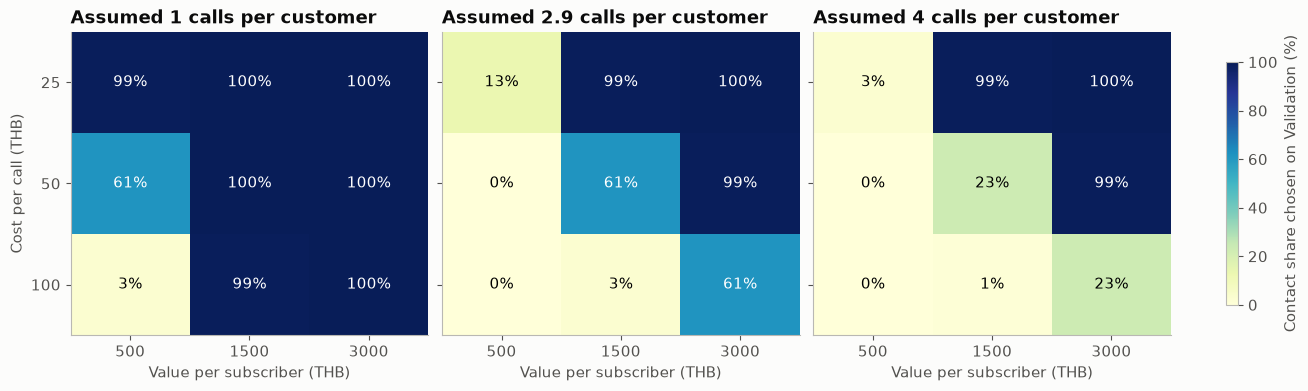

,fraction,selected,found,positive_total,precision,recall,random_expected,lift,contact_cost,scenario_net_value,random_expected_net_value,batch_size,model,validation_net_value
0,0.46,3789.0,1410.0,2540.0,0.372130,0.555118,1168.164034,1.207022,549405.0,1565595.0,1.202841e+06,250,Logistic regression 10.0,193095.0
1,0.61,5025.0,1723.0,2540.0,0.342886,0.678346,1549.311513,1.112107,728625.0,1855875.0,1.595342e+06,500,Logistic regression 10.0,225375.0
2,0.62,5107.0,1735.0,2540.0,0.339730,0.683071,1574.524706,1.101920,740515.0,1861985.0,1.621272e+06,1000,Logistic regression 10.0,225485.0


In [47]:
sensitivity=test_results[test_results.family.eq('ML')].merge(
    scenarios,on=['scenario','cost_per_customer','value_per_subscriber'])
display(sensitivity[['cost_per_call','assumed_calls','value_per_subscriber',
    'model','fraction','scenario_net_value']])
sensitivity.to_csv(BUSINESS_OUT/'scenario_sensitivity.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(13,3.8),layout='constrained',sharey=True)
for ax,m in zip(axes,CALLS_PER_CUSTOMER):
    t=sensitivity[sensitivity.assumed_calls.eq(m)].pivot(index='cost_per_call',columns='value_per_subscriber',values='fraction')
    im=ax.imshow(t.to_numpy()*100,vmin=0,vmax=100,cmap='YlGnBu',aspect='auto')
    ax.set_xticks(range(len(t.columns)),[f'{v:g}' for v in t.columns])
    ax.set_yticks(range(len(t.index)),[f'{v:g}' for v in t.index])
    ax.set(title=f'Assumed {m:g} calls per customer',xlabel='Value per subscriber (THB)')
    for i in range(len(t)):
        for j in range(len(t.columns)):
            ax.text(j,i,f'{t.iloc[i,j]:.0%}',ha='center',va='center',color='white' if t.iloc[i,j]>.55 else 'black')
axes[0].set_ylabel('Cost per call (THB)')
fig.colorbar(im,ax=axes,label='Contact share chosen on Validation (%)',shrink=.8)
fig.savefig(BUSINESS_OUT/'06_sensitivity.png',dpi=160);plt.show()
batch_rows=[]
for size in [250,500,1000]:
    parts=[]
    for name in [core_model]:
        score=val_scores[name]
        c=with_economics(capacity_curve(y.iloc[valid],score,size),base.cost_per_customer,base.value_per_subscriber)
        c['model']=name;parts.append(c)
    policy=choose_policy(pd.concat(parts,ignore_index=True))
    c=with_economics(capacity_curve(y.iloc[test],test_scores[policy.model],size),base.cost_per_customer,base.value_per_subscriber)
    row=c.loc[np.isclose(c.fraction,policy.fraction)].iloc[0].to_dict()
    row.update(batch_size=size,model=policy.model,validation_net_value=policy.scenario_net_value)
    batch_rows.append(row)
batch_sensitivity=pd.DataFrame(batch_rows);display(batch_sensitivity)
batch_sensitivity.to_csv(BUSINESS_OUT/'batch_size_sensitivity.csv',index=False)


## จ. จุดหยุดใช้ข้ามช่วงได้ไหม

> 🔧 **เทคนิค:** Walk-forward ของนโยบาย (ฝึก → เลือกจุดหยุด → ประเมิน 3 รอบ)  
> 🎯 **ทำไม:** ตรวจว่าจุดหยุดเสถียรข้ามช่วงไหม  
> 🗣️ **พูดว่า:** “เมื่อลองย้อนหลังหลายช่วง จุดหยุดที่ดีที่สุดก็เปลี่ยนไปเรื่อย ๆ ยืนยันว่าต้องปรับตามรอบ”

ฝึกด้วยข้อมูลเก่า เลือกสัดส่วนในช่วงถัดไป แล้วประเมินช่วงถัดจากนั้น 3 รอบก่อนถึง Test

In [48]:
temporal_rows=[]
for train_end,val_end,eval_end in [(.4,.5,.6),(.5,.6,.7),(.6,.7,.8)]:
    a,b,c=[int(n*f) for f in [train_end,val_end,eval_end]]
    m=make_model(*spec_by_id[base.model]).fit(X.iloc[:a],y.iloc[:a])
    scores=m.predict_proba(X.iloc[a:b])[:,1]
    curve=with_economics(capacity_curve(y.iloc[a:b],scores),base.cost_per_customer,base.value_per_subscriber)
    curve['model']=base.model;policy=choose_policy(curve)
    m=make_model(*spec_by_id[base.model]).fit(X.iloc[:b],y.iloc[:b])
    scores=m.predict_proba(X.iloc[b:c])[:,1]
    curve=with_economics(capacity_curve(y.iloc[b:c],scores),base.cost_per_customer,base.value_per_subscriber)
    row=curve.loc[np.isclose(curve.fraction,policy.fraction)].iloc[0].to_dict()
    row.update(train_end=train_end,validation_end=val_end,evaluation_end=eval_end,
        evaluation_rate=float(y.iloc[b:c].mean()),validation_net_value=policy.scenario_net_value)
    temporal_rows.append(row)
temporal=pd.DataFrame(temporal_rows);display(temporal)
temporal.to_csv(BUSINESS_OUT/'temporal_robustness.csv',index=False)


,fraction,selected,found,positive_total,precision,recall,random_expected,lift,contact_cost,scenario_net_value,random_expected_net_value,train_end,validation_end,evaluation_end,evaluation_rate,validation_net_value
0,0.00,0.0,0.0,225.0,NaN,0.000000,0.000000,NaN,0.0,0.0,0.000000,0.4,0.5,0.6,0.054638,0.0
1,0.01,41.0,9.0,418.0,0.219512,0.021531,4.164034,2.161366,5945.0,7555.0,301.050420,0.5,0.6,0.7,0.101481,3055.0
2,0.66,2718.0,377.0,494.0,0.138705,0.763158,326.017311,1.156380,394110.0,171390.0,94915.966387,0.6,0.7,0.8,0.119932,70890.0


## ฉ. รายชื่อที่ถูกเลือกเป็นใคร

> 🔧 **เทคนิค:** Profiling รายชื่อที่ถูกเลือกเทียบรายชื่อทั้งหมด  
> 🎯 **ทำไม:** ดูว่านโยบายเลือกคนแบบไหน และตรวจความลำเอียง  
> 🗣️ **พูดว่า:** “นักศึกษาและผู้เกษียณเกือบทุกคนถูกเลือก (100% และ 99%) แต่รวมกันเป็นแค่ราวหนึ่งในสี่ของรายชื่อที่เลือก ซึ่งสอดคล้องกับ insight เรื่องอายุในบทที่ 5 (5.3)”

รายชื่อที่ผ่านจุดหยุดในสถานการณ์หลักมีอาชีพและประวัติแคมเปญแบบไหน เทียบกับรายชื่อทั้งหมด

In [49]:
chosen=select_top_fraction(test_scores[base.model],base.fraction)
audit=raw.iloc[test].copy()
audit['source_row']=np.arange(cut2+1,n+1)
audit['ranking_score']=test_scores[base.model]
audit['selected_base_scenario']=chosen
audit.to_csv(BUSINESS_OUT/'test_scored_records.csv',index=False)
profiles=[]
for col in ['job','poutcome','marital']:
    t=audit.groupby(col,observed=True).agg(available=('selected_base_scenario','size'),
        selected=('selected_base_scenario','sum'))
    t['selection_rate']=t.selected/t.available
    t['share_of_selected']=t.selected/max(int(chosen.sum()),1)
    t['available_share']=t.available/len(audit)
    t['feature']=col;t['category']=t.index.astype(str)
    profiles.append(t.reset_index(drop=True))
profiles=pd.concat(profiles,ignore_index=True)
display(profiles);profiles.to_csv(BUSINESS_OUT/'selected_group_profiles.csv',index=False)


,available,selected,selection_rate,share_of_selected,available_share,feature,category
0,2382,1594,0.669186,0.317214,0.289148,job,admin.
1,1295,518,0.400000,0.103085,0.157198,job,blue-collar
2,195,97,0.497436,0.019303,0.023671,job,entrepreneur
3,180,48,0.266667,0.009552,0.021850,job,housemaid
4,524,292,0.557252,0.058109,0.063608,job,management
5,730,722,0.989041,0.143682,0.088614,job,retired
6,265,195,0.735849,0.038806,0.032168,job,self-employed
7,644,234,0.363354,0.046567,0.078174,job,services
8,528,528,1.000000,0.105075,0.064093,job,student
9,1166,671,0.575472,0.133532,0.141539,job,technician


## ช. รายงานละเอียดบทที่ 4 และไฟล์สรุป

> 🔧 **เทคนิค:** รายงานอัตโนมัติจากผลที่คำนวณได้ (ตัวเลขใน f-string)  
> 🎯 **ทำไม:** ข้อความตรงกับตัวเลขเสมอเมื่อรันใหม่  
> 🗣️ **พูดว่า:** “สรุปบทที่ 4: โมเดลช่วยเรียงลำดับ แต่จำนวนที่ควรโทรต้องมาจากต้นทุน มูลค่า และอัตราสมัครล่าสุด”

In [50]:
base_overall=locked[(locked.scenario.eq(BASE_SCENARIO)) & locked.family.eq('Overall')].iloc[0]
same=same_capacity[same_capacity.scenario.eq(BASE_SCENARIO)]
random_same=same[same.model.eq('Random expected')].iloc[0]
near=near_best[near_best.scenario.eq(BASE_SCENARIO)].iloc[0]
contact_all_value=int(y.iloc[test].sum())*base.value_per_subscriber-len(y.iloc[test])*base.cost_per_customer
zero_temporal=int(temporal.fraction.eq(0).sum())
report=f"""### บทที่ 4 ได้เห็นตัวอย่างการใช้งานอะไรเพิ่ม?

เราสมมติว่าติดต่อหนึ่งรายใช้เงิน **{base.cost_per_customer:,.0f} บาท** และผู้สมัครหนึ่งรายให้มูลค่าสุทธิ **{base.value_per_subscriber:,.0f} บาท** ก่อนหักค่าติดต่อ

เราใช้โมเดลหลัก **{core_model}** ที่เลือกจาก AP ในบทที่ 3 คงที่ แล้วลองหาจำนวนที่ติดต่อบน Validation สำหรับตัวเลขชุดนี้ ได้สัดส่วน **{base.fraction:.0%}** ช่วงที่ได้ผลใกล้กันอยู่ที่ {near.near_best_min:.0%}–{near.near_best_max:.0%} ช่วงนี้เป็นเกณฑ์ที่เราตั้งไว้ช่วยเทียบผล ไม่ใช่ช่วงความเชื่อมั่นทางสถิติ เมื่อเทียบรวมกับกฎง่ายและการสุ่ม วิธีที่ชนะบน Validation คือ **{base_overall.model}** โดยเลือก {base_overall.fraction:.0%}

พอเอากฎของโมเดลไปใช้กับ Test เราเลือกรายชื่อ {base_test.selected:,.0f} รายการ และพบผู้สมัครย้อนหลัง {base_test.found:,.0f} ราย คิดเป็น {base_test.recall:.1%} ของผู้สมัครทั้งหมดใน Test ได้มูลค่าหลังหักค่าติดต่อในแบบทดลอง **{base_test.scenario_net_value:,.0f} บาท** ส่วนการสุ่มที่จำนวนรายชื่อเท่ากันได้เฉลี่ย {random_same.scenario_net_value:,.0f} บาท

**แต่มีเรื่องสำคัญที่ต้องเล่าต่อ:** ถ้าติดต่อทุกคนใน Test จะได้มูลค่าตามสูตร {contact_all_value:,.0f} บาท ขณะที่กฎของโมเดลที่เลือกไว้ได้ {base_test.scenario_net_value:,.0f} บาท เราแสดงความต่างนี้เพื่อดูว่ากฎใช้ข้ามช่วงได้ดีไหม โดยไม่ย้อนกลับไปเปลี่ยนจุดหยุดจากผล Test

เมื่อเช็กข้อมูลอีก 3 ช่วงก่อน Test มี {zero_temporal} รอบที่เลือกไม่ติดต่อใครเลย ส่วนเมื่อมองครบทั้ง 27 ชุดต้นทุนและมูลค่า โมเดลเลือกไม่ติดต่อบน Validation {int((locked[locked.family.eq('ML')].fraction==0).sum())} กรณี

**ถ้าเปลี่ยนเป็นเกณฑ์ที่ปรับตามรอบล่าสุด (4.5):** บน Test สถานการณ์เดียวกันได้ **{adapt_base['test_adaptive_net']:,.0f} บาท** เทียบกับ {base_test.scenario_net_value:,.0f} บาทของสัดส่วนคงที่ และ {contact_all_value:,.0f} บาทถ้าโทรทุกคน แต่บน Validation วิธีเดียวกันได้ {adapt_base['validation_adaptive_net']:,.0f} บาท จาก 27 สถานการณ์ วิธีนี้ชนะสัดส่วนคงที่บน Test {adapt_wins_test} กรณี และบน Validation {adapt_wins_val} กรณี จึงเป็นทางเลือกที่น่าทดลอง แต่ยังไม่ควรสรุปว่าดีกว่าเสมอ

**แล้วควรสรุปยังไง?** การเรียงรายชื่ออาจช่วยได้เมื่อเลือกจำนวนเท่ากัน แต่จำนวนที่ควรติดต่อยังเปลี่ยนมากตามต้นทุนและช่วงข้อมูล เราจึงยังไม่ควรบอกว่าธนาคารต้องติดต่อ {base.fraction:.0%} เสมอไป เงินที่แสดงทั้งหมดก็คำนวณจากผลย้อนหลัง ยังไม่ใช่กำไรที่พิสูจน์แล้วว่าเกิดเพิ่มเพราะโทร

**ถ้าจะทำต่อ:** ใส่ต้นทุนและมูลค่าจริง ลองใช้งานกับกลุ่มเล็กที่มีกลุ่มควบคุม และติดตามผลเป็นระยะ ก่อนขยายไปใช้กับรายชื่อทั้งหมด
"""
display(Markdown(report))
(BUSINESS_OUT/'story_results.md').write_text(report,encoding='utf-8')
summary=dict(source_url=SOURCE_URL,source_sha256=hashlib.sha256(DATA.read_bytes()).hexdigest(),
    rows=n,seed=SEED,batch_size=BATCH_SIZE,base_scenario=BASE_SCENARIO,
    base_model=base.model,model_selection_metric='Validation AP, independent of costs',validation_fraction=float(base.fraction),
    test_net_value=float(base_test.scenario_net_value),
    assumptions='Illustrative costs/values; retrospective observed-outcome accounting, not causal profit',
    test_previously_inspected=True,
    adaptive_window_batches=W_BEST,test_adaptive_net_value=float(adapt_base['test_adaptive_net']),
    versions=dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,sklearn=sklearn.__version__))
(BUSINESS_OUT/'summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print('Outputs saved to:',OUT)

assert base.model==core_model
combined_report=model_report+'\n\n'+report
(OUT/'story_results.md').write_text(combined_report,encoding='utf-8')
(OUT/'model_selection.json').write_text(json.dumps(model_lock,indent=2),encoding='utf-8')


### บทที่ 4 ได้เห็นตัวอย่างการใช้งานอะไรเพิ่ม?

เราสมมติว่าติดต่อหนึ่งรายใช้เงิน **145 บาท** และผู้สมัครหนึ่งรายให้มูลค่าสุทธิ **1,500 บาท** ก่อนหักค่าติดต่อ

เราใช้โมเดลหลัก **Logistic regression 10.0** ที่เลือกจาก AP ในบทที่ 3 คงที่ แล้วลองหาจำนวนที่ติดต่อบน Validation สำหรับตัวเลขชุดนี้ ได้สัดส่วน **61%** ช่วงที่ได้ผลใกล้กันอยู่ที่ 60%–61% ช่วงนี้เป็นเกณฑ์ที่เราตั้งไว้ช่วยเทียบผล ไม่ใช่ช่วงความเชื่อมั่นทางสถิติ เมื่อเทียบรวมกับกฎง่ายและการสุ่ม วิธีที่ชนะบน Validation คือ **Logistic regression 10.0** โดยเลือก 61%

พอเอากฎของโมเดลไปใช้กับ Test เราเลือกรายชื่อ 5,025 รายการ และพบผู้สมัครย้อนหลัง 1,723 ราย คิดเป็น 67.8% ของผู้สมัครทั้งหมดใน Test ได้มูลค่าหลังหักค่าติดต่อในแบบทดลอง **1,855,875 บาท** ส่วนการสุ่มที่จำนวนรายชื่อเท่ากันได้เฉลี่ย 1,595,342 บาท

**แต่มีเรื่องสำคัญที่ต้องเล่าต่อ:** ถ้าติดต่อทุกคนใน Test จะได้มูลค่าตามสูตร 2,615,490 บาท ขณะที่กฎของโมเดลที่เลือกไว้ได้ 1,855,875 บาท เราแสดงความต่างนี้เพื่อดูว่ากฎใช้ข้ามช่วงได้ดีไหม โดยไม่ย้อนกลับไปเปลี่ยนจุดหยุดจากผล Test

เมื่อเช็กข้อมูลอีก 3 ช่วงก่อน Test มี 1 รอบที่เลือกไม่ติดต่อใครเลย ส่วนเมื่อมองครบทั้ง 27 ชุดต้นทุนและมูลค่า โมเดลเลือกไม่ติดต่อบน Validation 4 กรณี

**ถ้าเปลี่ยนเป็นเกณฑ์ที่ปรับตามรอบล่าสุด (4.5):** บน Test สถานการณ์เดียวกันได้ **2,650,885 บาท** เทียบกับ 1,855,875 บาทของสัดส่วนคงที่ และ 2,615,490 บาทถ้าโทรทุกคน แต่บน Validation วิธีเดียวกันได้ 299,795 บาท จาก 27 สถานการณ์ วิธีนี้ชนะสัดส่วนคงที่บน Test 18 กรณี และบน Validation 12 กรณี จึงเป็นทางเลือกที่น่าทดลอง แต่ยังไม่ควรสรุปว่าดีกว่าเสมอ

**แล้วควรสรุปยังไง?** การเรียงรายชื่ออาจช่วยได้เมื่อเลือกจำนวนเท่ากัน แต่จำนวนที่ควรติดต่อยังเปลี่ยนมากตามต้นทุนและช่วงข้อมูล เราจึงยังไม่ควรบอกว่าธนาคารต้องติดต่อ 61% เสมอไป เงินที่แสดงทั้งหมดก็คำนวณจากผลย้อนหลัง ยังไม่ใช่กำไรที่พิสูจน์แล้วว่าเกิดเพิ่มเพราะโทร

**ถ้าจะทำต่อ:** ใส่ต้นทุนและมูลค่าจริง ลองใช้งานกับกลุ่มเล็กที่มีกลุ่มควบคุม และติดตามผลเป็นระยะ ก่อนขยายไปใช้กับรายชื่อทั้งหมด


Outputs saved to: /Users/tpoot/Desktop/3_data_science_business_analytics/mini_project2/results_model_and_business


287

## ซ. เตรียมตอบคำถาม

- **ทำไมเลือกโมเดลด้วย AP?** เราสนใจว่าผู้สมัครอยู่ต้นรายชื่อหรือเปล่า และไม่อยากผูกการเลือกโมเดลไว้กับค่าโทรสมมติหรือสัดส่วนจุดเดียว
- **โมเดลดีกว่ากฎง่าย ๆ จริงไหม?** ดีกว่าเล็กน้อยในแบบแบ่งหลัก (3.4) แต่ไม่เสถียรเมื่อเปลี่ยนวิธีแบ่ง (3.8) ประโยชน์หลักมาจากประวัติแคมเปญ
- **ทำไมไม่สุ่มแบ่งข้อมูล?** การสุ่มให้ผลดีเกินจริง เพราะได้เห็นข้อมูลอนาคตตอนฝึก (3.8)
- **ต้นทุนมาจากไหน?** ดูตารางแหล่งอ้างอิงใน 1.4 และ 27 สถานการณ์ใน ภาคผนวก ง
- **ตัวเลขเงินคือกำไรที่การโทรสร้างเพิ่มไหม?** ยังไม่ใช่ ต้องทำ A/B test พร้อม holdout (6.2)
- **ทำไมไม่ใส่ตัวแปรเศรษฐกิจ?** ลองแล้วใน ภาคผนวก ก ไม่ช่วยเรียงลำดับ
- **ทำไม K = 4 และ silhouette ต่ำ?** เลือกให้ตีความได้ silhouette ต่ำแปลว่ากลุ่มซ้อนกัน จึงใช้กลุ่มออกแบบข้อความ ไม่ใช้จัดลำดับการโทร
- **ทำไม K-means ไม่มีกลุ่มผู้สูงอายุ?** Train มี 60+ เพียง 0.7% ลูกค้าวัยนี้เพิ่งเพิ่มขึ้นในช่วงหลัง (5.3)
- **ทำไมผลแต่ละช่วงต่างกันมาก?** อัตราสมัครต่างกันจริงตามสภาวะตลาด (1.3) จึงไม่รับประกันผลในอนาคต
- **เคยเห็นผล Test มาก่อนไหม?** เคยในเวอร์ชันก่อน จึงไม่อ้างว่าไม่เคยเห็น แต่การเลือกโมเดลและจุดหยุดทำบน Validation ทั้งหมด

## ฌ. บันทึกการแก้ไขจากต้นฉบับ

ต้นฉบับเก็บไว้ที่ `backup/Bank_Model_and_Business_Scenarios_original_2026-11-10.ipynb` สิ่งที่เปลี่ยน: แปลง `pdays` ใหม่, เพิ่ม Gradient Boosting, importance แบบกลุ่ม, เทียบกับกฎแบบ bootstrap, ตรวจข้ามเวลา 5 รอบ, ทดลองวิธีแบ่งข้อมูล, สมมติฐานเงินจากแหล่งอ้างอิง, เกณฑ์ที่ปรับตามรอบ, K-means + STP/4Ps, A/B test, บท insight ฉบับนี้เรียงบทใหม่แบบเล่าเรื่อง (ฉบับที่คงลำดับหัวข้อตามต้นฉบับคือ `Bank_Model_and_Business_Scenarios.ipynb`)